# MultiRocket — Experimental Improvements and Critical Evaluation

This shared notebook investigates the predictive-performance, computational-efficiency and robustness trade-offs of MultiRocket on time-series classification. Each experiment presents its own research question, method, observations, comparison and limitations. Numerical discussion refers to **saved outputs** where available; unexecuted sections are explicitly marked.

## Experiment Guide

| Label | Focus |
|---|---|
| Baseline | Original MultiRocket reference on the Crop dataset |
| A | Direct feature-budget reduction and accuracy–efficiency trade-off |
| B | Post-extraction feature selection using ANOVA, Mutual Information and Random Selection |
| C1 | Leave-one-original-pooling-operator-out ablation (PPV, LSPV, MPV, MIPV) |
| C2 | Direct MPV removal from feature generation, including equivalence verification and repeated-seed benchmarking |
| C3 | Diagnosing No-MPV runtime overhead through stage-specific timing and memory analysis |
| C4 | Equal-feature-count comparison between original MultiRocket and No-MPV |
| E | Alternative downstream classifiers: Ridge, Extra Trees and CatBoost |
| F | Extending MultiRocket with additional pooling operators (TP-PPV, LSE and GeM) |
| G | Evaluating new-only pooling operators independently of the original operators |
| D | Robustness to noisy, corrupted and incomplete time series |
| Cross-dataset | Generalisation sanity checks on Coffee and ECG200 |
| Final Enhanced Model Evaluation (Stage A) | Comparing original and enhanced feature representations across Ridge, Logistic Regression and Extra Trees, followed by final model selection |


## 0. Setup and runtime configuration
*Implementation and experimental evaluation: Tavishi*


The final experimental protocol uses **five fixed seeds** (`SEEDS = [0, 1, 2, 3, 4]`) for the repeated-seed experiments (feature budget, feature selection, pooling ablation, direct MPV removal, and corruption robustness).

The direct feature-budget experiment includes 1,000, 1,250, 2,500, 5,000 and 50,000 requested features. The 50,000-feature condition is deliberately retained as a high-budget reference and may be the most expensive condition. Do not silently omit it from a final report.

Requested feature budgets may not exactly match actual output dimensions because MultiRocket's implementation and time-series length determine the number of valid features. All reported feature counts must therefore use the measured matrix dimensions.


In [1]:
import os, sys, time, gc, warnings, importlib, re
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from numba import njit
from scipy.ndimage import median_filter, uniform_filter1d
from scipy.stats import binom, wilcoxon

from sklearn.model_selection import train_test_split
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import RidgeClassifierCV
from sklearn.metrics import accuracy_score, f1_score, classification_report

from multirocket.multirocket import fit, transform

warnings.filterwarnings("ignore")

PROJECT_ROOT = Path.cwd()
DATA_ROOT = PROJECT_ROOT / "data" / "sample"
RESULTS_DIR = PROJECT_ROOT / "results" / "improvements_new"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

RANDOM_STATE = 42
SEEDS = [0, 1, 2, 3, 4]
REQUESTED_FULL_BUDGET = 5000
FEATURE_BUDGETS = [1000, 1250, 2500, 5000, 50000]
SELECTION_K = 1000
N_EXPERIMENT_SEEDS = len(SEEDS)
VALIDATION_SIZE = 0.20

RUN_POOLING_ABLATION = True
RUN_ROBUSTNESS = True
RUN_CROSS_DATASETS = True

print("Python:", sys.version)
print("Project root:", PROJECT_ROOT)
print("Results folder:", RESULTS_DIR.resolve())
print("MultiRocket imported successfully.")

Python: 3.13.9 (tags/v3.13.9:8183fa5, Oct 14 2025, 14:09:13) [MSC v.1944 64 bit (AMD64)]
Project root: c:\Users\Tavishi\Downloads\MultiRocket
Results folder: C:\Users\Tavishi\Downloads\MultiRocket\results\improvements_new
MultiRocket imported successfully.


## 1. Shared helpers and reproducibility
*Implementation and experimental evaluation: Tavishi*

The helper fits MultiRocket parameters using the fitting split only, then transforms fitting and evaluation series. This avoids validation leakage.

Numba's random generator is seeded inside a Numba-compiled function; `np.random.seed()` outside Numba alone may not control it.

In [ ]:
@njit
def set_numba_seed(seed):
    np.random.seed(seed)


def load_ucr_dataset(dataset_name):
    folder = DATA_ROOT / dataset_name
    train_path = folder / f"{dataset_name}_TRAIN.tsv"
    test_path = folder / f"{dataset_name}_TEST.tsv"
    if not train_path.exists() or not test_path.exists():
        raise FileNotFoundError(
            f"Missing {train_path} or {test_path}. Run from project root and check data/sample/."
        )
    train_df = pd.read_csv(train_path, sep="\t", header=None)
    test_df = pd.read_csv(test_path, sep="\t", header=None)
    Xtr = train_df.iloc[:, 1:].to_numpy(dtype=np.float64)
    ytr = train_df.iloc[:, 0].to_numpy()
    Xte = test_df.iloc[:, 1:].to_numpy(dtype=np.float64)
    yte = test_df.iloc[:, 0].to_numpy()
    if not np.isfinite(Xtr).all() or not np.isfinite(Xte).all():
        raise ValueError(f"{dataset_name} has missing/infinite raw values.")
    return Xtr, ytr, Xte, yte


def ridge_classifier():
    return make_pipeline(
        StandardScaler(),
        RidgeClassifierCV(alphas=np.logspace(-3, 3, 10))
    )


def score_classifier(model, X_fit, y_fit, X_eval, y_eval):
    X_fit = np.nan_to_num(X_fit, nan=0.0, posinf=0.0, neginf=0.0, copy=False)
    X_eval = np.nan_to_num(X_eval, nan=0.0, posinf=0.0, neginf=0.0, copy=False)
    t0 = time.perf_counter()
    model.fit(X_fit, y_fit)
    fit_s = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred = model.predict(X_eval)
    pred_s = time.perf_counter() - t0
    return {
        "model": model, "predictions": pred,
        "accuracy_pct": accuracy_score(y_eval, pred) * 100,
        "macro_f1_pct": f1_score(y_eval, pred, average="macro", zero_division=0) * 100,
        "classifier_fit_s": fit_s, "prediction_s": pred_s
    }


def kernels_for_budget(requested_features):
    # Converts requested total features into the num_features argument of fit().
    return max(1, int((int(requested_features) / 2) / 4))


def extract_features(X_fit, X_eval, n_kernels, seed=0, pooling_count=4,
                     transform_function=transform):
    X_fit = np.ascontiguousarray(X_fit, dtype=np.float64)
    X_eval = np.ascontiguousarray(X_eval, dtype=np.float64)
    D_fit = np.ascontiguousarray(np.diff(X_fit, axis=1))
    D_eval = np.ascontiguousarray(np.diff(X_eval, axis=1))

    set_numba_seed(int(seed))
    t0 = time.perf_counter()
    bp = fit(X_fit, num_features=int(n_kernels))
    dp = fit(D_fit, num_features=int(n_kernels))
    parameter_fit_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    F_fit = transform_function(X_fit, D_fit, bp, dp, pooling_count)
    fit_transform_s = time.perf_counter() - t0

    t0 = time.perf_counter()
    F_eval = transform_function(X_eval, D_eval, bp, dp, pooling_count)
    eval_transform_s = time.perf_counter() - t0

    F_fit = np.nan_to_num(F_fit, nan=0.0, posinf=0.0, neginf=0.0, copy=False)
    F_eval = np.nan_to_num(F_eval, nan=0.0, posinf=0.0, neginf=0.0, copy=False)
    return F_fit, F_eval, bp, dp, parameter_fit_s, fit_transform_s, eval_transform_s


def mcnemar_exact(y_true, pred_a, pred_b):
    a_ok, b_ok = pred_a == y_true, pred_b == y_true
    a_only = int((a_ok & ~b_ok).sum())
    b_only = int((~a_ok & b_ok).sum())
    n = a_only + b_only
    return 1.0 if n == 0 else min(1.0, 2 * binom.cdf(min(a_only, b_only), n, 0.5))


print("Helpers ready.")

Helpers ready.


## 2. Load Crop and create a corrected validation split
*Implementation and experimental evaluation: Tavishi*

The split is made on raw time series **before** fitting MultiRocket parameters. This is the correct order for validation: the validation series must not influence kernel-parameter fitting.

In [3]:
X_train, y_train, X_test, y_test = load_ucr_dataset("Crop")

X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train, y_train, test_size=VALIDATION_SIZE,
    random_state=RANDOM_STATE, stratify=y_train
)

print("Crop train:", X_train.shape)
print("Crop validation:", X_val.shape)
print("Crop test:", X_test.shape)
print("Classes:", np.unique(y_train))
display(pd.Series(y_train).value_counts().sort_index().to_frame("Training count"))

Crop train: (7200, 46)
Crop validation: (1440, 46)
Crop test: (16800, 46)
Classes: [ 1  2  3  4  5  6  7  8  9 10 11 12 13 14 15 16 17 18 19 20 21 22 23 24]


,Training count
1,300
2,300
3,300
4,300
5,300
6,300
7,300
8,300
9,300
10,300


## 3. Original MultiRocket baseline on Crop
*Implementation and experimental evaluation: Tavishi*

This is the reference model. Timing is separated into parameter fitting, feature transformation, classifier fitting and prediction. The first Numba execution can include compilation overhead, so a small warm-up is performed first.

In [4]:
FULL_KERNELS = kernels_for_budget(REQUESTED_FULL_BUDGET)

# Numba warm-up
warm_n = min(4, len(X_train))
_warm_X = np.ascontiguousarray(X_train[:warm_n], dtype=np.float64)
_warm_D = np.ascontiguousarray(np.diff(_warm_X, axis=1))
set_numba_seed(RANDOM_STATE)
_warm_bp = fit(_warm_X, num_features=FULL_KERNELS)
_warm_dp = fit(_warm_D, num_features=FULL_KERNELS)
_ = transform(_warm_X, _warm_D, _warm_bp, _warm_dp, 4)

(
    X_train_full_features, X_test_full_features,
    baseline_base_params, baseline_diff_params,
    baseline_parameter_fit_s, baseline_train_transform_s, baseline_test_transform_s
) = extract_features(X_train, X_test, FULL_KERNELS, seed=RANDOM_STATE)

baseline_eval = score_classifier(
    ridge_classifier(), X_train_full_features, y_train,
    X_test_full_features, y_test
)
baseline_model = baseline_eval["model"]
baseline_predictions = baseline_eval["predictions"]

baseline_total_s = (
    baseline_parameter_fit_s + baseline_train_transform_s +
    baseline_test_transform_s + baseline_eval["classifier_fit_s"] +
    baseline_eval["prediction_s"]
)

baseline_df = pd.DataFrame([{
    "Dataset": "Crop", "Model": "Original MultiRocket",
    "Requested features": REQUESTED_FULL_BUDGET,
    "Actual features": X_train_full_features.shape[1],
    "Accuracy (%)": baseline_eval["accuracy_pct"],
    "Macro F1 (%)": baseline_eval["macro_f1_pct"],
    "Parameter fit (s)": baseline_parameter_fit_s,
    "Train transform (s)": baseline_train_transform_s,
    "Test transform (s)": baseline_test_transform_s,
    "Classifier fit (s)": baseline_eval["classifier_fit_s"],
    "Prediction (s)": baseline_eval["prediction_s"],
    "Total measured (s)": baseline_total_s
}])
display(baseline_df.round(4))
print(classification_report(y_test, baseline_predictions, zero_division=0))
baseline_df.to_csv(RESULTS_DIR / "01_crop_baseline.csv", index=False)

,Dataset,Model,Requested features,Actual features,Accuracy (%),Macro F1 (%),Parameter fit (s),Train transform (s),Test transform (s),Classifier fit (s),Prediction (s),Total measured (s)
0,Crop,Original MultiRocket,5000,4704,75.881,75.4741,0.007,0.2698,0.7622,89.8362,2.1907,93.066


              precision    recall  f1-score   support

           1       0.92      0.90      0.91       700
           2       0.85      0.77      0.81       700
           3       0.48      0.53      0.50       700
           4       0.59      0.50      0.54       700
           5       0.45      0.40      0.43       700
           6       0.57      0.48      0.52       700
           7       0.61      0.85      0.71       700
           8       0.54      0.55      0.54       700
           9       0.46      0.35      0.40       700
          10       0.93      0.89      0.91       700
          11       0.86      0.83      0.84       700
          12       0.55      0.52      0.54       700
          13       0.71      0.72      0.72       700
          14       0.87      0.81      0.83       700
          15       0.78      0.87      0.83       700
          16       0.72      0.77      0.75       700
          17       0.92      0.94      0.93       700
          18       0.97    

## 4. Experiment A — Direct feature-budget reduction (main efficiency experiment)
*Implementation and experimental evaluation: Tavishi*

**Research question.** How does reducing the number of features generated by MultiRocket affect classification performance and computational efficiency compared with the full-feature baseline?

**Why investigate this?** The full representation is computationally expensive. A smaller budget might make the method easier to use when runtime or memory is limited.

**Method:** Compare requested budgets of 1,000, 1,250, 2,500, 5,000 and 50,000 using the same Crop validation split and five seeds. Report **actual** feature counts: requested budgets do not necessarily equal realised dimensions.

In [5]:
budget_seed_rows = []
for seed in SEEDS:
    print(f"Feature-budget experiment seed: {seed}")
    for requested_budget in FEATURE_BUDGETS:
        n_kernels = kernels_for_budget(requested_budget)
        print(f"  budget={requested_budget}; kernels per transform={n_kernels}")

        F_sub, F_valid, bp, dp, t_params, t_sub, t_valid = extract_features(
            X_subtrain, X_val, n_kernels, seed=seed
        )
        ev = score_classifier(ridge_classifier(), F_sub, y_subtrain, F_valid, y_val)
        total_s = t_params + t_sub + t_valid + ev["classifier_fit_s"] + ev["prediction_s"]

        budget_seed_rows.append({
            "Seed": seed,
            "Budget label": f"Direct-{requested_budget}",
            "Requested features": requested_budget,
            "Kernels per transform": n_kernels,
            "Actual features": F_sub.shape[1],
            "Validation accuracy (%)": ev["accuracy_pct"],
            "Validation macro F1 (%)": ev["macro_f1_pct"],
            "Parameter fit (s)": t_params,
            "Train transform (s)": t_sub,
            "Validation transform (s)": t_valid,
            "Classifier fit (s)": ev["classifier_fit_s"],
            "Prediction (s)": ev["prediction_s"],
            "Total measured (s)": total_s
        })
        del F_sub, F_valid
        gc.collect()

budget_seed_df = pd.DataFrame(budget_seed_rows)
budget_validation_df = (
    budget_seed_df.groupby(["Budget label", "Requested features", "Kernels per transform"], as_index=False)
    .agg(
        **{
            "Actual features mean": ("Actual features", "mean"),
            "Actual features std": ("Actual features", "std"),
            "Validation accuracy mean (%)": ("Validation accuracy (%)", "mean"),
            "Validation accuracy std (%)": ("Validation accuracy (%)", "std"),
            "Validation macro F1 mean (%)": ("Validation macro F1 (%)", "mean"),
            "Validation macro F1 std (%)": ("Validation macro F1 (%)", "std"),
            "Total measured mean (s)": ("Total measured (s)", "mean"),
            "Total measured std (s)": ("Total measured (s)", "std"),
        }
    ).sort_values("Actual features mean")
)
display(budget_seed_df.round(4))
display(budget_validation_df.round(4))
budget_seed_df.to_csv(RESULTS_DIR / "02_feature_budget_validation_by_seed.csv", index=False)
budget_validation_df.to_csv(RESULTS_DIR / "02_feature_budget_validation_summary.csv", index=False)

best_val_acc = budget_validation_df["Validation accuracy mean (%)"].max()
eligible = budget_validation_df[
    budget_validation_df["Validation accuracy mean (%)"] >= best_val_acc - 1.0
]
selected_budget_row = eligible.sort_values("Total measured mean (s)").iloc[0]
SELECTED_REQUESTED_BUDGET = int(selected_budget_row["Requested features"])

print("Best mean validation accuracy:", round(best_val_acc, 3))
print("Selected requested budget:", SELECTED_REQUESTED_BUDGET)
print("Selected mean actual feature count:", round(selected_budget_row["Actual features mean"], 1))


Feature-budget experiment seed: 0
  budget=1000; kernels per transform=125
  budget=1250; kernels per transform=156
  budget=2500; kernels per transform=312
  budget=5000; kernels per transform=625
  budget=50000; kernels per transform=6250
Feature-budget experiment seed: 1
  budget=1000; kernels per transform=125
  budget=1250; kernels per transform=156
  budget=2500; kernels per transform=312
  budget=5000; kernels per transform=625
  budget=50000; kernels per transform=6250
Feature-budget experiment seed: 2
  budget=1000; kernels per transform=125
  budget=1250; kernels per transform=156
  budget=2500; kernels per transform=312
  budget=5000; kernels per transform=625
  budget=50000; kernels per transform=6250
Feature-budget experiment seed: 3
  budget=1000; kernels per transform=125
  budget=1250; kernels per transform=156
  budget=2500; kernels per transform=312
  budget=5000; kernels per transform=625
  budget=50000; kernels per transform=6250
Feature-budget experiment seed: 4
  

,Seed,Budget label,Requested features,Kernels per transform,Actual features,Validation accuracy (%),Validation macro F1 (%),Parameter fit (s),Train transform (s),Validation transform (s),Classifier fit (s),Prediction (s),Total measured (s)
0,0,Direct-1000,1000,125,672,67.7778,66.8222,0.0054,0.0605,0.0130,3.5045,0.0167,3.6001
1,0,Direct-1250,1250,156,672,67.7778,66.8222,0.0023,0.1976,0.0483,4.3080,0.0135,4.5697
2,0,Direct-2500,2500,312,2016,73.4722,72.8001,0.0035,0.1063,0.0432,11.4050,0.0434,11.6014
3,0,Direct-5000,5000,625,4704,74.8611,74.5521,0.0086,0.3047,0.0836,65.0255,0.1094,65.5317
4,0,Direct-50000,50000,6250,49728,76.1111,75.9299,0.0701,2.8877,1.1094,93.2675,1.8154,99.1502
5,1,Direct-1000,1000,125,672,69.0972,68.2552,0.0036,0.0534,0.0171,1.6044,0.0149,1.6934
6,1,Direct-1250,1250,156,672,69.0972,68.2552,0.0029,0.0410,0.0089,1.6581,0.0191,1.7300
7,1,Direct-2500,2500,312,2016,73.8889,73.1431,0.0068,0.0937,0.0308,9.2801,0.0324,9.4438
8,1,Direct-5000,5000,625,4704,74.0972,73.6700,0.0145,0.2316,0.0689,71.6539,0.1062,72.0751
9,1,Direct-50000,50000,6250,49728,77.0833,76.8848,0.0483,2.8524,0.8720,80.5169,1.2439,85.5335


,Budget label,Requested features,Kernels per transform,Actual features mean,Actual features std,Validation accuracy mean (%),Validation accuracy std (%),Validation macro F1 mean (%),Validation macro F1 std (%),Total measured mean (s),Total measured std (s)
0,Direct-1000,1000,125,672.0,0.0,68.3611,0.6635,67.4580,0.7356,2.9318,0.9911
1,Direct-1250,1250,156,672.0,0.0,68.3611,0.6635,67.4580,0.7356,2.6116,1.2667
2,Direct-2500,2500,312,2016.0,0.0,73.7778,0.3205,73.1726,0.4051,11.7276,2.5889
3,Direct-5000,5000,625,4704.0,0.0,74.8194,0.4270,74.4538,0.4818,70.0993,5.4965
4,Direct-50000,50000,6250,49728.0,0.0,76.5694,0.5590,76.4129,0.5453,96.1587,7.2280


Best mean validation accuracy: 76.569
Selected requested budget: 50000
Selected mean actual feature count: 49728.0


### Experiment A — Results and Discussion

**Results**

The full feature budget of 50,000 generated 49,728 features and achieved the highest mean validation accuracy of **76.57%**, with a macro F1-score of **76.41%** and an average recorded runtime of **96.16 seconds**.

When the feature budget was reduced to 5,000, the model generated 4,704 features and achieved **74.82% accuracy**, with a macro F1-score of **74.44%** and a runtime of **70.10 seconds**. Reducing the budget further to 2,500 resulted in 2,016 features, with accuracy decreasing to **73.78%** and runtime falling to **11.73 seconds**.

Interestingly, both the 1,000 and 1,250 budgets generated the same number of features (672) and achieved the same accuracy of **68.36%**. This suggests that the requested feature budget does not always correspond directly to the number of features actually generated.

**Comparison and Reflection**

The main finding from this experiment is that reducing the feature budget improves computational efficiency, but comes at the cost of classification performance.

For example, reducing the number of features from 49,728 to 4,704 represents a reduction of approximately **90.5%**, while accuracy decreases by only **1.75 percentage points**. This suggests that a large proportion of the original features may not be essential for maintaining reasonably good classification performance on the Crop dataset.

The 2,016-feature configuration showed a larger improvement in the recorded runtime, but accuracy dropped by **2.79 percentage points** compared with the full-feature model. This makes it a possible option when computational efficiency is more important than achieving the highest accuracy.

One interesting observation is that runtime did not decrease consistently with feature count. This suggests that factors other than the number of generated features may have influenced the recorded execution times. A more detailed comparison of feature extraction and classifier training times would help explain this behaviour.

**Conclusion**

This experiment showed that MultiRocket can operate with substantially fewer features while retaining much of its classification performance. However, the full-feature configuration still achieved the highest accuracy.

Among the reduced configurations discussed, the 4,704-feature version appears to offer a reasonable balance between accuracy and feature dimensionality, while the 2,016-feature version may be more suitable when runtime is the main concern.

These findings are based on the Crop dataset, so further testing on other datasets would be needed to determine whether the same trade-offs hold more generally.

### 4.1 Final held-out test evaluation of the selected budget

Refit the selected configuration on all Crop training data and evaluate once on the untouched test set.

In [8]:
selected_kernels = kernels_for_budget(SELECTED_REQUESTED_BUDGET)
(
    F_train_selected, F_test_selected,
    selected_bp, selected_dp,
    selected_params_s, selected_train_transform_s, selected_test_transform_s
) = extract_features(X_train, X_test, selected_kernels, seed=RANDOM_STATE)

selected_budget_eval = score_classifier(
    ridge_classifier(), F_train_selected, y_train, F_test_selected, y_test
)
selected_total_s = (
    selected_params_s + selected_train_transform_s + selected_test_transform_s +
    selected_budget_eval["classifier_fit_s"] + selected_budget_eval["prediction_s"]
)

feature_budget_final_df = pd.DataFrame([
    {
        "Model": "MultiRocket, 5k budget (4,704 features)",
        "Features": X_train_full_features.shape[1],
        "Accuracy (%)": baseline_eval["accuracy_pct"],
        "Macro F1 (%)": baseline_eval["macro_f1_pct"],
        "Total measured (s)": baseline_total_s
    },
    {
        "Model": f"Direct budget {SELECTED_REQUESTED_BUDGET}",
        "Features": F_train_selected.shape[1],
        "Accuracy (%)": selected_budget_eval["accuracy_pct"],
        "Macro F1 (%)": selected_budget_eval["macro_f1_pct"],
        "Total measured (s)": selected_total_s
    }
])
display(feature_budget_final_df.round(4))
feature_budget_final_df.to_csv(RESULTS_DIR / "03_feature_budget_final_test.csv", index=False)

,Model,Features,Accuracy (%),Macro F1 (%),Total measured (s)
0,"MultiRocket, 5k budget (4,704 features)",4704,75.8810,75.4741,93.0660
1,Direct budget 50000,49728,77.8036,77.6486,184.3673


## 5. Experiment B — Feature Selection: ANOVA vs Mutual Information vs Random Selection

*Implementation and experimental evaluation: Tavishi*

**Research Question:** Can ANOVA or Mutual Information select a smaller, more informative subset of MultiRocket features that maintains better classification performance than random feature selection?

**Motivation:** Experiment A investigated reducing the number of features generated by MultiRocket. In this experiment, I wanted to explore a different approach: generating a larger feature representation first and then selecting the most useful features. The aim was to investigate whether selecting informative features could preserve classification accuracy while reducing the number of features used by the classifier. However, unlike direct feature-budget reduction, this approach still requires generating the original feature matrix.

**Hypothesis:** ANOVA and Mutual Information are expected to perform better than random feature selection because they use information from the training labels to identify potentially useful features. However, the additional feature-selection step may increase computational cost.

**Methodology:** Four configurations were compared: the full 4,704-feature representation, ANOVA selection, Mutual Information selection and random selection. Each selection method retained 1,000 features. The experiment was repeated across five random seeds. For each seed, MultiRocket parameters and supervised feature selectors were fitted using only the sub-training data (`X_subtrain`). The same validation partition was used for evaluation. Classification accuracy, macro F1-score, feature-selection time, classifier training time and prediction time were recorded separately. Feature-extraction times were also measured to distinguish the cost of generating features from the cost of selecting them.

In [9]:
# Five independent repetitions. Each seed refits MultiRocket parameters on X_subtrain
# only; the validation set is transformed but never used to fit parameters/selectors.
selection_seed_rows = []
selection_feature_cache = {}
selection_seed_predictions = {}

for seed in SEEDS:
    print("Feature-selection seed:", seed)
    F_sub_seed, F_val_seed, bp_seed, dp_seed, t_params, t_sub, t_val = extract_features(
        X_subtrain, X_val, FULL_KERNELS, seed=seed
    )
    selection_feature_cache[seed] = (F_sub_seed, F_val_seed, bp_seed, dp_seed)
    K_seed = min(SELECTION_K, F_sub_seed.shape[1])
    methods = {}

    # All-feature reference: no feature-selection stage.
    t0 = time.perf_counter()
    model_all = ridge_classifier().fit(F_sub_seed, y_subtrain)
    all_fit_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred_all = model_all.predict(F_val_seed)
    all_pred_time = time.perf_counter() - t0
    methods["All features"] = (pred_all, F_sub_seed.shape[1], 0.0, all_fit_time, all_pred_time)

    # ANOVA: measure selector fitting separately from classifier fitting.
    t0 = time.perf_counter()
    anova_sel = SelectKBest(f_classif, k=K_seed).fit(F_sub_seed, y_subtrain)
    anova_selection_time = time.perf_counter() - t0
    A_train, A_val = anova_sel.transform(F_sub_seed), anova_sel.transform(F_val_seed)
    t0 = time.perf_counter()
    anova_model = ridge_classifier().fit(A_train, y_subtrain)
    anova_fit_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred_anova = anova_model.predict(A_val)
    anova_pred_time = time.perf_counter() - t0
    methods["ANOVA"] = (pred_anova, A_train.shape[1], anova_selection_time, anova_fit_time, anova_pred_time)

    # Mutual Information.
    t0 = time.perf_counter()
    mi_sel = SelectKBest(
        lambda X, y: mutual_info_classif(X, y, random_state=seed), k=K_seed
    ).fit(F_sub_seed, y_subtrain)
    mi_selection_time = time.perf_counter() - t0
    M_train, M_val = mi_sel.transform(F_sub_seed), mi_sel.transform(F_val_seed)
    t0 = time.perf_counter()
    mi_model = ridge_classifier().fit(M_train, y_subtrain)
    mi_fit_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred_mi = mi_model.predict(M_val)
    mi_pred_time = time.perf_counter() - t0
    methods["Mutual Information"] = (pred_mi, M_train.shape[1], mi_selection_time, mi_fit_time, mi_pred_time)

    # Random-feature control with the same number of columns.
    t0 = time.perf_counter()
    rng = np.random.default_rng(seed)
    random_columns = rng.choice(F_sub_seed.shape[1], size=K_seed, replace=False)
    R_train, R_val = F_sub_seed[:, random_columns], F_val_seed[:, random_columns]
    random_selection_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    random_model = ridge_classifier().fit(R_train, y_subtrain)
    random_fit_time = time.perf_counter() - t0
    t0 = time.perf_counter()
    pred_random = random_model.predict(R_val)
    random_pred_time = time.perf_counter() - t0
    methods["Random"] = (pred_random, R_train.shape[1], random_selection_time, random_fit_time, random_pred_time)

    selection_seed_predictions[seed] = {name: value[0] for name, value in methods.items()}
    for method_name, (pred, n_features, selection_time, classifier_fit_time, pred_time) in methods.items():
        selection_seed_rows.append({
            "Seed": seed, "Method": method_name, "Features": n_features,
            "Validation accuracy (%)": accuracy_score(y_val, pred) * 100,
            "Validation macro F1 (%)": f1_score(y_val, pred, average="macro", zero_division=0) * 100,
            "Feature selection time (s)": selection_time,
            "Classifier fit time (s)": classifier_fit_time,
            "Prediction time (s)": pred_time,
            "Parameter fit time (s)": t_params,
            "Train feature transform time (s)": t_sub,
            "Validation feature transform time (s)": t_val,
        })
    gc.collect()

selection_seed_df = pd.DataFrame(selection_seed_rows)
selection_comparison_df = (
    selection_seed_df.groupby(["Method", "Features"], as_index=False)
    .agg(
        **{
            "Validation accuracy mean (%)": ("Validation accuracy (%)", "mean"),
            "Validation accuracy std (%)": ("Validation accuracy (%)", "std"),
            "Validation macro F1 mean (%)": ("Validation macro F1 (%)", "mean"),
            "Validation macro F1 std (%)": ("Validation macro F1 (%)", "std"),
            "Feature selection time mean (s)": ("Feature selection time (s)", "mean"),
            "Feature selection time std (s)": ("Feature selection time (s)", "std"),
            "Classifier fit time mean (s)": ("Classifier fit time (s)", "mean"),
            "Prediction time mean (s)": ("Prediction time (s)", "mean"),
            "Parameter fit time mean (s)": ("Parameter fit time (s)", "mean"),
            "Train feature transform time mean (s)": ("Train feature transform time (s)", "mean"),
            "Validation feature transform time mean (s)": ("Validation feature transform time (s)", "mean"),
        }
    )
)
display(selection_seed_df.round(4))
display(selection_comparison_df.round(4))
selection_seed_df.to_csv(RESULTS_DIR / "04_selection_method_by_seed.csv", index=False)
selection_comparison_df.to_csv(RESULTS_DIR / "04_selection_method_validation_summary.csv", index=False)

# Preserve seed-0 leak-free objects for the robustness section.
F_sub_full, F_val_full, selection_bp, selection_dp = selection_feature_cache[SEEDS[0]]
K = min(SELECTION_K, F_sub_full.shape[1])

selection_pairwise_rows = []
for seed in SEEDS:
    preds = selection_seed_predictions[seed]
    selection_pairwise_rows.append({
        "Seed": seed,
        "ANOVA vs MI McNemar p": mcnemar_exact(y_val, preds["ANOVA"], preds["Mutual Information"]),
        "ANOVA vs Random McNemar p": mcnemar_exact(y_val, preds["ANOVA"], preds["Random"]),
        "MI vs Random McNemar p": mcnemar_exact(y_val, preds["Mutual Information"], preds["Random"]),
    })
selection_pairwise_df = pd.DataFrame(selection_pairwise_rows)
display(selection_pairwise_df.round(4))
selection_pairwise_df.to_csv(RESULTS_DIR / "04_selection_pairwise_mcnemar_by_seed.csv", index=False)

print("Five-seed ANOVA/MI/Random comparison complete.")


Feature-selection seed: 0
Feature-selection seed: 1
Feature-selection seed: 2
Feature-selection seed: 3
Feature-selection seed: 4


,Seed,Method,Features,Validation accuracy (%),Validation macro F1 (%),Feature selection time (s),Classifier fit time (s),Prediction time (s),Parameter fit time (s),Train feature transform time (s),Validation feature transform time (s)
0,0,All features,4704,74.8611,74.5521,0.0000,60.5411,0.0970,0.0184,0.2193,0.0496
1,0,ANOVA,1000,73.3333,72.7244,0.2419,2.4668,0.0221,0.0184,0.2193,0.0496
2,0,Mutual Information,1000,72.4306,71.7801,204.5989,2.6826,0.0298,0.0184,0.2193,0.0496
3,0,Random,1000,70.9722,70.3234,0.1269,2.6729,0.0224,0.0184,0.2193,0.0496
4,1,All features,4704,74.0972,73.6700,0.0000,65.2423,0.0951,0.0126,0.3642,0.0991
5,1,ANOVA,1000,71.8056,71.0291,0.2747,2.6852,0.0261,0.0126,0.3642,0.0991
6,1,Mutual Information,1000,72.9861,72.3993,207.5654,2.5931,0.0240,0.0126,0.3642,0.0991
7,1,Random,1000,70.8333,69.9917,0.1222,3.4943,0.0277,0.0126,0.3642,0.0991
8,2,All features,4704,74.8611,74.3719,0.0000,66.7422,0.1226,0.0134,0.3603,0.1083
9,2,ANOVA,1000,72.5694,71.8977,0.2409,2.8262,0.0256,0.0134,0.3603,0.1083


,Method,Features,Validation accuracy mean (%),Validation accuracy std (%),Validation macro F1 mean (%),Validation macro F1 std (%),Feature selection time mean (s),Feature selection time std (s),Classifier fit time mean (s),Prediction time mean (s),Parameter fit time mean (s),Train feature transform time mean (s),Validation feature transform time mean (s)
0,ANOVA,1000,72.5417,0.5437,71.8904,0.6039,0.2466,0.0174,2.8606,0.0234,0.0124,0.311,0.0865
1,All features,4704,74.8194,0.4270,74.4538,0.4818,0.0000,0.0000,65.8073,0.1053,0.0124,0.311,0.0865
2,Mutual Information,1000,72.8611,0.2426,72.2801,0.2797,209.3590,3.3352,2.7998,0.0257,0.0124,0.311,0.0865
3,Random,1000,71.1111,0.4196,70.3351,0.4157,0.1327,0.0146,3.1372,0.0255,0.0124,0.311,0.0865


,Seed,ANOVA vs MI McNemar p,ANOVA vs Random McNemar p,MI vs Random McNemar p
0,0,0.2546,0.0054,0.0825
1,1,0.1388,0.2649,0.0118
2,2,0.6241,0.3787,0.1837
3,3,0.4968,0.1476,0.0369
4,4,0.6965,0.0369,0.0144


Five-seed ANOVA/MI/Random comparison complete.


### Experiment B — Results and Discussion

**Results**

Using all 4,704 features gave the highest validation accuracy of **74.82%** and a macro F1-score of **74.45%**.

When the number of features was reduced to 1,000, Mutual Information performed best with **72.86% accuracy**, followed closely by ANOVA at **72.54%**. Random selection performed the worst, achieving **71.11%**.

However, there was a large difference in the time required for feature selection. Mutual Information took an average of 209.36 seconds for feature selection, compared with 0.25 seconds for ANOVA.

**Comparison and Reflection**

Both ANOVA and Mutual Information performed better than random selection, suggesting that selecting features based on their relationship with the target labels is more useful than choosing them randomly.

What stood out most was the difference between ANOVA and Mutual Information. Although Mutual Information achieved slightly higher accuracy, the improvement was only **0.32 percentage points**, despite taking considerably longer to select features. This makes ANOVA a more practical choice for this experiment, especially when computational efficiency is important.

Another observation was that none of the selection methods matched the accuracy achieved using all 4,704 features. This suggests that some useful information was lost when the feature count was reduced to 1,000.

**Comparison with Experiment A**

Experiment A reduced the number of features generated by MultiRocket, while Experiment B generated the larger feature set first and then selected 1,000 features.

Although feature selection reduces the number of features passed to the classifier, the full feature set still needs to be generated. Therefore, it does not provide the same potential savings in feature-extraction time as direct feature-budget reduction.

**Conclusion**

The experiment showed that ANOVA and Mutual Information were more effective than random feature selection, but neither matched the accuracy of the full feature set.

ANOVA provided a better balance between accuracy and selection time than Mutual Information. Overall, the results suggest that selecting informative features is useful, but directly reducing the feature-generation budget may be more suitable when the main goal is to reduce computational cost. A direct comparison of total pipeline runtimes would be needed to confirm that efficiency advantage.

## 6. Experiment C — Pooling-Operator Ablation and MPV Removal

*Implementation and experimental evaluation: Tavishi*

This experiment investigates the contribution of MultiRocket's original pooling operators and whether removing MPV can reduce the number of features while maintaining classification accuracy and improving computational efficiency.

It consists of four parts:

1. **Pooling-operator ablation (C1):** Evaluates how removing each of the original pooling operators affects classification accuracy and macro F1-score.

2. **Direct MPV removal (C2):** Investigates whether removing MPV during feature generation reduces extraction time while maintaining similar classification performance.

3. **Runtime and memory analysis (C3):** Examines why the No-MPV implementation was slower despite generating fewer features. Extraction times are compared separately for sub-training and validation data, along with the memory required to store the generated feature matrices.

4. **Equal-feature-count comparison (C4):** Compares the original and No-MPV implementations when both generate the same number of features. This investigates whether changing the pooling configuration affects classification accuracy, macro F1-score and extraction time when output dimensionality is held constant.

### 6.1 C1 — Leave-One-Pooling-Operator-Out Ablation

**Research Question:** How does removing each of MultiRocket's original pooling operators (PPV, LSPV, MPV and MIPV) affect classification performance?

**Motivation:** MultiRocket uses four pooling operators to extract different information from time-series data. This experiment investigates whether all four contribute equally to classification performance and whether any operator can be removed with only a small loss in accuracy.

**Hypothesis:** Removing different pooling operators will have different effects on classification accuracy. An operator whose removal causes only a small reduction in performance may be a candidate for further efficiency experiments.

**Methodology:** Each pooling operator's feature block was removed individually from the already-generated MultiRocket feature matrix, while the remaining three operators were retained. The full representation contained 4,704 features, compared with 3,528 features after removing one operator.

Each configuration was evaluated using the same five-seed validation procedure and downstream classifier. Accuracy and macro F1-score were compared against the full representation.

Since the features were removed after extraction, this experiment evaluates their contribution to classification performance but does not measure savings in feature-generation time.

In [10]:
operator_names = ["PPV", "LSPV", "MPV", "MIPV"]
pooling_seed_rows = []

for seed in SEEDS:
    F_sub_seed, F_val_seed, _, _ = selection_feature_cache[seed]
    n_total = F_sub_seed.shape[1]
    if n_total % 8 != 0:
        raise ValueError(
            f"Expected equal feature blocks across 2 series x 4 operators; got {n_total} columns."
        )

    half = n_total // 2
    block = half // 4
    for omitted_operator in [None] + operator_names:
        keep = []
        for series_i in range(2):
            for operator_i, operator_name in enumerate(operator_names):
                if operator_name == omitted_operator:
                    continue
                start = series_i * half + operator_i * block
                keep.extend(range(start, start + block))

        A, B = F_sub_seed[:, keep], F_val_seed[:, keep]
        t0 = time.perf_counter()
        model = ridge_classifier().fit(A, y_subtrain)
        fit_time = time.perf_counter() - t0
        t0 = time.perf_counter()
        pred = model.predict(B)
        pred_time = time.perf_counter() - t0
        pooling_seed_rows.append({
            "Seed": seed,
            "Configuration": "All four operators" if omitted_operator is None
                             else f"Without {omitted_operator}",
            "Features": A.shape[1],
            "Validation accuracy (%)": accuracy_score(y_val, pred) * 100,
            "Validation macro F1 (%)": f1_score(y_val, pred, average="macro", zero_division=0) * 100,
            "Classifier fit (s)": fit_time,
            "Prediction (s)": pred_time,
        })

pooling_seed_df = pd.DataFrame(pooling_seed_rows)
pooling_ablation_df = (
    pooling_seed_df.groupby(["Configuration", "Features"], as_index=False)
    .agg(
        **{
            "Validation accuracy mean (%)": ("Validation accuracy (%)", "mean"),
            "Validation accuracy std (%)": ("Validation accuracy (%)", "std"),
            "Validation macro F1 mean (%)": ("Validation macro F1 (%)", "mean"),
            "Validation macro F1 std (%)": ("Validation macro F1 (%)", "std"),
            "Classifier fit mean (s)": ("Classifier fit (s)", "mean"),
            "Prediction mean (s)": ("Prediction (s)", "mean"),
        }
    )
)
display(pooling_seed_df.round(4))
display(pooling_ablation_df.round(4))
pooling_seed_df.to_csv(RESULTS_DIR / "04b_pooling_operator_by_seed.csv", index=False)
pooling_ablation_df.to_csv(RESULTS_DIR / "04b_pooling_operator_validation_summary.csv", index=False)


,Seed,Configuration,Features,Validation accuracy (%),Validation macro F1 (%),Classifier fit (s),Prediction (s)
0,0,All four operators,4704,74.8611,74.5521,63.3122,0.1342
1,0,Without PPV,3528,74.5139,74.0815,38.2005,0.0888
2,0,Without LSPV,3528,75.2778,74.7374,37.8880,0.0855
3,0,Without MPV,3528,74.8611,74.5819,37.2447,0.0905
4,0,Without MIPV,3528,74.9306,74.5954,38.6622,0.1363
5,1,All four operators,4704,74.0972,73.6700,65.6582,0.1922
6,1,Without PPV,3528,74.0278,73.5464,42.1878,0.0996
7,1,Without LSPV,3528,74.1667,73.7282,32.4748,0.0831
8,1,Without MPV,3528,74.4444,74.0168,33.2380,0.0988
9,1,Without MIPV,3528,73.2639,72.6982,34.3086,0.1354


,Configuration,Features,Validation accuracy mean (%),Validation accuracy std (%),Validation macro F1 mean (%),Validation macro F1 std (%),Classifier fit mean (s),Prediction mean (s)
0,All four operators,4704,74.8194,0.4270,74.4538,0.4818,65.9231,0.1781
1,Without LSPV,3528,74.6111,0.4097,74.1392,0.3731,38.0641,0.1071
2,Without MIPV,3528,74.0556,0.6433,73.6265,0.7029,39.0053,0.1240
3,Without MPV,3528,74.6111,0.3316,74.2375,0.3388,38.3515,0.1142
4,Without PPV,3528,74.3333,0.2060,73.9041,0.2087,39.6137,0.1183


,mean,std,count,Accuracy change (pp)
Configuration,,,,
All four operators,74.8194,0.4270,5,0.0000
Without PPV,74.3333,0.2060,5,-0.4861
Without LSPV,74.6111,0.4097,5,-0.2083
Without MPV,74.6111,0.3316,5,-0.2083
Without MIPV,74.0556,0.6433,5,-0.7639


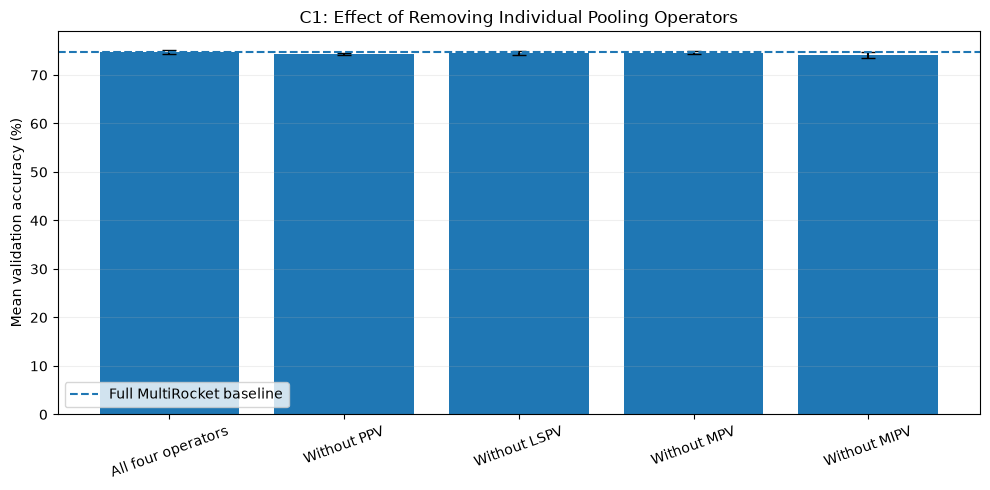


Accuracy change relative to full model:


,Accuracy change (pp)
Configuration,
All four operators,0.0000
Without PPV,-0.4861
Without LSPV,-0.2083
Without MPV,-0.2083
Without MIPV,-0.7639


In [11]:
# Experiment C1 — Pooling ablation visualisation

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

required = {"Configuration", "Validation accuracy (%)"}
assert required.issubset(pooling_seed_df.columns)

c1_order = [
    "All four operators",
    "Without PPV",
    "Without LSPV",
    "Without MPV",
    "Without MIPV"
]

c1_summary = (
    pooling_seed_df
    .groupby("Configuration")["Validation accuracy (%)"]
    .agg(["mean", "std", "count"])
    .reindex(c1_order)
)

assert c1_summary["count"].notna().all(), \
    "Check configuration labels in pooling_seed_df"

baseline_accuracy = c1_summary.loc[
    "All four operators", "mean"
]

c1_summary["Accuracy change (pp)"] = (
    c1_summary["mean"] - baseline_accuracy
)

display(c1_summary.round(4))

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(c1_summary))

ax.bar(
    x,
    c1_summary["mean"],
    yerr=c1_summary["std"].fillna(0),
    capsize=5
)

ax.axhline(
    baseline_accuracy,
    linestyle="--",
    label="Full MultiRocket baseline"
)

ax.set_xticks(x)
ax.set_xticklabels(c1_summary.index, rotation=20)
ax.set_ylabel("Mean validation accuracy (%)")
ax.set_title("C1: Effect of Removing Individual Pooling Operators")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()

print("\nAccuracy change relative to full model:")
display(c1_summary[["Accuracy change (pp)"]].round(4))

### 6.1 C1 — Results and Discussion

**Results**

Using all four pooling operators gave the highest mean validation accuracy of **74.82%**, with a macro F1-score of **74.45%**.

Removing LSPV and MPV had only a small effect on accuracy, with both configurations achieving 74.61%. Removing PPV reduced accuracy to 74.33%, while removing MIPV caused the largest decrease, to 74.06%.

In each case, the number of features was reduced from 4,704 to 3,528, which is a **25% reduction**.

**Comparison and Reflection**

One interesting finding was that removing different pooling operators did not affect accuracy equally. MIPV had the largest impact when removed, suggesting that it may contribute more useful information for classifying the Crop dataset.

On the other hand, removing LSPV or MPV made very little difference to the overall accuracy. In particular, removing MPV reduced accuracy by only **0.21 percentage points**, even though 25% of the features were removed. This suggests that some of the information captured by MPV may also be represented by the other pooling operators.

However, the feature reduction in this experiment happened after all the features had already been generated. This means that although fewer features were passed to the classifier, the computational cost of generating them remained the same.

**Conclusion**

The results showed that removing MPV or LSPV had only a small effect on classification accuracy, making both worth investigating further.

I chose to investigate MPV in the next experiment to see whether removing it directly from the feature-generation process could reduce extraction time without significantly affecting accuracy.

Although the results are promising, they are based on the Crop dataset, and the small differences in accuracy may vary across different random seeds or datasets.

### 6.2 C2 — Direct MPV Removal

**Research Question:** Can removing MPV directly from MultiRocket's feature-generation process reduce extraction time without significantly affecting classification accuracy?

**Motivation:** In Experiment 6.1, removing MPV resulted in only a small decrease in validation accuracy. However, that experiment removed MPV features after they had already been generated, so it did not reduce the computation required for feature extraction.

This experiment takes the idea further by modifying the transformation itself to remove MPV computations. The aim is to determine whether this change actually improves efficiency while retaining similar classification performance.

**Hypothesis:** Removing MPV during feature generation is expected to reduce extraction time because fewer pooling operations are performed. Based on the previous ablation results, only a small decrease in accuracy is expected.

**Methodology:** A modified version of the MultiRocket transformation was created without MPV. Before evaluating its performance, the remaining feature blocks were compared with the corresponding features from the original implementation to check that they were unchanged.

Both implementations were then evaluated across five paired random seeds using the same kernel parameters, sub-training data and validation set.

Feature extraction was timed three times after warm-up, and the median time was recorded for each seed. The experiment compared feature count, validation accuracy and extraction time to determine whether directly removing MPV provided a useful efficiency improvement.

In [12]:
original_module_path = PROJECT_ROOT / "multirocket" / "multirocket.py"
modified_module_path = PROJECT_ROOT / "multirocket" / "multirocket_without_mpv.py"
source_text = original_module_path.read_text(encoding="utf-8")

start_marker = '@njit(\n    "float32[:,:]'
if start_marker not in source_text:
    raise RuntimeError("Expected transform source pattern not found; inspect multirocket.py.")

start_idx = source_text.index(start_marker)
end_idx = source_text.index("\n\n\nclass MultiRocket:", start_idx)
transform_code = source_text[start_idx:end_idx]

transform_code, a = re.subn(r"(?m)^[ \t]*mean = 0\s*\n", "", transform_code)
transform_code, b = re.subn(r"(?m)^[ \t]*mean \+= (?:C|_c)\[j\] \+ _bias\s*\n", "", transform_code)
transform_code, c = re.subn(
    r"(?m)^([ \t]*)features\[example_index, end\] = mean / ppv if ppv > 0 else 0\n"
    r"\1end = end \+ num_features\n", "", transform_code
)
assert (a, b, c) == (4, 4, 4), (
    "Expected four MPV code blocks to remove; source may have changed."
)

modified_module_path.write_text(source_text[:start_idx] + transform_code + "\n", encoding="utf-8")
importlib.invalidate_caches()
sys.modules.pop("multirocket.multirocket_without_mpv", None)
from multirocket.multirocket_without_mpv import transform as transform_without_mpv

print("Created and imported:", modified_module_path)

Created and imported: c:\Users\Tavishi\Downloads\MultiRocket\multirocket\multirocket_without_mpv.py


In [13]:
# Verify numerical equivalence of retained operators on a small training sample.
check_n = min(20, len(X_train))
Xc = np.ascontiguousarray(X_train[:check_n], dtype=np.float64)
Dc = np.ascontiguousarray(np.diff(Xc, axis=1))

set_numba_seed(RANDOM_STATE)
bp_check = fit(Xc, num_features=FULL_KERNELS)
dp_check = fit(Dc, num_features=FULL_KERNELS)

F_all_check = transform(Xc, Dc, bp_check, dp_check, 4)
F_no_check = transform_without_mpv(Xc, Dc, bp_check, dp_check, 3)

half = F_all_check.shape[1] // 2
block = half // 4
keep_cols = []
for series_i in range(2):
    for op_i in [0, 1, 3]:  # PPV, LSPV, MIPV; skip MPV
        start = series_i * half + op_i * block
        keep_cols.extend(range(start, start + block))

F_expected = F_all_check[:, keep_cols]
assert F_expected.shape == F_no_check.shape
max_abs_diff = np.max(np.abs(F_expected - F_no_check))
print("Max absolute difference:", max_abs_diff)
assert np.allclose(F_expected, F_no_check, rtol=1e-5, atol=1e-5)
print("Verification passed.")

Max absolute difference: 0.0
Verification passed.


### 6.2 — C2 Direct MPV Removal: Results and Reflection

**Results**

The original MultiRocket implementation generated 4,704 features and achieved a mean validation accuracy of 74.82%. Removing MPV directly reduced the feature count to 3,528, a 25% reduction, while accuracy decreased slightly to 74.61%.

However, the initial five-seed C2 comparison showed that the modified implementation was 17.91% slower on average (SD 14.14 percentage points). This was unexpected, as I initially thought removing one pooling operator would reduce extraction time. This was unexpected, as I initially thought removing one pooling operator would reduce extraction time.

The mean accuracy difference was −0.21 percentage points, with a paired Wilcoxon p-value of 0.625.

**Comparison with C1**

The no-MPV accuracy matched the result from the post-hoc ablation in C1. This was a useful consistency check, as both approaches retained the same pooling features.

However, C1 removed features after extraction, whereas C2 modified the transformation itself. Although C2 generated fewer features, the initial results did not show the expected runtime improvement.

**Reflection**

The unexpected increase in extraction time made me question whether reducing the number of generated features necessarily reduces computational cost.

Since the modified implementation was slower across all five seeds, I decided to investigate the timing results further rather than assume that the modification was more efficient.

This led to an additional benchmark using more repetitions and alternating execution order to check whether the slowdown was consistent.

### 6.3 — Repeated-Seed Performance and Timing Comparison

The original and no-MPV transforms are compared on the same sub-training and validation split for each of five seeds. Parameter fitting is performed on the sub-training data only. Each extraction timing is repeated three times after Numba warm-up, and the median of the three timings is used to reduce transient timing noise.

Reporting the five-seed mean ± standard deviation for validation accuracy and extraction-time change. A positive extraction-time change means no-MPV was slower; a negative value means it was faster.


In [14]:
mpv_rows = []
Xfit_c = np.ascontiguousarray(X_subtrain, dtype=np.float64)
Xval_c = np.ascontiguousarray(X_val, dtype=np.float64)
Dfit_c = np.ascontiguousarray(np.diff(Xfit_c, axis=1))
Dval_c = np.ascontiguousarray(np.diff(Xval_c, axis=1))

for seed in SEEDS:
    print("MPV validation comparison seed:", seed)
    set_numba_seed(seed)
    bp = fit(Xfit_c, num_features=FULL_KERNELS)
    dp = fit(Dfit_c, num_features=FULL_KERNELS)

    n_warm = min(4, len(Xfit_c))
    _ = transform(Xfit_c[:n_warm], Dfit_c[:n_warm], bp, dp, 4)
    _ = transform_without_mpv(Xfit_c[:n_warm], Dfit_c[:n_warm], bp, dp, 3)

    original_times, no_mpv_times = [], []
    Ffit_all = Fval_all = Ffit_no = Fval_no = None
    for timing_repeat in range(3):
        t0 = time.perf_counter()
        Ffit_all = transform(Xfit_c, Dfit_c, bp, dp, 4)
        Fval_all = transform(Xval_c, Dval_c, bp, dp, 4)
        original_times.append(time.perf_counter() - t0)

        t0 = time.perf_counter()
        Ffit_no = transform_without_mpv(Xfit_c, Dfit_c, bp, dp, 3)
        Fval_no = transform_without_mpv(Xval_c, Dval_c, bp, dp, 3)
        no_mpv_times.append(time.perf_counter() - t0)

    time_all = float(np.median(original_times))
    time_no = float(np.median(no_mpv_times))
    ev_all = score_classifier(ridge_classifier(), Ffit_all, y_subtrain, Fval_all, y_val)
    ev_no = score_classifier(ridge_classifier(), Ffit_no, y_subtrain, Fval_no, y_val)

    mpv_rows.append({
        "Seed": seed,
        "Original features": Ffit_all.shape[1],
        "No-MPV features": Ffit_no.shape[1],
        "Original validation accuracy (%)": ev_all["accuracy_pct"],
        "No-MPV validation accuracy (%)": ev_no["accuracy_pct"],
        "Accuracy difference (pp)": ev_no["accuracy_pct"] - ev_all["accuracy_pct"],
        "Original extraction median (s)": time_all,
        "No-MPV extraction median (s)": time_no,
        "Extraction time change (%)": (time_no / time_all - 1) * 100,
        "Original timing repeats (s)": original_times,
        "No-MPV timing repeats (s)": no_mpv_times,
    })
    del Ffit_all, Fval_all, Ffit_no, Fval_no
    gc.collect()

mpv_df = pd.DataFrame(mpv_rows)
display(mpv_df.drop(columns=["Original timing repeats (s)", "No-MPV timing repeats (s)"]).round(4))
mpv_summary_df = mpv_df.drop(
    columns=["Original timing repeats (s)", "No-MPV timing repeats (s)"]
).agg(["mean", "std"])
display(mpv_summary_df.round(4))

mean_time_change = mpv_df["Extraction time change (%)"].mean()
std_time_change = mpv_df["Extraction time change (%)"].std(ddof=1)
cv_time_change = (std_time_change / abs(mean_time_change) * 100) if mean_time_change else np.nan
print(f"MPV extraction-time change: {mean_time_change:.2f}% ± {std_time_change:.2f}% (SD); CV={cv_time_change:.2f}%")
mpv_df.to_csv(RESULTS_DIR / "05_direct_mpv_validation_5seeds.csv", index=False)
mpv_summary_df.to_csv(RESULTS_DIR / "05_direct_mpv_validation_summary.csv")

try:
    print("Paired Wilcoxon p-value (validation accuracy differences):",
          wilcoxon(mpv_df["Accuracy difference (pp)"]).pvalue)
except ValueError as e:
    print("Wilcoxon not computed:", e)


MPV validation comparison seed: 0
MPV validation comparison seed: 1
MPV validation comparison seed: 2
MPV validation comparison seed: 3
MPV validation comparison seed: 4


,Seed,Original features,No-MPV features,Original validation accuracy (%),No-MPV validation accuracy (%),Accuracy difference (pp),Original extraction median (s),No-MPV extraction median (s),Extraction time change (%)
0,0,4704,3528,74.8611,74.8611,0.0000,0.3069,0.3610,17.6280
1,1,4704,3528,74.0972,74.4444,0.3472,0.4646,0.5286,13.7845
2,2,4704,3528,74.8611,74.5833,-0.2778,0.4798,0.6791,41.5376
3,3,4704,3528,75.1389,75.0000,-0.1389,0.5076,0.5273,3.8652
4,4,4704,3528,75.1389,74.1667,-0.9722,0.4938,0.5567,12.7314


,Seed,Original features,No-MPV features,Original validation accuracy (%),No-MPV validation accuracy (%),Accuracy difference (pp),Original extraction median (s),No-MPV extraction median (s),Extraction time change (%)
mean,2.0000,4704.0,3528.0,74.8194,74.6111,-0.2083,0.4505,0.5305,17.9093
std,1.5811,0.0,0.0,0.4270,0.3316,0.4861,0.0819,0.1135,14.1371


MPV extraction-time change: 17.91% ± 14.14% (SD); CV=78.94%
Paired Wilcoxon p-value (validation accuracy differences): 0.625


In [15]:
# Experiment C — C1 versus C2 comparison

import pandas as pd
import numpy as np

# C1: Post-hoc pooling ablation
c1_comparison = (
    pooling_seed_df
    .groupby("Configuration")
    .agg(
        Features=("Features", "mean"),
        Accuracy=("Validation accuracy (%)", "mean"),
        Macro_F1=("Validation macro F1 (%)", "mean")
    )
)

# C2: Direct MPV removal
c2_original = {
    "Configuration": "C2 - Original",
    "Features": mpv_df["Original features"].mean(),
    "Accuracy": mpv_df["Original validation accuracy (%)"].mean(),
    "Macro_F1": np.nan
}

c2_modified = {
    "Configuration": "C2 - Direct no-MPV",
    "Features": mpv_df["No-MPV features"].mean(),
    "Accuracy": mpv_df["No-MPV validation accuracy (%)"].mean(),
    "Macro_F1": np.nan
}

comparison_rows = []

for name in ["All four operators", "Without MPV"]:
    row = c1_comparison.loc[name]

    comparison_rows.append({
        "Configuration": "C1 - " + name,
        "Features": row["Features"],
        "Accuracy": row["Accuracy"],
        "Macro F1": row["Macro_F1"],
        "Extraction approach": "Full extraction"
    })

for item, approach in [
    (c2_original, "Original transform"),
    (c2_modified, "Modified transform")
]:
    comparison_rows.append({
        "Configuration": item["Configuration"],
        "Features": item["Features"],
        "Accuracy": item["Accuracy"],
        "Macro F1": item["Macro_F1"],
        "Extraction approach": approach
    })

c_comparison_df = pd.DataFrame(comparison_rows)

display(c_comparison_df.round(4))

print("\nC1 versus C2 accuracy comparison:")
print(
    "Post-hoc no-MPV:",
    round(c1_comparison.loc["Without MPV", "Accuracy"], 4)
)

print(
    "Direct no-MPV:",
    round(c2_modified["Accuracy"], 4)
)

print(
    "\nNote: C1 and C2 use different extraction procedures."
    " Their runtimes must be evaluated separately."
)

,Configuration,Features,Accuracy,Macro F1,Extraction approach
0,C1 - All four operators,4704.0,74.8194,74.4538,Full extraction
1,C1 - Without MPV,3528.0,74.6111,74.2375,Full extraction
2,C2 - Original,4704.0,74.8194,NaN,Original transform
3,C2 - Direct no-MPV,3528.0,74.6111,NaN,Modified transform



C1 versus C2 accuracy comparison:
Post-hoc no-MPV: 74.6111
Direct no-MPV: 74.6111

Note: C1 and C2 use different extraction procedures. Their runtimes must be evaluated separately.


In [16]:
# Experiment C2 — Enhanced five-seed runtime benchmark

import time
import gc
import numpy as np
import pandas as pd

# Verify required objects are available
required_names = [
    "X_subtrain", "X_val", "SEEDS", "FULL_KERNELS",
    "set_numba_seed", "fit", "transform",
    "transform_without_mpv"
]

missing = [
    name for name in required_names
    if name not in globals()
]

if missing:
    raise RuntimeError(
        "Run prerequisite cells first. Missing: "
        + ", ".join(missing)
    )

# Same data preparation as existing C2
bench_Xfit = np.ascontiguousarray(
    X_subtrain, dtype=np.float64
)
bench_Xval = np.ascontiguousarray(
    X_val, dtype=np.float64
)

bench_Dfit = np.ascontiguousarray(
    np.diff(bench_Xfit, axis=1)
)
bench_Dval = np.ascontiguousarray(
    np.diff(bench_Xval, axis=1)
)

N_REPEATS = 10
N_WARMUP = 3

benchmark_rows = []
benchmark_summary_rows = []

for seed in SEEDS:

    print(f"\nBenchmarking seed {seed}")

    set_numba_seed(seed)

    # Fit once per seed and reuse identical parameters
    bp = fit(bench_Xfit, num_features=FULL_KERNELS)
    dp = fit(bench_Dfit, num_features=FULL_KERNELS)

    def original_extract():
        train_features = transform(
            bench_Xfit, bench_Dfit, bp, dp, 4
        )
        val_features = transform(
            bench_Xval, bench_Dval, bp, dp, 4
        )
        return train_features, val_features

    def modified_extract():
        train_features = transform_without_mpv(
            bench_Xfit, bench_Dfit, bp, dp, 3
        )
        val_features = transform_without_mpv(
            bench_Xval, bench_Dval, bp, dp, 3
        )
        return train_features, val_features

    # Warm up both implementations
    for _ in range(N_WARMUP):
        original_extract()
        modified_extract()

    gc.collect()

    original_times = []
    modified_times = []

    for repeat in range(N_REPEATS):

        # Alternate measurement order
        if repeat % 2 == 0:
            methods = [
                ("Original", original_extract),
                ("No MPV", modified_extract)
            ]
        else:
            methods = [
                ("No MPV", modified_extract),
                ("Original", original_extract)
            ]

        repeat_results = {}

        for method_name, function in methods:

            start = time.perf_counter()
            features = function()
            elapsed = time.perf_counter() - start

            repeat_results[method_name] = elapsed

            # Keep output alive until after timing
            del features

        original_time = repeat_results["Original"]
        modified_time = repeat_results["No MPV"]

        original_times.append(original_time)
        modified_times.append(modified_time)

        benchmark_rows.append({
            "Seed": seed,
            "Repeat": repeat + 1,
            "Original time (s)": original_time,
            "No-MPV time (s)": modified_time,
            "Time change (%)": (
                modified_time / original_time - 1
            ) * 100
        })

    original_median = np.median(original_times)
    modified_median = np.median(modified_times)

    change_pct = (
        modified_median / original_median - 1
    ) * 100

    benchmark_summary_rows.append({
        "Seed": seed,
        "Original median (s)": original_median,
        "No-MPV median (s)": modified_median,
        "Time change (%)": change_pct,
        "Original std (s)": np.std(
            original_times, ddof=1
        ),
        "No-MPV std (s)": np.std(
            modified_times, ddof=1
        )
    })

    print(f"Original median: {original_median:.4f} s")
    print(f"No-MPV median:   {modified_median:.4f} s")
    print(f"Change:          {change_pct:+.2f}%")

    del bp, dp
    gc.collect()

# Detailed results
c2_benchmark_df = pd.DataFrame(benchmark_rows)

# One summary row per seed
c2_benchmark_summary = pd.DataFrame(
    benchmark_summary_rows
)

print("\nFive-seed benchmark summary:")
display(c2_benchmark_summary.round(4))

mean_change = c2_benchmark_summary[
    "Time change (%)"
].mean()

std_change = c2_benchmark_summary[
    "Time change (%)"
].std(ddof=1)

print("\nOverall runtime change:")
print(f"Mean: {mean_change:+.2f}%")
print(f"Standard deviation: {std_change:.2f} pp")

if mean_change < 0:
    print("No-MPV was faster on average.")
else:
    print("No-MPV was slower on average.")

# Save results without overwriting original C2 CSV
from pathlib import Path

benchmark_dir = Path(RESULTS_DIR)
benchmark_dir.mkdir(parents=True, exist_ok=True)

c2_benchmark_df.to_csv(
    benchmark_dir / "C2_enhanced_timing_repetitions.csv",
    index=False
)

c2_benchmark_summary.to_csv(
    benchmark_dir / "C2_enhanced_timing_summary.csv",
    index=False
)

print("\nEnhanced benchmark completed.")


Benchmarking seed 0
Original median: 0.2973 s
No-MPV median:   0.3784 s
Change:          +27.27%

Benchmarking seed 1
Original median: 0.4160 s
No-MPV median:   0.5333 s
Change:          +28.19%

Benchmarking seed 2
Original median: 0.4235 s
No-MPV median:   0.5115 s
Change:          +20.80%

Benchmarking seed 3
Original median: 0.4270 s
No-MPV median:   0.5269 s
Change:          +23.41%

Benchmarking seed 4
Original median: 0.4438 s
No-MPV median:   0.5396 s
Change:          +21.59%

Five-seed benchmark summary:


,Seed,Original median (s),No-MPV median (s),Time change (%),Original std (s),No-MPV std (s)
0,0,0.2973,0.3784,27.2747,0.0389,0.0498
1,1,0.4160,0.5333,28.1860,0.0594,0.0569
2,2,0.4235,0.5115,20.8008,0.0224,0.0253
3,3,0.4270,0.5269,23.4055,0.0312,0.0195
4,4,0.4438,0.5396,21.5943,0.0380,0.0225



Overall runtime change:
Mean: +24.25%
Standard deviation: 3.33 pp
No-MPV was slower on average.

Enhanced benchmark completed.


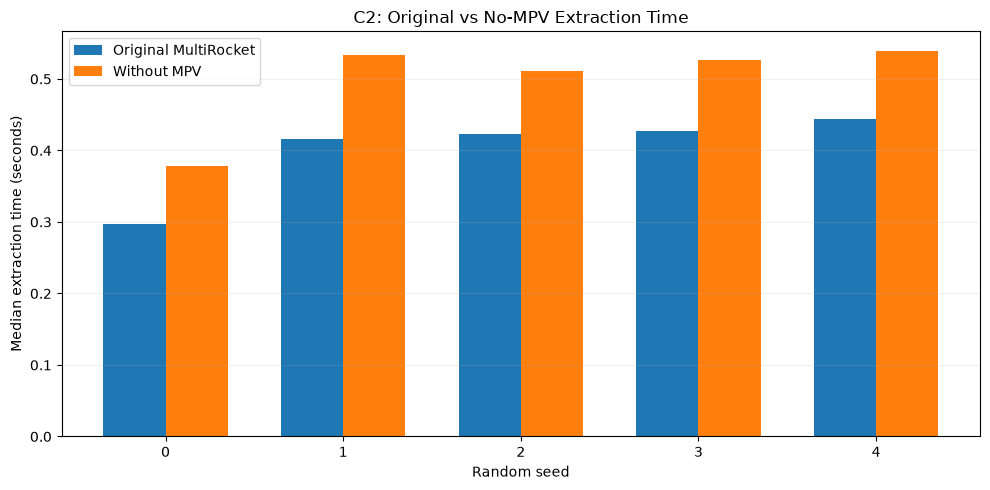

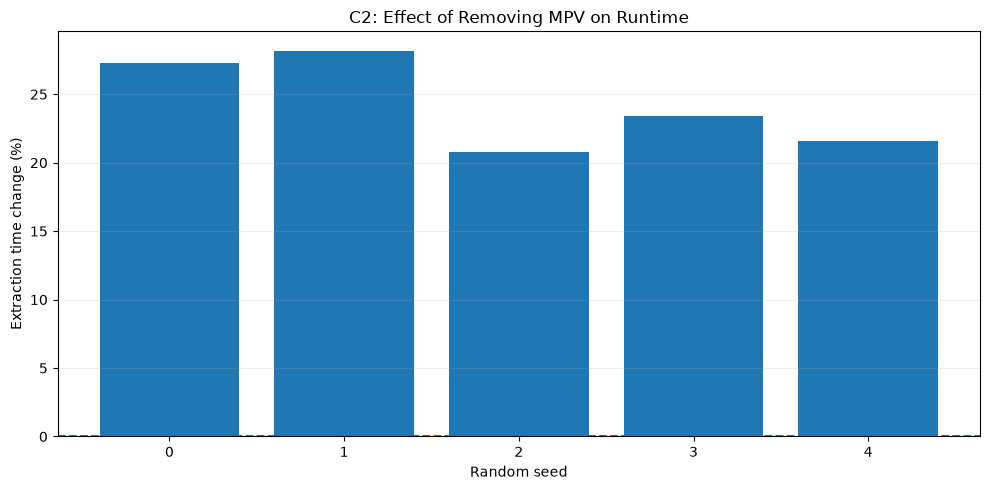

ENHANCED C2 BENCHMARK RESULTS
---------------------------------------------
Original mean median time: 0.4015 s
No-MPV mean median time:   0.4980 s
Mean paired runtime change: +24.25%
Seeds with faster no-MPV extraction: 0 / 5


In [17]:
# Experiment C2 — Enhanced benchmark visualisation

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

df = c2_benchmark_summary.copy()

fig, ax = plt.subplots(figsize=(10, 5))

x = np.arange(len(df))
width = 0.35

ax.bar(
    x - width / 2,
    df["Original median (s)"],
    width,
    label="Original MultiRocket"
)

ax.bar(
    x + width / 2,
    df["No-MPV median (s)"],
    width,
    label="Without MPV"
)

ax.set_xticks(x)
ax.set_xticklabels(df["Seed"].astype(str))
ax.set_xlabel("Random seed")
ax.set_ylabel("Median extraction time (seconds)")
ax.set_title("C2: Original vs No-MPV Extraction Time")
ax.legend()
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


# Runtime percentage change by seed
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    df["Seed"].astype(str),
    df["Time change (%)"]
)

ax.axhline(0, linestyle="--")

ax.set_xlabel("Random seed")
ax.set_ylabel("Extraction time change (%)")
ax.set_title("C2: Effect of Removing MPV on Runtime")
ax.grid(axis="y", alpha=0.2)

plt.tight_layout()
plt.show()


# Final timing summary
original_mean = df["Original median (s)"].mean()
modified_mean = df["No-MPV median (s)"].mean()

mean_paired_change = df["Time change (%)"].mean()

print("ENHANCED C2 BENCHMARK RESULTS")
print("-" * 45)

print(f"Original mean median time: {original_mean:.4f} s")
print(f"No-MPV mean median time:   {modified_mean:.4f} s")

print(
    f"Mean paired runtime change: "
    f"{mean_paired_change:+.2f}%"
)

print(
    f"Seeds with faster no-MPV extraction: "
    f"{(df['Time change (%)'] < 0).sum()} / {len(df)}"
)

### C2 — Enhanced Runtime Benchmark: Results and Reflection

**Results:** The enhanced five-seed benchmark showed that No-MPV was **24.25% slower (SD 3.33 percentage points)**, compared with **17.91% slower (SD 14.14 percentage points)** in the initial experiment.

**Reflection:** Both benchmarks confirmed that removing MPV reduced feature count but did not improve extraction speed. The enhanced benchmark showed less timing variation, suggesting more consistent measurements. Further profiling would help explain the slowdown.

In [18]:
# Experiment C2 — Numerical equivalence across five seeds

import numpy as np
import pandas as pd

verification_rows = []

for seed in SEEDS:

    set_numba_seed(seed)

    bp_check = fit(
        bench_Xfit, num_features=FULL_KERNELS
    )
    dp_check = fit(
        bench_Dfit, num_features=FULL_KERNELS
    )

    for split_name, X, D in [
        ("Sub-training", bench_Xfit, bench_Dfit),
        ("Validation", bench_Xval, bench_Dval)
    ]:

        full = transform(X, D, bp_check, dp_check, 4)

        reduced = transform_without_mpv(
            X, D, bp_check, dp_check, 3
        )

        half = full.shape[1] // 2
        block = half // 4

        assert full.shape[1] % 8 == 0

        keep_cols = []

        for series_i in range(2):
            for operator_i in [0, 1, 3]:
                start = series_i * half + operator_i * block
                keep_cols.extend(range(start, start + block))

        expected = full[:, keep_cols]

        assert expected.shape == reduced.shape

        max_difference = float(
            np.max(np.abs(expected - reduced))
        )

        passed = bool(
            np.allclose(
                expected, reduced,
                rtol=1e-5,
                atol=1e-5
            )
        )

        verification_rows.append({
            "Seed": seed,
            "Split": split_name,
            "Max absolute difference": max_difference,
            "Passed": passed
        })

        del full, reduced, expected

verification_df = pd.DataFrame(verification_rows)

display(verification_df)

print(
    "All verification checks passed:",
    verification_df["Passed"].all()
)

assert verification_df["Passed"].all(), \
    "Some numerical equivalence checks failed"

,Seed,Split,Max absolute difference,Passed
0,0,Sub-training,0.0,True
1,0,Validation,0.0,True
2,1,Sub-training,0.0,True
3,1,Validation,0.0,True
4,2,Sub-training,0.0,True
5,2,Validation,0.0,True
6,3,Sub-training,0.0,True
7,3,Validation,0.0,True
8,4,Sub-training,0.0,True
9,4,Validation,0.0,True


All verification checks passed: True


In [19]:
import time
import numpy as np
import pandas as pd

# Check dependencies
required = [
    "X_subtrain", "X_val",
    "fit", "transform", "transform_without_mpv",
    "FULL_KERNELS", "set_numba_seed"
]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Run the required setup/C2 cells first. Missing: "
        + ", ".join(missing)
    )

# Prepare data
Xfit_bench = np.ascontiguousarray(
    X_subtrain, dtype=np.float64
)
Xval_bench = np.ascontiguousarray(
    X_val, dtype=np.float64
)

Dfit_bench = np.ascontiguousarray(
    np.diff(Xfit_bench, axis=1)
)
Dval_bench = np.ascontiguousarray(
    np.diff(Xval_bench, axis=1)
)

# Fit kernel parameters once
set_numba_seed(0)

bp_bench = fit(
    Xfit_bench, num_features=FULL_KERNELS
)

dp_bench = fit(
    Dfit_bench, num_features=FULL_KERNELS
)

def run_original():
    return (
        transform(Xfit_bench, Dfit_bench, bp_bench, dp_bench, 4),
        transform(Xval_bench, Dval_bench, bp_bench, dp_bench, 4)
    )

def run_no_mpv():
    return (
        transform_without_mpv(
            Xfit_bench, Dfit_bench, bp_bench, dp_bench, 3
        ),
        transform_without_mpv(
            Xval_bench, Dval_bench, bp_bench, dp_bench, 3
        )
    )

# Warm up both functions
for _ in range(3):
    run_original()
    run_no_mpv()

results = []

# Alternate execution order
for repeat in range(10):

    if repeat % 2 == 0:
        methods = [
            ("Original", run_original),
            ("No MPV", run_no_mpv)
        ]
    else:
        methods = [
            ("No MPV", run_no_mpv),
            ("Original", run_original)
        ]

    for name, function in methods:

        start = time.perf_counter()
        output = function()
        elapsed = time.perf_counter() - start

        results.append({
            "Repeat": repeat + 1,
            "Method": name,
            "Time (s)": elapsed
        })

        del output

benchmark_df = pd.DataFrame(results)

summary = benchmark_df.groupby("Method")["Time (s)"].agg(
    ["mean", "median", "std"]
)

display(summary.round(4))

original_median = summary.loc["Original", "median"]
no_mpv_median = summary.loc["No MPV", "median"]

change = (
    no_mpv_median / original_median - 1
) * 100

print(f"\nExtraction time change: {change:+.2f}%")

if change < 0:
    print("No-MPV was faster in this benchmark.")
else:
    print("No-MPV was slower in this benchmark.")

,mean,median,std
Method,,,
No MPV,0.6626,0.6201,0.1602
Original,0.5632,0.5091,0.1453



Extraction time change: +21.81%
No-MPV was slower in this benchmark.


### 6.4 C3 — Diagnosing the No-MPV Runtime Overhead

**Research Question:** Why is the direct No-MPV implementation slower even though it generates 25% fewer features?

**Motivation:** C2 found that fewer output features did not lead to faster extraction. I wanted to separate sub-training and validation transformation costs and check whether the slowdown occurs consistently in both stages.

**Hypothesis:** If the slowdown comes from the modified transformation itself rather than classifier training, No-MPV will take longer during both feature-extraction stages even when both implementations use identical fitted kernel parameters.

**Methodology:** Using the same Crop sub-training and validation split, five seeds, and fitted parameters for each paired comparison, I time the two transforms separately. Both functions are warmed up before measurement; execution order alternates across ten repetitions. I report per-seed median times, mean and standard deviation of percentage differences, and output-array sizes. These are local benchmarks, not hardware-independent speed guarantees.

In [20]:
# C3: Stage-specific, paired transform timing (no classifier fitting)
import time
import gc
import numpy as np
import pandas as pd

c3_required = ["X_subtrain", "X_val", "SEEDS", "FULL_KERNELS", "fit",
               "transform", "transform_without_mpv", "set_numba_seed", "RESULTS_DIR"]
c3_missing = [x for x in c3_required if x not in globals()]
if c3_missing:
    raise RuntimeError("Run the original setup and C2 cells first: " + ", ".join(c3_missing))

c3_xfit = np.ascontiguousarray(X_subtrain, dtype=np.float64)
c3_xval = np.ascontiguousarray(X_val, dtype=np.float64)
c3_dfit = np.ascontiguousarray(np.diff(c3_xfit, axis=1))
c3_dval = np.ascontiguousarray(np.diff(c3_xval, axis=1))
c3_rows = []

for seed in SEEDS:
    set_numba_seed(int(seed))
    c3_bp = fit(c3_xfit, num_features=FULL_KERNELS)
    c3_dp = fit(c3_dfit, num_features=FULL_KERNELS)
    for stage, X, D in [("Sub-training", c3_xfit, c3_dfit),
                        ("Validation", c3_xval, c3_dval)]:
        implementations = {
            "Original": lambda: transform(X, D, c3_bp, c3_dp, 4),
            "No-MPV": lambda: transform_without_mpv(X, D, c3_bp, c3_dp, 3),
        }
        for func in implementations.values():
            for _ in range(2):
                func()  # compile/warm up outside measurement
        times = {name: [] for name in implementations}
        shapes = {}
        for repeat in range(10):
            order = ["Original", "No-MPV"] if repeat % 2 == 0 else ["No-MPV", "Original"]
            for name in order:
                t0 = time.perf_counter()
                result = implementations[name]()
                elapsed = time.perf_counter() - t0
                times[name].append(elapsed)
                shapes[name] = result.shape
                del result
        assert shapes["Original"][0] == shapes["No-MPV"][0]
        assert shapes["No-MPV"][1] * 4 == shapes["Original"][1] * 3
        orig = float(np.median(times["Original"]))
        reduced = float(np.median(times["No-MPV"]))
        c3_rows.append({"Seed": seed, "Stage": stage,
                        "Original median (s)": orig, "No-MPV median (s)": reduced,
                        "Time change (%)": 100 * (reduced / orig - 1),
                        "Original features": shapes["Original"][1],
                        "No-MPV features": shapes["No-MPV"][1],
                        "Original output (MiB)": np.prod(shapes["Original"]) * 4 / 2**20,
                        "No-MPV output (MiB)": np.prod(shapes["No-MPV"]) * 4 / 2**20})
    del c3_bp, c3_dp
    gc.collect()

c3_stage_df = pd.DataFrame(c3_rows)
c3_summary_df = c3_stage_df.groupby("Stage", as_index=False).agg(
    **{"Mean time change (%)": ("Time change (%)", "mean"),
       "SD time change (pp)": ("Time change (%)", "std"),
       "Original median time mean (s)": ("Original median (s)", "mean"),
       "No-MPV median time mean (s)": ("No-MPV median (s)", "mean")})
print("C3 — per-seed stage timings")
display(c3_stage_df.round(4))
print("C3 — stage-level summary (positive means No-MPV is slower)")
display(c3_summary_df.round(4))
c3_stage_df.to_csv(RESULTS_DIR / "c3_stage_timing_by_seed.csv", index=False)
c3_summary_df.to_csv(RESULTS_DIR / "c3_stage_timing_summary.csv", index=False)
assert len(c3_stage_df) == 2 * len(SEEDS)
assert np.isfinite(c3_stage_df["Time change (%)"]).all()
print("C3 verification passed: paired seed/stage records and 25% feature reduction.")

C3 — per-seed stage timings


,Seed,Stage,Original median (s),No-MPV median (s),Time change (%),Original features,No-MPV features,Original output (MiB),No-MPV output (MiB)
0,0,Sub-training,0.2352,0.2722,15.7009,4704,3528,103.3594,77.5195
1,0,Validation,0.1152,0.1289,11.9410,4704,3528,25.8398,19.3799
2,1,Sub-training,0.3786,0.4747,25.3734,4704,3528,103.3594,77.5195
3,1,Validation,0.0970,0.1154,18.9928,4704,3528,25.8398,19.3799
4,2,Sub-training,0.3664,0.4544,24.0141,4704,3528,103.3594,77.5195
5,2,Validation,0.1030,0.1158,12.3847,4704,3528,25.8398,19.3799
6,3,Sub-training,0.3477,0.4664,34.1353,4704,3528,103.3594,77.5195
7,3,Validation,0.0878,0.1105,25.8408,4704,3528,25.8398,19.3799
8,4,Sub-training,0.3669,0.4370,19.1038,4704,3528,103.3594,77.5195
9,4,Validation,0.0911,0.1067,17.1238,4704,3528,25.8398,19.3799


C3 — stage-level summary (positive means No-MPV is slower)


,Stage,Mean time change (%),SD time change (pp),Original median time mean (s),No-MPV median time mean (s)
0,Sub-training,23.6655,7.0160,0.3390,0.4209
1,Validation,17.2567,5.6726,0.0988,0.1155


C3 verification passed: paired seed/stage records and 25% feature reduction.


In [21]:
import numba
default_threads = numba.get_num_threads()
numba.set_num_threads(1)

xs = np.ascontiguousarray(X_subtrain, dtype=np.float64)
ds = np.ascontiguousarray(np.diff(xs, axis=1))
set_numba_seed(0)
bp1 = fit(xs, num_features=FULL_KERNELS)
dp1 = fit(ds, num_features=FULL_KERNELS)
for _ in range(2):
    transform(xs, ds, bp1, dp1, 4)
    transform_without_mpv(xs, ds, bp1, dp1, 3)

t_orig, t_nompv = [], []
for repeat in range(6):
    for name in (["orig", "nompv"] if repeat % 2 == 0 else ["nompv", "orig"]):
        t0 = time.perf_counter()
        if name == "orig":
            transform(xs, ds, bp1, dp1, 4)
            t_orig.append(time.perf_counter() - t0)
        else:
            transform_without_mpv(xs, ds, bp1, dp1, 3)
            t_nompv.append(time.perf_counter() - t0)

numba.set_num_threads(default_threads)
print(f"Single thread: original {np.median(t_orig):.3f}s | no-MPV {np.median(t_nompv):.3f}s | change {(np.median(t_nompv)/np.median(t_orig)-1)*100:+.1f}%")

Single thread: original 0.970s | no-MPV 1.149s | change +18.5%


### C3 — Results and Discussion

**Results**

The C3 experiment compared the original MultiRocket and No-MPV implementations by measuring extraction time separately for sub-training and validation data across five seeds.

Removing MPV reduced the number of features from 4,704 to 3,528, a reduction of 25%. The memory required to store the sub-training feature matrix also decreased from 103.36 MiB to 77.52 MiB, while the validation feature matrix decreased from 25.84 MiB to 19.38 MiB.

However, the runtime results showed the opposite of what I initially expected. No-MPV was **23.67%** slower on sub-training data (SD 7.02 percentage points) and **17.26%** slower on validation data (SD 5.67 percentage points).

The modified implementation was slower across all five seeds for both stages.

**Comparison and Reflection**

I carried out this experiment because the earlier C2 results showed that removing MPV reduced the feature count but made extraction slower. I wanted to check whether the slowdown was occurring on both sub-training and validation data or whether it was limited to one stage.

The results showed that No-MPV was slower in both cases. This was consistent with the earlier C2 benchmarks, which also showed an increase in extraction time.

One useful finding was the reduction in feature-array storage. Even though the modified implementation took longer to extract features, it produced smaller feature matrices, which could still be beneficial when memory is limited.

What surprised me was that removing an entire pooling operator did not make the transformation faster. I expected fewer pooling calculations to reduce runtime, but the results suggest that the relationship between feature count and execution time is not that straightforward.

The measurements show that the slowdown occurs during feature extraction. However, they do not explain exactly why this happens. It could be related to the modified implementation or how the compiled transformation executes, but further profiling would be needed to identify the cause.

**Conclusion**

This experiment confirmed that removing MPV reduces feature dimensionality and output-array storage by 25%, but does not improve extraction speed in the current implementation.

The results also showed that the slowdown was present during both sub-training and validation extraction, rather than being limited to one stage.

Although No-MPV was not successful as a runtime optimisation, it did reduce the size of the feature representation. Further investigation into the transform implementation would be needed to determine whether its computational performance could be improved.

### 6.5 C4 — Matched-Feature-Count Comparison: Original vs No-MPV

**Research Question:** At the same number of extracted features, does removing MPV offer any validation-accuracy or runtime advantage over retaining all four pooling operators?

**Motivation:** C2 compared 4,704 original features against 3,528 No-MPV features. This leaves feature count and operator composition changing together. A matched-size comparison helps separate those factors.

**Hypothesis:** At equal output dimensionality, the full four-operator representation may retain useful information from MPV, while No-MPV may have different extraction costs because it uses more kernel parameters to reach the same number of features.

**Methodology:** Use the original four-operator transform with a reduced kernel budget and the No-MPV transform with the existing full kernel budget. Confirm that both produce the same number of columns, fit kernel parameters only on sub-training data, and evaluate the same Ridge classifier on the same validation split across five seeds. Report accuracy, macro F1, kernel-parameter fitting time, feature-extraction time, and classifier fit/prediction time. The comparison is matched on **output features**, not on kernel count or exact feature identity. No held-out test results are used for selection.

In [22]:
# C4 — Equal Feature Count Comparison
# Original MultiRocket vs Direct No-MPV
# Five-seed validation experiment

import time
import gc
import numpy as np
import pandas as pd
from IPython.display import display

# ------------------------------------------------------------
# 1. Verify required dependencies
# ------------------------------------------------------------

c4_required = [
    "X_subtrain", "X_val", "y_subtrain", "y_val",
    "SEEDS", "fit", "transform", "transform_without_mpv",
    "set_numba_seed", "ridge_classifier",
    "score_classifier", "RESULTS_DIR"
]

c4_missing = [
    name for name in c4_required
    if name not in globals()
]

if c4_missing:
    raise RuntimeError(
        "Run setup and C2 cells first: " + ", ".join(c4_missing)
    )

# ------------------------------------------------------------
# 2. Correct C4-specific parameter budgets
# ------------------------------------------------------------

# MultiRocket allocates features in groups of 84 kernels.
#
# Original: 4 pooling operators per series
# No-MPV:   3 pooling operators per series
#
# Both use the original series and first differences.
#
# These budgets should produce 4032 actual features each.
# Verify actual dimensions before running five seeds.

c4_original_kernels = 504
c4_no_mpv_kernels = 672

print("Original requested budget:", c4_original_kernels)
print("No-MPV requested budget:", c4_no_mpv_kernels)

assert (
    4 * c4_original_kernels
    == 3 * c4_no_mpv_kernels
), "Requested feature-budget ratio is incorrect."

# ------------------------------------------------------------
# 3. Prepare data
# ------------------------------------------------------------

c4_xfit = np.ascontiguousarray(
    X_subtrain, dtype=np.float64
)

c4_xval = np.ascontiguousarray(
    X_val, dtype=np.float64
)

c4_dfit = np.ascontiguousarray(
    np.diff(c4_xfit, axis=1)
)

c4_dval = np.ascontiguousarray(
    np.diff(c4_xval, axis=1)
)

# ------------------------------------------------------------
# 4. PREFLIGHT — verify actual feature counts
# BEFORE running all five seeds
# ------------------------------------------------------------

print("\nC4 preflight feature-count verification")

set_numba_seed(0)

bp_orig = fit(
    c4_xfit,
    num_features=c4_original_kernels
)

dp_orig = fit(
    c4_dfit,
    num_features=c4_original_kernels
)

F_orig_probe = transform(
    c4_xfit[:2],
    c4_dfit[:2],
    bp_orig,
    dp_orig,
    4
)

set_numba_seed(0)

bp_no = fit(
    c4_xfit,
    num_features=c4_no_mpv_kernels
)

dp_no = fit(
    c4_dfit,
    num_features=c4_no_mpv_kernels
)

F_no_probe = transform_without_mpv(
    c4_xfit[:2],
    c4_dfit[:2],
    bp_no,
    dp_no,
    3
)

original_features = F_orig_probe.shape[1]
no_mpv_features = F_no_probe.shape[1]

print("Original actual features:", original_features)
print("No-MPV actual features:", no_mpv_features)

assert original_features == no_mpv_features, (
    f"C4 preflight failed: Original generated "
    f"{original_features} features, while No-MPV generated "
    f"{no_mpv_features}. Stop before the five-seed experiment."
)

c4_verified_features = original_features

print("C4 preflight PASSED: actual feature counts match.")

del bp_orig, dp_orig, bp_no, dp_no
del F_orig_probe, F_no_probe
gc.collect()

# ------------------------------------------------------------
# 5. Five-seed experiment
# ------------------------------------------------------------

c4_rows = []

for seed in SEEDS:

    print(f"\nRunning C4 seed {seed}")

    # Alternate method order across seeds
    configurations = [
        (
            "Original matched",
            c4_original_kernels,
            4,
            transform
        ),
        (
            "No-MPV matched",
            c4_no_mpv_kernels,
            3,
            transform_without_mpv
        )
    ]

    if int(seed) % 2 == 1:
        configurations.reverse()

    for name, kernel_count, pool_count, fn in configurations:

        set_numba_seed(int(seed))

        # Parameter fitting
        t0 = time.perf_counter()

        bp4 = fit(
            c4_xfit,
            num_features=int(kernel_count)
        )

        dp4 = fit(
            c4_dfit,
            num_features=int(kernel_count)
        )

        param_time = time.perf_counter() - t0

        # Verify dimension before expensive extraction
        probe = fn(
            c4_xfit[:2],
            c4_dfit[:2],
            bp4,
            dp4,
            pool_count
        )

        assert probe.shape[1] == c4_verified_features, (
            f"Unexpected feature count for {name}, "
            f"seed {seed}: {probe.shape[1]}"
        )

        del probe

        # Warm up both training and validation transforms
        fn(
            c4_xfit[:min(4, len(c4_xfit))],
            c4_dfit[:min(4, len(c4_xfit))],
            bp4, dp4, pool_count
        )

        fn(
            c4_xval[:min(4, len(c4_xval))],
            c4_dval[:min(4, len(c4_xval))],
            bp4, dp4, pool_count
        )

        # Repeated feature-extraction timing
        extraction_times = []

        for repeat in range(3):

            t0 = time.perf_counter()

            ffit = fn(
                c4_xfit,
                c4_dfit,
                bp4,
                dp4,
                pool_count
            )

            fval = fn(
                c4_xval,
                c4_dval,
                bp4,
                dp4,
                pool_count
            )

            extraction_times.append(
                time.perf_counter() - t0
            )

        # Check actual generated dimensions
        assert (
            ffit.shape[1]
            == fval.shape[1]
            == c4_verified_features
        ), f"Feature dimension mismatch for {name}, seed {seed}"

        # Classification evaluation
        ev = score_classifier(
            ridge_classifier(),
            ffit,
            y_subtrain,
            fval,
            y_val
        )

        c4_rows.append({
            "Seed": seed,
            "Configuration": name,
            "Kernel count per series": kernel_count,
            "Features": ffit.shape[1],
            "Validation accuracy (%)": ev["accuracy_pct"],
            "Validation macro F1 (%)": ev["macro_f1_pct"],
            "Parameter fit (s)": param_time,
            "Extraction median (s)": float(
                np.median(extraction_times)
            ),
            "Classifier fit (s)": ev["classifier_fit_s"],
            "Prediction (s)": ev["prediction_s"]
        })

        print(
            f"{name}: {ffit.shape[1]} features, "
            f"accuracy {ev['accuracy_pct']:.2f}%"
        )

        del ffit, fval, bp4, dp4, ev
        gc.collect()

# ------------------------------------------------------------
# 6. Validate equal feature counts across all seeds
# ------------------------------------------------------------

c4_matched_df = pd.DataFrame(c4_rows)

c4_counts = c4_matched_df.pivot(
    index="Seed",
    columns="Configuration",
    values="Features"
)

print("\nActual feature counts across seeds:")
display(c4_counts)

assert (
    c4_counts["Original matched"]
    == c4_counts["No-MPV matched"]
).all(), "Matched feature counts failed."

assert len(c4_matched_df) == 2 * len(SEEDS)

print("Feature-count verification passed.")

# ------------------------------------------------------------
# 7. Generate summary statistics
# ------------------------------------------------------------

c4_summary_df = (
    c4_matched_df
    .groupby("Configuration", as_index=False)
    .agg(
        **{
            "Features": ("Features", "first"),
            "Accuracy mean (%)": (
                "Validation accuracy (%)", "mean"
            ),
            "Accuracy SD (%)": (
                "Validation accuracy (%)", "std"
            ),
            "Macro F1 mean (%)": (
                "Validation macro F1 (%)", "mean"
            ),
            "Macro F1 SD (%)": (
                "Validation macro F1 (%)", "std"
            ),
            "Extraction median mean (s)": (
                "Extraction median (s)", "mean"
            ),
            "Parameter fit mean (s)": (
                "Parameter fit (s)", "mean"
            )
        }
    )
)

# ------------------------------------------------------------
# 8. Calculate paired seed differences
# ------------------------------------------------------------

c4_wide = c4_matched_df.pivot(
    index="Seed",
    columns="Configuration",
    values=[
        "Validation accuracy (%)",
        "Validation macro F1 (%)",
        "Extraction median (s)"
    ]
)

c4_diffs_df = pd.DataFrame({
    "Seed": c4_wide.index,

    "Accuracy difference No-MPV minus Original (pp)":
        c4_wide[
            ("Validation accuracy (%)", "No-MPV matched")
        ].values -
        c4_wide[
            ("Validation accuracy (%)", "Original matched")
        ].values,

    "Macro F1 difference (pp)":
        c4_wide[
            ("Validation macro F1 (%)", "No-MPV matched")
        ].values -
        c4_wide[
            ("Validation macro F1 (%)", "Original matched")
        ].values,

    "Extraction time change (%)":
        100 * (
            c4_wide[
                ("Extraction median (s)", "No-MPV matched")
            ].values /
            c4_wide[
                ("Extraction median (s)", "Original matched")
            ].values - 1
        )
})

# ------------------------------------------------------------
# 9. Display results
# ------------------------------------------------------------

print("\nC4 — Equal-feature-count validation results")
display(c4_matched_df.round(4))

print("\nC4 — Summary")
display(c4_summary_df.round(4))

print("\nC4 — Paired seed differences")
print("Positive extraction change means No-MPV was slower.")
display(c4_diffs_df.round(4))

print("\nMean paired differences:")
display(
    c4_diffs_df
    .drop(columns="Seed")
    .agg(["mean", "std"])
    .round(4)
)

# ------------------------------------------------------------
# 10. Save results
# ------------------------------------------------------------

c4_matched_df.to_csv(
    RESULTS_DIR / "c4_matched_features_by_seed.csv",
    index=False
)

c4_summary_df.to_csv(
    RESULTS_DIR / "c4_matched_features_summary.csv",
    index=False
)

c4_diffs_df.to_csv(
    RESULTS_DIR / "c4_matched_features_paired_differences.csv",
    index=False
)

print("\nC4 completed successfully.")
print(
    "Equal feature counts verified:",
    c4_verified_features
)

Original requested budget: 504
No-MPV requested budget: 672

C4 preflight feature-count verification
Original actual features: 4032
No-MPV actual features: 4032
C4 preflight PASSED: actual feature counts match.

Running C4 seed 0
Original matched: 4032 features, accuracy 73.96%
No-MPV matched: 4032 features, accuracy 75.90%

Running C4 seed 1
No-MPV matched: 4032 features, accuracy 74.65%
Original matched: 4032 features, accuracy 74.72%

Running C4 seed 2
Original matched: 4032 features, accuracy 75.42%
No-MPV matched: 4032 features, accuracy 75.21%

Running C4 seed 3
No-MPV matched: 4032 features, accuracy 75.97%
Original matched: 4032 features, accuracy 74.10%

Running C4 seed 4
Original matched: 4032 features, accuracy 74.17%
No-MPV matched: 4032 features, accuracy 75.00%

Actual feature counts across seeds:


Configuration,No-MPV matched,Original matched
Seed,,
0,4032,4032
1,4032,4032
2,4032,4032
3,4032,4032
4,4032,4032


Feature-count verification passed.

C4 — Equal-feature-count validation results


,Seed,Configuration,Kernel count per series,Features,Validation accuracy (%),Validation macro F1 (%),Parameter fit (s),Extraction median (s),Classifier fit (s),Prediction (s)
0,0,Original matched,504,4032,73.9583,73.4906,0.0037,0.2684,50.2335,0.0647
1,0,No-MPV matched,672,4032,75.9028,75.6543,0.0095,0.6623,47.2569,0.0591
2,1,No-MPV matched,672,4032,74.6528,74.2106,0.0057,0.6660,46.7411,0.0678
3,1,Original matched,504,4032,74.7222,74.3357,0.0073,0.3693,47.7858,0.0630
4,2,Original matched,504,4032,75.4167,74.8996,0.0051,0.4553,47.3707,0.0629
5,2,No-MPV matched,672,4032,75.2083,74.9025,0.0075,0.6438,48.6756,0.0689
6,3,No-MPV matched,672,4032,75.9722,75.6451,0.0069,0.6874,50.2337,0.0711
7,3,Original matched,504,4032,74.0972,73.6639,0.0082,0.4366,49.1639,0.0702
8,4,Original matched,504,4032,74.1667,73.7304,0.0055,0.3839,48.1419,0.0692
9,4,No-MPV matched,672,4032,75.0000,74.5987,0.0099,0.6875,49.1871,0.0601



C4 — Summary


,Configuration,Features,Accuracy mean (%),Accuracy SD (%),Macro F1 mean (%),Macro F1 SD (%),Extraction median mean (s),Parameter fit mean (s)
0,No-MPV matched,4032,75.3472,0.5748,75.0022,0.6399,0.6694,0.0079
1,Original matched,4032,74.4722,0.6026,74.0240,0.5840,0.3827,0.0060



C4 — Paired seed differences
Positive extraction change means No-MPV was slower.


,Seed,Accuracy difference No-MPV minus Original (pp),Macro F1 difference (pp),Extraction time change (%)
0,0,1.9444,2.1638,146.7430
1,1,-0.0694,-0.1252,80.3201
2,2,-0.2083,0.0030,41.4032
3,3,1.8750,1.9812,57.4483
4,4,0.8333,0.8683,79.0539



Mean paired differences:


,Accuracy difference No-MPV minus Original (pp),Macro F1 difference (pp),Extraction time change (%)
mean,0.875,0.9782,80.9937
std,1.026,1.0715,40.1528



C4 completed successfully.
Equal feature counts verified: 4032


### C4 — Results and Discussion

**Results**

In this experiment, I compared the original MultiRocket and No-MPV implementations using the same number of output features. Both configurations generated 4,032 features, which was verified across all five seeds.

No-MPV achieved a higher mean validation accuracy of **75.35%**, compared with **74.47%** for the original configuration. Its mean macro F1-score was also higher at **75.00%**, compared with **74.02%**.

The average paired accuracy difference was **+0.875 percentage points** (SD 1.02 percentage points). However, the results were not consistent across every seed, as the original configuration performed slightly better in two of the five runs.

In terms of computational performance, the original implementation had a mean extraction time of **0.3827** seconds, while No-MPV took **0.6694** seconds. The average paired extraction-time increase was 80.99% (SD 40.15 percentage points), showing that No-MPV was slower despite generating the same number of features.

**Comparison and Reflection**
I carried out this experiment because my earlier comparisons used different numbers of features for the original and No-MPV implementations. I wanted to check whether the accuracy results would change when both configurations produced the same number of features.

One interesting finding was that No-MPV achieved slightly higher mean accuracy and macro F1 at equal feature dimensionality. This was different from C2, where removing MPV while keeping the original parameter budget caused a small decrease in accuracy.

However, the improvement was not consistent across all five seeds, so I would not conclude that No-MPV is always more accurate.

The runtime results were also worth noting. Although both configurations generated 4,032 features, No-MPV took considerably longer to extract them. This suggests that matching the final number of features does not necessarily result in similar computational costs.

An important limitation is that the configurations used different kernel budgets to achieve the same feature count. Therefore, the accuracy difference cannot be attributed entirely to removing MPV. The change in kernel allocation may also have influenced the results.

**Conclusion**

The equal-feature-count comparison showed that No-MPV achieved slightly higher mean validation accuracy and macro F1 than the original configuration, but at a substantially higher extraction-time cost.

This suggests that using a different combination of pooling operators and kernel budgets can affect classification performance even when the final feature count remains unchanged.

However, the accuracy improvement varied across seeds, and further evaluation would be needed before claiming that No-MPV provides a consistent predictive advantage.

Together with C2 and C3, these results show that reducing or changing MultiRocket's feature representation involves trade-offs between accuracy, feature dimensionality and computational efficiency.

### Experiment C — Overall Comparison and Reflection

Experiments C1–C4 investigated whether changing MultiRocket's pooling operators could reduce the number of features while maintaining classification performance and improving computational efficiency.

C1 showed that removing MPV or LSPV caused only a small decrease in validation accuracy. Based on this, I investigated whether removing MPV directly during feature extraction could also reduce runtime.

In C2, removing MPV reduced the feature count by 25%, while mean validation accuracy decreased by only 0.21 percentage points. However, the modified implementation was slower than the original. This was unexpected, as I initially thought that calculating fewer pooling features would make extraction faster.

C3 helped me investigate this further by measuring extraction time separately for sub-training and validation data. No-MPV was **23.67%** slower during sub-training and **17.26%** slower during validation, despite using 25% less storage for the output feature matrices. This confirmed that the slowdown was present in both stages.

C4 investigated whether the accuracy results would change if the original and No-MPV configurations generated the same number of features. Both produced 4,032 features, and No-MPV achieved a higher mean validation accuracy of 75.35%, compared with 74.47% for the original. However, it was approximately **80.99%** slower in the paired extraction-time comparison. The accuracy improvement also varied across seeds.

An important limitation of C4 is that different kernel budgets were required to achieve the same feature count. Therefore, the higher accuracy cannot be attributed entirely to removing MPV.

The main thing I learned from these experiments is that reducing the number of features does not necessarily make MultiRocket faster. Although removing MPV produced a smaller representation and maintained relatively good classification accuracy, the current implementation did not achieve the expected runtime improvement.

Overall, MPV removal appears promising for reducing feature dimensionality, but further optimisation would be needed to improve extraction speed. Testing the same approach on more datasets would also help determine whether the accuracy findings are consistent beyond Crop.


## Experiment E — Alternative Classifier Evaluation
*Implementation and experimental evaluation: Joviyal*


### Research Question

Does replacing the original Ridge classifier with alternative machine learning classifiers improve the classification performance of MultiRocket without changing its extracted feature representation?

The original MultiRocket implementation uses Ridge classification. In this experiment, two alternative classifiers are investigated:

- **Extra Trees:** An ensemble of randomized decision trees that can capture nonlinear relationships and feature interactions.
- **CatBoost:** A gradient-boosting algorithm that builds an ensemble of decision trees sequentially.

The three classifiers are evaluated using the same MultiRocket features, training and validation splits, and five random seeds. Performance is compared using validation accuracy, macro F1-score, training time and prediction time.

The objective is to determine whether alternative classification algorithms can make better use of the existing MultiRocket features and whether any performance improvement justifies the additional computational cost.


In [ ]:

# Experiment E: Classifier setup

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import accuracy_score, f1_score
import time
import gc

try:
    from catboost import CatBoostClassifier
    CATBOOST_AVAILABLE = True
except ImportError:
    CATBOOST_AVAILABLE = False
    print("CatBoost is not installed. Install it before running the full experiment.")

# Check the existing MultiRocket feature cache
assert "selection_feature_cache" in globals()
assert all(seed in selection_feature_cache for seed in SEEDS)

print("Dataset: Crop")
print("Seeds:", SEEDS)
print("Training samples:", len(y_subtrain))
print("Validation samples:", len(y_val))
print("CatBoost available:", CATBOOST_AVAILABLE)
print("Features per seed:",
      selection_feature_cache[SEEDS[0]][0].shape[1])


Dataset: Crop
Seeds: [0, 1, 2, 3, 4]
Training samples: 5760
Validation samples: 1440
CatBoost available: True
Features per seed: 4704


In [ ]:

# Experiment E: Five-seed classifier comparison

classifier_seed_rows = []
classifier_predictions = {}

for seed in SEEDS:

    print(f"\n{'='*50}")
    print(f"Classifier comparison — Seed {seed}")
    print(f"{'='*50}")

    # Reuse the same MultiRocket features for every classifier
    F_sub_seed, F_val_seed, _, _ = selection_feature_cache[seed]

    assert F_sub_seed.shape[0] == len(y_subtrain)
    assert F_val_seed.shape[0] == len(y_val)

    models = {
        "Ridge": ridge_classifier(),

        "Extra Trees": ExtraTreesClassifier(
            n_estimators=300,
            max_features="sqrt",
            min_samples_leaf=1,
            n_jobs=-1,
            random_state=seed
        )
    }

    if CATBOOST_AVAILABLE:
        models["CatBoost"] = CatBoostClassifier(
            iterations=500,
            depth=6,
            learning_rate=0.05,
            loss_function="MultiClass",
            random_seed=seed,
            verbose=False,
            allow_writing_files=False,
            thread_count=-1
        )

    classifier_predictions[seed] = {}

    for model_name, model in models.items():

        # Train classifier
        start = time.perf_counter()
        model.fit(F_sub_seed, y_subtrain)
        training_time = time.perf_counter() - start

        # Predict validation labels
        start = time.perf_counter()
        predictions = np.asarray(model.predict(F_val_seed)).ravel()
        prediction_time = time.perf_counter() - start

        # Calculate evaluation metrics
        accuracy = accuracy_score(y_val, predictions) * 100

        macro_f1 = f1_score(
            y_val,
            predictions,
            average="macro",
            zero_division=0
        ) * 100

        classifier_predictions[seed][model_name] = predictions

        classifier_seed_rows.append({
            "Seed": seed,
            "Classifier": model_name,
            "Validation accuracy (%)": accuracy,
            "Validation macro F1 (%)": macro_f1,
            "Training time (s)": training_time,
            "Prediction time (s)": prediction_time
        })

        print(
            f"{model_name}: "
            f"Accuracy = {accuracy:.2f}% | "
            f"Macro F1 = {macro_f1:.2f}% | "
            f"Training = {training_time:.2f}s | "
            f"Prediction = {prediction_time:.2f}s"
        )

    gc.collect()

# Store the per-seed results
classifier_seed_df = pd.DataFrame(classifier_seed_rows)

print("\nPer-seed results:")
display(classifier_seed_df.round(4))



Classifier comparison — Seed 0
Ridge: Accuracy = 74.86% | Macro F1 = 74.55% | Training = 53.61s | Prediction = 0.09s
Extra Trees: Accuracy = 75.00% | Macro F1 = 74.78% | Training = 4.73s | Prediction = 0.07s
CatBoost: Accuracy = 73.26% | Macro F1 = 72.85% | Training = 1553.59s | Prediction = 0.04s

Classifier comparison — Seed 1
Ridge: Accuracy = 74.10% | Macro F1 = 73.67% | Training = 47.02s | Prediction = 0.10s
Extra Trees: Accuracy = 74.86% | Macro F1 = 74.60% | Training = 4.05s | Prediction = 0.06s
CatBoost: Accuracy = 72.43% | Macro F1 = 72.19% | Training = 1464.87s | Prediction = 0.04s

Classifier comparison — Seed 2
Ridge: Accuracy = 74.86% | Macro F1 = 74.37% | Training = 48.36s | Prediction = 0.11s
Extra Trees: Accuracy = 75.07% | Macro F1 = 74.80% | Training = 4.33s | Prediction = 0.06s
CatBoost: Accuracy = 72.71% | Macro F1 = 72.38% | Training = 1480.41s | Prediction = 0.04s

Classifier comparison — Seed 3
Ridge: Accuracy = 75.21% | Macro F1 = 74.86% | Training = 48.57s | P

,Seed,Classifier,Validation accuracy (%),Validation macro F1 (%),Training time (s),Prediction time (s)
0,0,Ridge,74.8611,74.5542,53.6094,0.0855
1,0,Extra Trees,75.0000,74.7793,4.7261,0.0695
2,0,CatBoost,73.2639,72.8523,1553.5855,0.0408
3,1,Ridge,74.0972,73.6700,47.0187,0.1001
4,1,Extra Trees,74.8611,74.6050,4.0463,0.0554
5,1,CatBoost,72.4306,72.1863,1464.8730,0.0391
6,2,Ridge,74.8611,74.3719,48.3603,0.1062
7,2,Extra Trees,75.0694,74.7969,4.3262,0.0551
8,2,CatBoost,72.7083,72.3816,1480.4057,0.0387
9,3,Ridge,75.2083,74.8609,48.5710,0.0979


In [ ]:

# Experiment E: Aggregate five-seed results

classifier_comparison_df = (
    classifier_seed_df
    .groupby("Classifier", as_index=False)
    .agg(
        **{
            "Accuracy mean (%)": (
                "Validation accuracy (%)", "mean"
            ),
            "Accuracy std (%)": (
                "Validation accuracy (%)", "std"
            ),
            "Macro F1 mean (%)": (
                "Validation macro F1 (%)", "mean"
            ),
            "Macro F1 std (%)": (
                "Validation macro F1 (%)", "std"
            ),
            "Training time mean (s)": (
                "Training time (s)", "mean"
            ),
            "Training time std (s)": (
                "Training time (s)", "std"
            ),
            "Prediction time mean (s)": (
                "Prediction time (s)", "mean"
            )
        }
    )
)

# Calculate accuracy difference relative to Ridge
ridge_accuracy = classifier_comparison_df.loc[
    classifier_comparison_df["Classifier"] == "Ridge",
    "Accuracy mean (%)"
].iloc[0]

classifier_comparison_df["Accuracy difference vs Ridge (pp)"] = (
    classifier_comparison_df["Accuracy mean (%)"] - ridge_accuracy
)

print("FIVE-SEED CLASSIFIER COMPARISON")
display(classifier_comparison_df.round(4))


FIVE-SEED CLASSIFIER COMPARISON


,Classifier,Accuracy mean (%),Accuracy std (%),Macro F1 mean (%),Macro F1 std (%),Training time mean (s),Training time std (s),Prediction time mean (s),Accuracy difference vs Ridge (pp)
0,CatBoost,73.0417,0.5089,72.7118,0.4585,1480.1660,44.0531,0.0379,-1.7639
1,Extra Trees,75.0694,0.3740,74.8344,0.4003,4.2576,0.2877,0.0578,0.2639
2,Ridge,74.8056,0.4207,74.4394,0.4684,48.8555,2.7779,0.0982,0.0000


### Visual comparison of the results


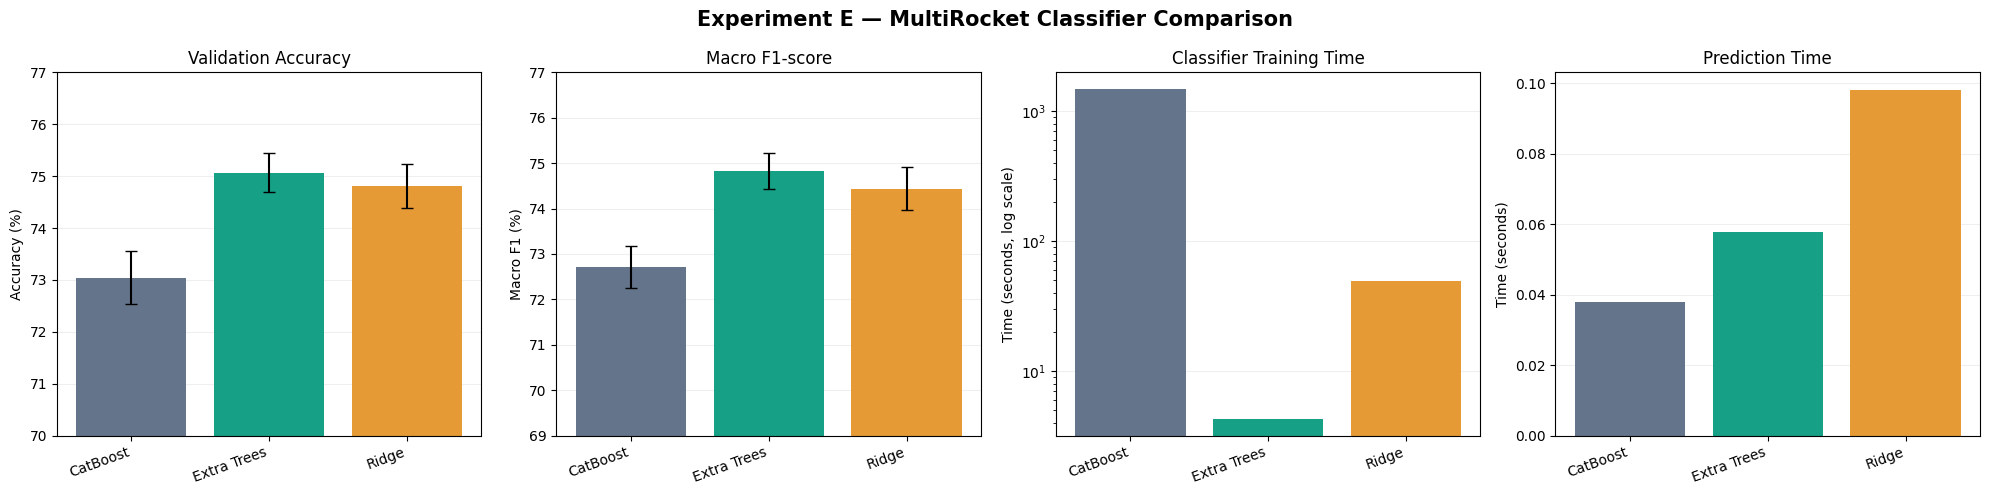

In [ ]:

# Experiment E — Combined visual comparison

import matplotlib.pyplot as plt
import numpy as np

df = classifier_comparison_df.copy()

colors = ["#64748b", "#16a085", "#e59a36"]

fig, axes = plt.subplots(1, 4, figsize=(20, 5))

x = np.arange(len(df))
labels = df["Classifier"]

# 1. Validation accuracy
axes[0].bar(
    x, df["Accuracy mean (%)"],
    yerr=df["Accuracy std (%)"],
    capsize=4, color=colors
)
axes[0].set_title("Validation Accuracy")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(70, 77)

# 2. Macro F1
axes[1].bar(
    x, df["Macro F1 mean (%)"],
    yerr=df["Macro F1 std (%)"],
    capsize=4, color=colors
)
axes[1].set_title("Macro F1-score")
axes[1].set_ylabel("Macro F1 (%)")
axes[1].set_ylim(69, 77)

# 3. Training time — log scale
axes[2].bar(
    x, df["Training time mean (s)"],
    color=colors
)
axes[2].set_yscale("log")
axes[2].set_title("Classifier Training Time")
axes[2].set_ylabel("Time (seconds, log scale)")

# 4. Prediction time
axes[3].bar(
    x, df["Prediction time mean (s)"],
    color=colors
)
axes[3].set_title("Prediction Time")
axes[3].set_ylabel("Time (seconds)")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=20, ha="right")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.suptitle(
    "Experiment E — MultiRocket Classifier Comparison",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()


##### Part 6 - Save experimental results

In [ ]:

# Experiment E: Save all classifier comparison results

classifier_seed_df.to_csv(
    RESULTS_DIR / "07_classifier_comparison_by_seed.csv",
    index=False
)

classifier_comparison_df.to_csv(
    RESULTS_DIR / "07_classifier_comparison_summary.csv",
    index=False
)

print("Experiment E results saved successfully.")
print("Output directory:", RESULTS_DIR.resolve())


Experiment E results saved successfully.
Output directory: /Users/joviyalrose.a/FILES/UCD/AUTUMN/AITS_LAB/MultiRocket/results/improvements_new



### Results and Reflection

Extra Trees achieved the best validation performance, with 75.07% accuracy and 74.83% macro F1, marginally outperforming the original Ridge classifier. It also trained approximately 11.5 times faster.

This suggests that the MultiRocket features contain some useful nonlinear relationships that a tree-based ensemble can exploit. However, the relatively small performance improvement indicates that the original features are already effective with a linear classifier.

CatBoost performed worse despite its substantially higher computational cost, demonstrating that a more complex classifier does not necessarily produce better results.

**Key finding:** Extra Trees provides the best balance between predictive performance and training efficiency in this experiment. The improvement is modest and should not be considered statistically significant without further testing.



## Experiment F — Extending MultiRocket with Alternative Pooling Operators
*Implementation and experimental evaluation: Joviyal*



### Research Question

Can additional pooling operators capture useful information from MultiRocket's convolution responses and improve its time-series classification performance?

The original MultiRocket representation uses four pooling operators:

- **PPV:** Proportion of positive convolution responses.
- **LSPV:** Longest stretch of positive responses.
- **MPV:** Mean of positive convolution responses.
- **MIPV:** Mean index of positive responses.

Three additional operators are investigated:

- **TP-PPV:** Divides the response sequence into early, middle and late regions to retain coarse temporal distribution information.
- **LSE:** Uses a smooth maximum-like aggregation of positive threshold exceedances.
- **GeM:** Uses a power mean that gives greater emphasis to stronger positive responses.

Five configurations are evaluated using the same convolution parameters, data split and Ridge classifier across five random seeds. The held-out test set remains untouched.

The objective is to determine whether these operators provide complementary information and whether the resulting performance improvements justify their additional feature dimensionality and computational cost.



### 6.1 Preliminary Analysis - Contribution of Original Pooling Operators

Before extending MultiRocket, the original four pooling operators are examined through leave-one-operator-out ablation.

Each operator is removed individually while retaining the remaining three. The resulting changes in validation accuracy and macro F1 indicate how much each operator contributes to the complete feature representation.

This analysis provides a baseline for understanding the original pooling behaviour and motivates the investigation of complementary feature aggregation strategies.


In [ ]:

# Experiment F: Inspect existing pooling ablation results

print("ORIGINAL POOLING OPERATOR ABLATION")
display(pooling_ablation_df.round(4))

print("\nDIRECT MPV REMOVAL RESULTS")
display(mpv_summary_df.round(4))

# Rank the original operators by the effect of removing them.
pooling_effect_df = pooling_ablation_df.copy()

baseline_pooling_accuracy = pooling_effect_df.loc[
    pooling_effect_df["Configuration"] == "All four operators",
    "Validation accuracy mean (%)"
].iloc[0]

baseline_pooling_f1 = pooling_effect_df.loc[
    pooling_effect_df["Configuration"] == "All four operators",
    "Validation macro F1 mean (%)"
].iloc[0]

pooling_effect_df["Accuracy change vs full (pp)"] = (
    pooling_effect_df["Validation accuracy mean (%)"]
    - baseline_pooling_accuracy
)

pooling_effect_df["Macro F1 change vs full (pp)"] = (
    pooling_effect_df["Validation macro F1 mean (%)"]
    - baseline_pooling_f1
)

print("\nEFFECT OF REMOVING EACH ORIGINAL OPERATOR")
display(
    pooling_effect_df[
        [
            "Configuration",
            "Features",
            "Accuracy change vs full (pp)",
            "Macro F1 change vs full (pp)"
        ]
    ].round(4)
)


ORIGINAL POOLING OPERATOR ABLATION


,Configuration,Features,Validation accuracy mean (%),Validation accuracy std (%),Validation macro F1 mean (%),Validation macro F1 std (%),Classifier fit mean (s),Prediction mean (s)
0,All four operators,4704,74.8056,0.4207,74.4394,0.4684,50.6516,0.0807
1,Without LSPV,3528,74.6111,0.4097,74.1394,0.3732,28.7584,0.0575
2,Without MIPV,3528,74.0833,0.6466,73.6540,0.7046,29.0157,0.0530
3,Without MPV,3528,74.5972,0.3416,74.2233,0.3510,29.1150,0.0522
4,Without PPV,3528,74.3472,0.2060,73.9200,0.2170,29.2372,0.0513



DIRECT MPV REMOVAL RESULTS


,Seed,Original features,No-MPV features,Original validation accuracy (%),No-MPV validation accuracy (%),Accuracy difference (pp),Original extraction median (s),No-MPV extraction median (s),Extraction time change (%)
mean,2.0000,4704.0,3528.0,74.8056,74.5972,-0.2083,0.3016,0.2030,-32.6586
std,1.5811,0.0,0.0,0.4207,0.3416,0.4108,0.0308,0.0265,5.7293



EFFECT OF REMOVING EACH ORIGINAL OPERATOR


,Configuration,Features,Accuracy change vs full (pp),Macro F1 change vs full (pp)
0,All four operators,4704,0.0000,0.0000
1,Without LSPV,3528,-0.1944,-0.3000
2,Without MIPV,3528,-0.7222,-0.7854
3,Without MPV,3528,-0.2083,-0.2161
4,Without PPV,3528,-0.4583,-0.5193


In [ ]:
# Experiment F: Build enhanced MultiRocket transform
# The original multirocket.py is read but never modified.

import inspect
import re
import importlib
from pathlib import Path

original_module_path = PROJECT_ROOT / "multirocket" / "multirocket.py"
enhanced_module_path = PROJECT_ROOT / "multirocket" / "multirocket_enhanced.py"

assert original_module_path.exists(), (
    f"Original MultiRocket source not found: {original_module_path}"
)

# Obtain the Python source behind the imported Numba dispatcher.
original_transform_source = inspect.getsource(transform.py_func)

# Rename the function in the copied source.
enhanced_source = original_transform_source.replace(
    "def transform(",
    "def transform_enhanced(",
    1
)

assert "def transform_enhanced(" in enhanced_source

# Allocate nine feature blocks per transformation instead of four.
# The original four blocks remain in exactly the same order.
old_offset_line = (
    "n_features_per_transform = np.int64(features.shape[1] / 2)"
)

new_offset_line = (
    "n_features_per_transform = np.int64(9 * num_features)"
)

assert enhanced_source.count(old_offset_line) == 1
enhanced_source = enhanced_source.replace(
    old_offset_line, new_offset_line, 1
)


def add_new_pooling_blocks(source_segment, transform_offset, feature_count):
    """
    Add TP-PPV (3 features), LSE (1 feature) and GeM (1 feature)
    immediately after the four original pooling blocks.
    """
    pattern = re.compile(
        r"(?m)^(\s*)features\[example_index, end\] = "
        r"mean_index / ppv if ppv > 0 else -1\s*$"
    )

    matches = list(pattern.finditer(source_segment))
    assert len(matches) == 2, (
        f"Expected two original pooling branches, found {len(matches)}."
    )

    branch_number = 0

    def replacement(match):
        nonlocal branch_number

        indent = match.group(1)
        values_name = "C" if branch_number == 0 else "_c"
        branch_number += 1

        # The first four blocks are unchanged. New features occupy
        # blocks 4, 5, 6, 7 and 8.
        extra_offset = (
            f"feature_index + {transform_offset} + "
            f"4 * {feature_count}"
        )

        return (
            match.group(0)
            + "\n"
            + indent + "# Additional pooling: temporal pyramid PPV\n"
            + indent + f"values = {values_name}\n"
            + indent + "n_response = values.shape[0]\n"
            + indent + "cut_1 = n_response // 3\n"
            + indent + "cut_2 = (2 * n_response) // 3\n"
            + indent + "early_count = 0\n"
            + indent + "middle_count = 0\n"
            + indent + "late_count = 0\n"
            + indent + "for j in range(n_response):\n"
            + indent + "    if values[j] > _bias:\n"
            + indent + "        if j < cut_1:\n"
            + indent + "            early_count += 1\n"
            + indent + "        elif j < cut_2:\n"
            + indent + "            middle_count += 1\n"
            + indent + "        else:\n"
            + indent + "            late_count += 1\n"
            + indent + f"features[example_index, {extra_offset}] = "
              "early_count / max(cut_1, 1)\n"
            + indent + f"features[example_index, {extra_offset} + "
              f"{feature_count}] = "
              "middle_count / max(cut_2 - cut_1, 1)\n"
            + indent + f"features[example_index, {extra_offset} + "
              f"2 * {feature_count}] = "
              "late_count / max(n_response - cut_2, 1)\n"
            + indent + "\n"
            + indent + "# Positive threshold exceedances for LSE and GeM\n"
            + indent + "max_excess = 0.0\n"
            + indent + "gem_sum = 0.0\n"
            + indent + "for j in range(n_response):\n"
            + indent + "    excess = values[j] - _bias\n"
            + indent + "    if excess < 0:\n"
            + indent + "        excess = 0.0\n"
            + indent + "    if excess > max_excess:\n"
            + indent + "        max_excess = excess\n"
            + indent + "    gem_sum += excess * excess * excess\n"
            + indent + "\n"
            + indent + "# Numerically stable, length-normalised LSE (beta=1)\n"
            + indent + "exp_sum = 0.0\n"
            + indent + "for j in range(n_response):\n"
            + indent + "    excess = values[j] - _bias\n"
            + indent + "    if excess < 0:\n"
            + indent + "        excess = 0.0\n"
            + indent + "    exp_sum += np.exp(excess - max_excess)\n"
            + indent + "lse_value = max_excess + np.log("
              "exp_sum / n_response)\n"
            + indent + f"features[example_index, {extra_offset} + "
              f"3 * {feature_count}] = lse_value\n"
            + indent + "\n"
            + indent + "# GeM with power p=3, including zero exceedances\n"
            + indent + "gem_value = (gem_sum / n_response) ** (1.0 / 3.0)\n"
            + indent + f"features[example_index, {extra_offset} + "
              f"4 * {feature_count}] = gem_value"
        )

    updated_segment = pattern.sub(replacement, source_segment)
    assert branch_number == 2
    return updated_segment


# Separate original-series and difference-series code.
difference_marker = "        # First order difference"
assert enhanced_source.count(difference_marker) == 1

base_source, difference_source = enhanced_source.split(
    difference_marker, 1
)

# Base transformation: its additional blocks start after its four
# original blocks.
base_source = add_new_pooling_blocks(
    base_source,
    transform_offset="0",
    feature_count="num_features"
)

# Difference transformation: its additional blocks start after its
# four original blocks, at the enhanced difference offset.
difference_source = add_new_pooling_blocks(
    difference_source,
    transform_offset="n_features_per_transform",
    feature_count="num_features1"
)

enhanced_source = base_source + difference_marker + difference_source

module_text = (
    '"""MultiRocket transform extended with additional pooling operators."""\n'
    "import numpy as np\n"
    "from numba import njit, prange\n\n"
    + enhanced_source
    + "\n"
)

enhanced_module_path.write_text(module_text, encoding="utf-8")

importlib.invalidate_caches()
sys.modules.pop("multirocket.multirocket_enhanced", None)

from multirocket.multirocket_enhanced import transform_enhanced

print("Enhanced module created:", enhanced_module_path)
print("Original source unchanged:", original_module_path.exists())
print("Enhanced transform imported successfully.")

Enhanced module created: /Users/joviyalrose.a/FILES/UCD/AUTUMN/AITS_LAB/MultiRocket/multirocket/multirocket_enhanced.py
Original source unchanged: True
Enhanced transform imported successfully.



### 6.2 Implementation Verification - Original Feature Equivalence

Before evaluating the extensions, the enhanced transform is verified against the original MultiRocket implementation.

The original four pooling blocks are reproduced using identical fitted convolution parameters. The maximum absolute difference is zero, confirming that the original feature calculations remain unchanged.

This verification ensures that subsequent performance differences are attributable to the selected pooling representation rather than unintended changes to the original convolution calculations.


In [ ]:
# Experiment F: Strict F0 equivalence test
# Uses training samples only.

check_n = min(20, len(X_subtrain))

X_check = np.ascontiguousarray(
    X_subtrain[:check_n], dtype=np.float64
)
D_check = np.ascontiguousarray(
    np.diff(X_check, axis=1), dtype=np.float64
)

set_numba_seed(RANDOM_STATE)

bp_check = fit(X_check, num_features=FULL_KERNELS)
dp_check = fit(D_check, num_features=FULL_KERNELS)

# Original transform: four pooling operators.
F_original_check = transform(
    X_check, D_check, bp_check, dp_check, 4
)

# Enhanced transform: nine pooling operators.
F_enhanced_check = transform_enhanced(
    X_check, D_check, bp_check, dp_check, 9
)

# Feature counts for the two transformations.
n_base_check = 84 * int(np.sum(bp_check[1]))
n_diff_check = 84 * int(np.sum(dp_check[1]))

# Select only the original four blocks from the enhanced output.
base_original_columns = F_enhanced_check[
    :, :4 * n_base_check
]

diff_start_enhanced = 9 * n_base_check
diff_original_columns = F_enhanced_check[
    :, diff_start_enhanced:
       diff_start_enhanced + 4 * n_diff_check
]

F0_check = np.concatenate(
    [base_original_columns, diff_original_columns],
    axis=1
)

assert F0_check.shape == F_original_check.shape, (
    F0_check.shape, F_original_check.shape
)

max_abs_difference = float(
    np.max(np.abs(F_original_check - F0_check))
)

print("Original feature shape:", F_original_check.shape)
print("Enhanced F0 shape:", F0_check.shape)
print("Maximum absolute difference:", max_abs_difference)

assert np.allclose(
    F_original_check,
    F0_check,
    rtol=1e-5,
    atol=1e-5
), "F0 does not reproduce the original MultiRocket features."

print("\nF0 equivalence verification PASSED.")

Original feature shape: (20, 4704)
Enhanced F0 shape: (20, 4704)
Maximum absolute difference: 0.0

F0 equivalence verification PASSED.



### 6.3 Evaluation of Additional Pooling Operators

Five configurations are evaluated to isolate the individual and combined effects of the new operators.

| Configuration | Pooling operators |
|---|---|
| F0 | Original four |
| F1 | Original + TP-PPV |
| F2 | Original + LSE |
| F3 | Original + GeM |
| F4 | Original + TP-PPV + LSE + GeM |

All configurations use the same training and validation split, fitted convolution parameters and Ridge classifier.

The enhanced transform computes the pooling blocks together, after which the required feature blocks are selected for each configuration. Performance is measured using five seeds.


In [ ]:
# Experiment F: Feature-block selection

POOLING_CONFIGURATIONS = {
    "F0 - Original": [0, 1, 2, 3],
    "F1 - Original + TP-PPV": [0, 1, 2, 3, 4, 5, 6],
    "F2 - Original + LSE": [0, 1, 2, 3, 7],
    "F3 - Original + GeM": [0, 1, 2, 3, 8],
    "F4 - Original + All": list(range(9))
}


def select_pooling_blocks(features, n_base, n_diff, selected_blocks):
    """
    Select the same pooling blocks from both:
    1. Original time-series transformation
    2. First-order difference transformation
    """
    base_parts = [
        features[:, block * n_base:(block + 1) * n_base]
        for block in selected_blocks
    ]

    diff_start = 9 * n_base

    diff_parts = [
        features[
            :,
            diff_start + block * n_diff:
            diff_start + (block + 1) * n_diff
        ]
        for block in selected_blocks
    ]

    return np.concatenate(base_parts + diff_parts, axis=1)


# Basic feature-selection checks using the verification sample.
for config_name, selected_blocks in POOLING_CONFIGURATIONS.items():
    selected = select_pooling_blocks(
        F_enhanced_check,
        n_base_check,
        n_diff_check,
        selected_blocks
    )

    expected_features = len(selected_blocks) * (
        n_base_check + n_diff_check
    )

    assert selected.shape == (check_n, expected_features)
    assert np.isfinite(selected).all()

    print(
        f"{config_name}: "
        f"{selected.shape[1]:,} features"
    )

print("\nAll pooling configurations passed feature-selection checks.")

F0 - Original: 4,704 features
F1 - Original + TP-PPV: 8,232 features
F2 - Original + LSE: 5,880 features
F3 - Original + GeM: 5,880 features
F4 - Original + All: 10,584 features

All pooling configurations passed feature-selection checks.


In [ ]:
# Experiment F: Five-seed validation comparison

pooling_extension_rows = []

Xfit_pool = np.ascontiguousarray(
    X_subtrain, dtype=np.float64
)
Xval_pool = np.ascontiguousarray(
    X_val, dtype=np.float64
)

Dfit_pool = np.ascontiguousarray(
    np.diff(Xfit_pool, axis=1), dtype=np.float64
)
Dval_pool = np.ascontiguousarray(
    np.diff(Xval_pool, axis=1), dtype=np.float64
)

for seed in SEEDS:

    print("\n" + "=" * 65)
    print(f"Experiment F — Seed {seed}")
    print("=" * 65)

    # Fit the original MultiRocket parameters on sub-training data only.
    set_numba_seed(int(seed))

    bp_pool = fit(
        Xfit_pool,
        num_features=FULL_KERNELS
    )
    dp_pool = fit(
        Dfit_pool,
        num_features=FULL_KERNELS
    )

    n_base = 84 * int(np.sum(bp_pool[1]))
    n_diff = 84 * int(np.sum(dp_pool[1]))

    # Warm-up the enhanced transform on a small training-only sample.
    warm_n = min(4, len(Xfit_pool))

    _ = transform_enhanced(
        Xfit_pool[:warm_n],
        Dfit_pool[:warm_n],
        bp_pool,
        dp_pool,
        9
    )

    # Measure the original transform for reference.
    start = time.perf_counter()

    F_original_train = transform(
        Xfit_pool, Dfit_pool, bp_pool, dp_pool, 4
    )
    F_original_val = transform(
        Xval_pool, Dval_pool, bp_pool, dp_pool, 4
    )

    original_transform_time = time.perf_counter() - start

    # Measure the enhanced transform once.
    start = time.perf_counter()

    F_enhanced_train = transform_enhanced(
        Xfit_pool, Dfit_pool, bp_pool, dp_pool, 9
    )
    F_enhanced_val = transform_enhanced(
        Xval_pool, Dval_pool, bp_pool, dp_pool, 9
    )

    enhanced_transform_time = time.perf_counter() - start

    F_enhanced_train = np.nan_to_num(
        F_enhanced_train,
        nan=0.0, posinf=0.0, neginf=0.0
    )
    F_enhanced_val = np.nan_to_num(
        F_enhanced_val,
        nan=0.0, posinf=0.0, neginf=0.0
    )

    # Ensure that the original feature blocks remain equivalent
    # for this seed as well.
    F0_train_check = select_pooling_blocks(
        F_enhanced_train, n_base, n_diff, [0, 1, 2, 3]
    )

    F0_val_check = select_pooling_blocks(
        F_enhanced_val, n_base, n_diff, [0, 1, 2, 3]
    )

    assert np.allclose(
        F_original_train, F0_train_check,
        rtol=1e-5, atol=1e-5
    )
    assert np.allclose(
        F_original_val, F0_val_check,
        rtol=1e-5, atol=1e-5
    )

    print(
        f"Original transform: {original_transform_time:.3f}s | "
        f"Enhanced transform: {enhanced_transform_time:.3f}s"
    )

    # Evaluate every pooling configuration with the same Ridge classifier.
    for config_name, selected_blocks in POOLING_CONFIGURATIONS.items():

        F_train_config = select_pooling_blocks(
            F_enhanced_train,
            n_base,
            n_diff,
            selected_blocks
        )

        F_val_config = select_pooling_blocks(
            F_enhanced_val,
            n_base,
            n_diff,
            selected_blocks
        )

        evaluation = score_classifier(
            ridge_classifier(),
            F_train_config,
            y_subtrain,
            F_val_config,
            y_val
        )

        row = {
            "Seed": seed,
            "Configuration": config_name,
            "Features": F_train_config.shape[1],
            "Validation accuracy (%)": evaluation["accuracy_pct"],
            "Validation macro F1 (%)": evaluation["macro_f1_pct"],
            "Original transform time (s)": original_transform_time,
            "Enhanced transform time (s)": enhanced_transform_time,
            "Classifier fit time (s)": evaluation["classifier_fit_s"],
            "Prediction time (s)": evaluation["prediction_s"]
        }

        pooling_extension_rows.append(row)

        print(
            f"{config_name}: "
            f"Accuracy={evaluation['accuracy_pct']:.2f}% | "
            f"Macro F1={evaluation['macro_f1_pct']:.2f}% | "
            f"Features={F_train_config.shape[1]:,}"
        )

        del F_train_config, F_val_config, evaluation

    del (
        F_original_train, F_original_val,
        F_enhanced_train, F_enhanced_val,
        F0_train_check, F0_val_check
    )
    gc.collect()


pooling_extension_df = pd.DataFrame(pooling_extension_rows)

print("\nPER-SEED POOLING EXTENSION RESULTS")
display(pooling_extension_df.round(4))

pooling_extension_df.to_csv(
    RESULTS_DIR / "08_pooling_extension_by_seed.csv",
    index=False
)

print("Per-seed results saved.")


Experiment F — Seed 0
Original transform: 0.308s | Enhanced transform: 0.946s
F0 - Original: Accuracy=74.86% | Macro F1=74.55% | Features=4,704
F1 - Original + TP-PPV: Accuracy=75.90% | Macro F1=75.58% | Features=8,232
F2 - Original + LSE: Accuracy=75.35% | Macro F1=75.06% | Features=5,880
F3 - Original + GeM: Accuracy=75.07% | Macro F1=74.74% | Features=5,880
F4 - Original + All: Accuracy=75.76% | Macro F1=75.49% | Features=10,584

Experiment F — Seed 1
Original transform: 0.328s | Enhanced transform: 0.997s
F0 - Original: Accuracy=74.10% | Macro F1=73.67% | Features=4,704
F1 - Original + TP-PPV: Accuracy=75.69% | Macro F1=75.32% | Features=8,232
F2 - Original + LSE: Accuracy=74.58% | Macro F1=74.22% | Features=5,880
F3 - Original + GeM: Accuracy=74.79% | Macro F1=74.43% | Features=5,880
F4 - Original + All: Accuracy=75.62% | Macro F1=75.30% | Features=10,584

Experiment F — Seed 2
Original transform: 0.302s | Enhanced transform: 0.943s
F0 - Original: Accuracy=74.86% | Macro F1=74.37

,Seed,Configuration,Features,Validation accuracy (%),Validation macro F1 (%),Original transform time (s),Enhanced transform time (s),Classifier fit time (s),Prediction time (s)
0,0,F0 - Original,4704,74.8611,74.5542,0.3084,0.9457,48.8592,0.0668
1,0,F1 - Original + TP-PPV,8232,75.9028,75.5798,0.3084,0.9457,37.6755,0.1320
2,0,F2 - Original + LSE,5880,75.3472,75.0551,0.3084,0.9457,34.3216,0.0649
3,0,F3 - Original + GeM,5880,75.0694,74.7354,0.3084,0.9457,33.9951,0.0832
4,0,F4 - Original + All,10584,75.7639,75.4928,0.3084,0.9457,41.3647,0.2179
5,1,F0 - Original,4704,74.0972,73.6700,0.3282,0.9970,48.3702,0.0887
6,1,F1 - Original + TP-PPV,8232,75.6944,75.3221,0.3282,0.9970,36.8769,0.0688
7,1,F2 - Original + LSE,5880,74.5833,74.2243,0.3282,0.9970,33.8016,0.0600
8,1,F3 - Original + GeM,5880,74.7917,74.4276,0.3282,0.9970,33.9307,0.0539
9,1,F4 - Original + All,10584,75.6250,75.3021,0.3282,0.9970,38.5831,0.1064


Per-seed results saved.


In [ ]:
# Experiment F: Aggregate five-seed results

pooling_extension_summary_df = (
    pooling_extension_df
    .groupby("Configuration", as_index=False)
    .agg(
        **{
            "Features": ("Features", "mean"),
            "Accuracy mean (%)": (
                "Validation accuracy (%)", "mean"
            ),
            "Accuracy std (%)": (
                "Validation accuracy (%)", "std"
            ),
            "Macro F1 mean (%)": (
                "Validation macro F1 (%)", "mean"
            ),
            "Macro F1 std (%)": (
                "Validation macro F1 (%)", "std"
            ),
            "Original transform mean (s)": (
                "Original transform time (s)", "mean"
            ),
            "Enhanced transform mean (s)": (
                "Enhanced transform time (s)", "mean"
            ),
            "Classifier fit mean (s)": (
                "Classifier fit time (s)", "mean"
            ),
            "Prediction mean (s)": (
                "Prediction time (s)", "mean"
            )
        }
    )
)

baseline_f0_accuracy = pooling_extension_summary_df.loc[
    pooling_extension_summary_df["Configuration"] == "F0 - Original",
    "Accuracy mean (%)"
].iloc[0]

baseline_f0_f1 = pooling_extension_summary_df.loc[
    pooling_extension_summary_df["Configuration"] == "F0 - Original",
    "Macro F1 mean (%)"
].iloc[0]

pooling_extension_summary_df["Accuracy change vs F0 (pp)"] = (
    pooling_extension_summary_df["Accuracy mean (%)"]
    - baseline_f0_accuracy
)

pooling_extension_summary_df["Macro F1 change vs F0 (pp)"] = (
    pooling_extension_summary_df["Macro F1 mean (%)"]
    - baseline_f0_f1
)

print("POOLING EXTENSION — FIVE-SEED SUMMARY")
display(pooling_extension_summary_df.round(4))

pooling_extension_summary_df.to_csv(
    RESULTS_DIR / "09_pooling_extension_summary.csv",
    index=False
)

POOLING EXTENSION — FIVE-SEED SUMMARY


,Configuration,Features,Accuracy mean (%),Accuracy std (%),Macro F1 mean (%),Macro F1 std (%),Original transform mean (s),Enhanced transform mean (s),Classifier fit mean (s),Prediction mean (s),Accuracy change vs F0 (pp),Macro F1 change vs F0 (pp)
0,F0 - Original,4704.0,74.8056,0.4207,74.4394,0.4684,0.307,0.9282,48.7686,0.0652,0.0000,0.0000
1,F1 - Original + TP-PPV,8232.0,75.6806,0.2048,75.3667,0.1945,0.307,0.9282,36.7780,0.0863,0.8750,0.9274
2,F2 - Original + LSE,5880.0,75.1389,0.3472,74.8078,0.3968,0.307,0.9282,33.7929,0.0631,0.3333,0.3685
3,F3 - Original + GeM,5880.0,75.0556,0.1584,74.7076,0.1926,0.307,0.9282,33.8039,0.0639,0.2500,0.2682
4,F4 - Original + All,10584.0,75.8472,0.1927,75.5728,0.2243,0.307,0.9282,39.3344,0.1449,1.0417,1.1335


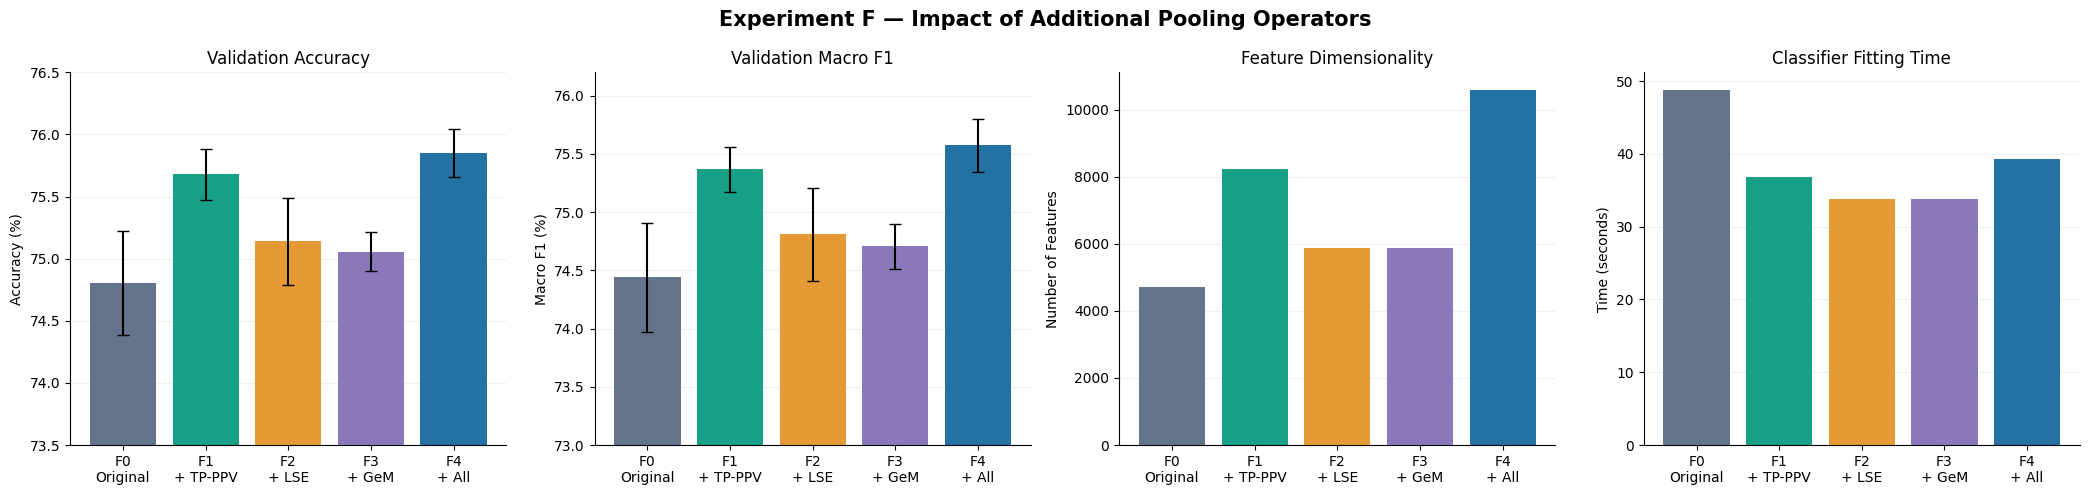

In [ ]:

# Experiment F — Four-panel results comparison

import matplotlib.pyplot as plt
import numpy as np

plot_results = (
    pooling_extension_summary_df
    .copy()
    .reset_index(drop=True)
)

labels = [
    "F0\nOriginal",
    "F1\n+ TP-PPV",
    "F2\n+ LSE",
    "F3\n+ GeM",
    "F4\n+ All"
]

x = np.arange(len(plot_results))

# Consistent colours for the configurations
colors = [
    "#64748b",  # Original
    "#16a085",  # TP-PPV
    "#e59a36",  # LSE
    "#8b78b8",  # GeM
    "#2471a3"   # Combined
]

fig, axes = plt.subplots(1, 4, figsize=(21, 5))

# 1. Accuracy
axes[0].bar(
    x,
    plot_results["Accuracy mean (%)"],
    yerr=plot_results["Accuracy std (%)"],
    capsize=4,
    color=colors
)
axes[0].set_title("Validation Accuracy")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(73.5, 76.5)

# 2. Macro F1
axes[1].bar(
    x,
    plot_results["Macro F1 mean (%)"],
    yerr=plot_results["Macro F1 std (%)"],
    capsize=4,
    color=colors
)
axes[1].set_title("Validation Macro F1")
axes[1].set_ylabel("Macro F1 (%)")
axes[1].set_ylim(73, 76.2)

# 3. Feature dimensionality
axes[2].bar(
    x,
    plot_results["Features"],
    color=colors
)
axes[2].set_title("Feature Dimensionality")
axes[2].set_ylabel("Number of Features")

# 4. Classifier fitting time
axes[3].bar(
    x,
    plot_results["Classifier fit mean (s)"],
    color=colors
)
axes[3].set_title("Classifier Fitting Time")
axes[3].set_ylabel("Time (seconds)")

for ax in axes:
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

fig.suptitle(
    "Experiment F — Impact of Additional Pooling Operators",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()



### Results and Reflection

The combined configuration (F4) achieved the best performance, with **75.85% accuracy and 75.57% macro F1**, improving upon the original baseline by 1.04 and 1.13 percentage points, respectively.

Among the individual extensions, TP-PPV (F1) produced the largest improvement, achieving 75.68% accuracy. This suggests that retaining coarse temporal information about where convolution responses occur can provide useful information beyond global pooling statistics. LSE and GeM also improved performance, although their individual contributions were smaller.

The original pooling ablation showed that MIPV had the largest observed contribution among the original operators. Together, these findings suggest that different pooling strategies capture distinct characteristics of the convolution responses, including activation occurrence, temporal location and response magnitude.

However, the improvement comes with increased complexity. F4 uses 10,584 features compared with 4,704 in the original representation, and the enhanced transformation takes approximately 0.93 seconds compared with 0.31 seconds for the original transform. F1 offers a more compact alternative, achieving competitive performance with 8,232 features.

**Key finding:** The results support the use of complementary pooling operators rather than replacing the original MultiRocket representation. Combining temporal and magnitude-based statistics produces the strongest validation performance in this experiment. However, the improvements are modest and have not been established as statistically significant.


## Experiment G - New-Only Pooling
*Implementation and experimental evaluation: Joviyal*

### Research Question

Can the newly introduced pooling operators independently produce a useful feature representation for time-series classification, without using the original MultiRocket pooling operators?

In Experiment F, the new pooling operators were added to the original MultiRocket representation. However, their individual contribution does not establish whether they can work effectively on their own.

This experiment evaluates a new-only configuration (G0), retaining only the following operators:

- **TP-PPV:** Captures the proportion of positive convolution responses across three temporal regions.
- **LSE:** Uses a smooth maximum-like aggregation to capture strong positive responses.
- **GeM:** Uses a power mean to represent the magnitude of positive responses.

The original PPV, LSPV, MPV and MIPV features are excluded. G0 is evaluated using the same five random seeds, data splits and Ridge classifier as the previous experiments.

The objective is to determine whether the new pooling operators can independently preserve useful classification information, and how their performance compares with the original and combined feature representations.

In [ ]:
import time
import numpy as np
import pandas as pd

from sklearn.metrics import accuracy_score, f1_score

# New-only pooling: blocks 4, 5, 6, 7 and 8
# Blocks 4-6 = TP-PPV
# Block 7 = LSE
# Block 8 = GeM

new_only_results = []

for seed in SEEDS:

    print(f"\nRunning G0 - New-only pooling | Seed {seed}")

    np.random.seed(seed)

    # First-order differences
    X1_subtrain = np.diff(X_subtrain, axis=1)
    X1_val = np.diff(X_val, axis=1)

    # Fit parameters using training data only
    base_params = fit(X_subtrain, num_features=FULL_KERNELS)
    diff_params = fit(X1_subtrain, num_features=FULL_KERNELS)

    n_base = 84 * np.sum(base_params[1])
    n_diff = 84 * np.sum(diff_params[1])

    # Transform training and validation data
    start = time.perf_counter()

    Z_train = transform_enhanced(
        X_subtrain, X1_subtrain,
        base_params, diff_params, 9
    )

    Z_val = transform_enhanced(
        X_val, X1_val,
        base_params, diff_params, 9
    )

    enhanced_time = time.perf_counter() - start

    Z_train = np.nan_to_num(Z_train)
    Z_val = np.nan_to_num(Z_val)

    # Select only the five new pooling blocks
    base_blocks_train = [
        Z_train[:, b*n_base:(b+1)*n_base]
        for b in range(4, 9)
    ]

    diff_start = 9 * n_base

    diff_blocks_train = [
        Z_train[:, diff_start + b*n_diff:
                   diff_start + (b+1)*n_diff]
        for b in range(4, 9)
    ]

    base_blocks_val = [
        Z_val[:, b*n_base:(b+1)*n_base]
        for b in range(4, 9)
    ]

    diff_blocks_val = [
        Z_val[:, diff_start + b*n_diff:
                 diff_start + (b+1)*n_diff]
        for b in range(4, 9)
    ]

    X_train_G0 = np.concatenate(
        base_blocks_train + diff_blocks_train, axis=1
    )

    X_val_G0 = np.concatenate(
        base_blocks_val + diff_blocks_val, axis=1
    )

    # Check feature dimensions
    assert X_train_G0.shape[1] == 5880
    assert X_val_G0.shape[1] == 5880

    # Train and evaluate Ridge classifier
    clf = ridge_classifier()

    start = time.perf_counter()
    clf.fit(X_train_G0, y_subtrain)
    classifier_time = time.perf_counter() - start

    start = time.perf_counter()
    predictions = clf.predict(X_val_G0)
    prediction_time = time.perf_counter() - start

    accuracy = accuracy_score(y_val, predictions) * 100
    macro_f1 = f1_score(y_val, predictions, average="macro") * 100

    new_only_results.append({
        "Seed": seed,
        "Configuration": "G0 - New-only",
        "Features": X_train_G0.shape[1],
        "Accuracy (%)": accuracy,
        "Macro F1 (%)": macro_f1,
        "Enhanced transform time (s)": enhanced_time,
        "Classifier fit time (s)": classifier_time,
        "Prediction time (s)": prediction_time
    })

    print(f"Features: {X_train_G0.shape[1]}")
    print(f"Accuracy: {accuracy:.4f}%")
    print(f"Macro F1: {macro_f1:.4f}%")

# Results table
g0_results = pd.DataFrame(new_only_results)

display(g0_results.round(4))

g0_results.to_csv(
    "10_new_only_pooling_by_seed.csv",
    index=False
)

print("\nG0 five-seed evaluation completed.")


Running G0 - New-only pooling | Seed 0
Features: 5880
Accuracy: 75.2083%
Macro F1: 74.7546%

Running G0 - New-only pooling | Seed 1
Features: 5880
Accuracy: 75.4861%
Macro F1: 75.1748%

Running G0 - New-only pooling | Seed 2
Features: 5880
Accuracy: 75.0694%
Macro F1: 74.6008%

Running G0 - New-only pooling | Seed 3
Features: 5880
Accuracy: 75.2083%
Macro F1: 74.7385%

Running G0 - New-only pooling | Seed 4
Features: 5880
Accuracy: 75.4167%
Macro F1: 75.0515%


,Seed,Configuration,Features,Accuracy (%),Macro F1 (%),Enhanced transform time (s),Classifier fit time (s),Prediction time (s)
0,0,G0 - New-only,5880,75.2083,74.7546,0.9258,34.4156,0.0687
1,1,G0 - New-only,5880,75.4861,75.1748,0.8746,34.5967,0.0582
2,2,G0 - New-only,5880,75.0694,74.6008,0.8861,36.7770,0.0896
3,3,G0 - New-only,5880,75.2083,74.7385,1.0801,42.4226,0.1153
4,4,G0 - New-only,5880,75.4167,75.0515,0.9961,35.9129,0.0989



G0 five-seed evaluation completed.


### Experiments F and G: Comparative Analysis of Pooling Strategies

Experiments F and G evaluated whether the new pooling operators could improve the original MultiRocket representation or work independently.

##### 1. Independent contribution of new operators

G0 (new-only) achieved **75.28% accuracy and 74.86% macro F1**, outperforming the original F0 (74.81% and 74.44%). This demonstrates that the new operators can independently provide useful classification features.Interestingly, G0 also outperformed F2 and F3, despite all three configurations containing 5,880 features.

##### 2. Complementarity of pooling operators

G0 did not outperform F1 (Original + TP-PPV) or F4 (Original + All). F4 achieved the best overall performance, with **75.85% accuracy and 75.57% macro F1**, suggesting that the original and new operators capture complementary information.
TP-PPV was the strongest individual extension, achieving 75.68% accuracy and 75.37% macro F1. Its division of convolution responses into early, middle and late regions suggests that retaining coarse temporal information can improve classification. LSE and GeM provide additional magnitude-based statistics.

##### 3. Feature complexity and computational trade-offs

G0 uses 5,880 features, approximately **44.4% fewer than F4** (10,584), with a modest reduction in predictive performance. It therefore offers a more compact alternative.The enhanced transformation takes approximately 0.95 seconds for G0 and 0.93 seconds for the F configurations. This is because all additional pooling blocks are calculated before feature selection; consequently, reducing the selected feature count does not substantially reduce transformation time.

**Overall finding:** The new operators are useful independently, but combining them with the original pooling operators achieves the strongest observed performance. TP-PPV provides the most notable individual contribution, while the combined representation offers the best balance of extracted information and classification performance.

In [ ]:
from pathlib import Path

# Results directory already defined in your notebook
results_dir = Path(PROJECT_ROOT) / "results" / "improvements_new"

# Load Experiment F summary
f_results = pd.read_csv(
    results_dir / "09_pooling_extension_summary.csv"
)

# G0 results from the completed Experiment G
g_results = pd.DataFrame(g0_results)

# Build G0 summary using the actual five-seed results
g0_summary = pd.DataFrame([{
    "Configuration": "G0 - New-only",
    "Features": g_results["Features"].mean(),
    "Accuracy mean (%)": g_results["Accuracy (%)"].mean(),
    "Accuracy std (%)": g_results["Accuracy (%)"].std(),
    "Macro F1 mean (%)": g_results["Macro F1 (%)"].mean(),
    "Macro F1 std (%)": g_results["Macro F1 (%)"].std(),
    "Classifier fit mean (s)": g_results["Classifier fit time (s)"].mean(),
    "Prediction mean (s)": g_results["Prediction time (s)"].mean()
}])

# Combine F and G0
comparison = pd.concat(
    [f_results, g0_summary],
    ignore_index=True
)

# Display the combined results
display(comparison.round(4))

comparison.to_csv(
    results_dir / "11_all_pooling_comparison.csv",
    index=False
)

,Configuration,Features,Accuracy mean (%),Accuracy std (%),Macro F1 mean (%),Macro F1 std (%),Original transform mean (s),Enhanced transform mean (s),Classifier fit mean (s),Prediction mean (s),Accuracy change vs F0 (pp),Macro F1 change vs F0 (pp)
0,F0 - Original,4704.0,74.8056,0.4207,74.4394,0.4684,0.307,0.9282,48.7686,0.0652,0.0000,0.0000
1,F1 - Original + TP-PPV,8232.0,75.6806,0.2048,75.3667,0.1945,0.307,0.9282,36.7780,0.0863,0.8750,0.9274
2,F2 - Original + LSE,5880.0,75.1389,0.3472,74.8078,0.3968,0.307,0.9282,33.7929,0.0631,0.3333,0.3685
3,F3 - Original + GeM,5880.0,75.0556,0.1584,74.7076,0.1926,0.307,0.9282,33.8039,0.0639,0.2500,0.2682
4,F4 - Original + All,10584.0,75.8472,0.1927,75.5728,0.2243,0.307,0.9282,39.3344,0.1449,1.0417,1.1335
5,G0 - New-only,5880.0,75.2778,0.1701,74.8640,0.2391,NaN,NaN,36.8250,0.0861,NaN,NaN


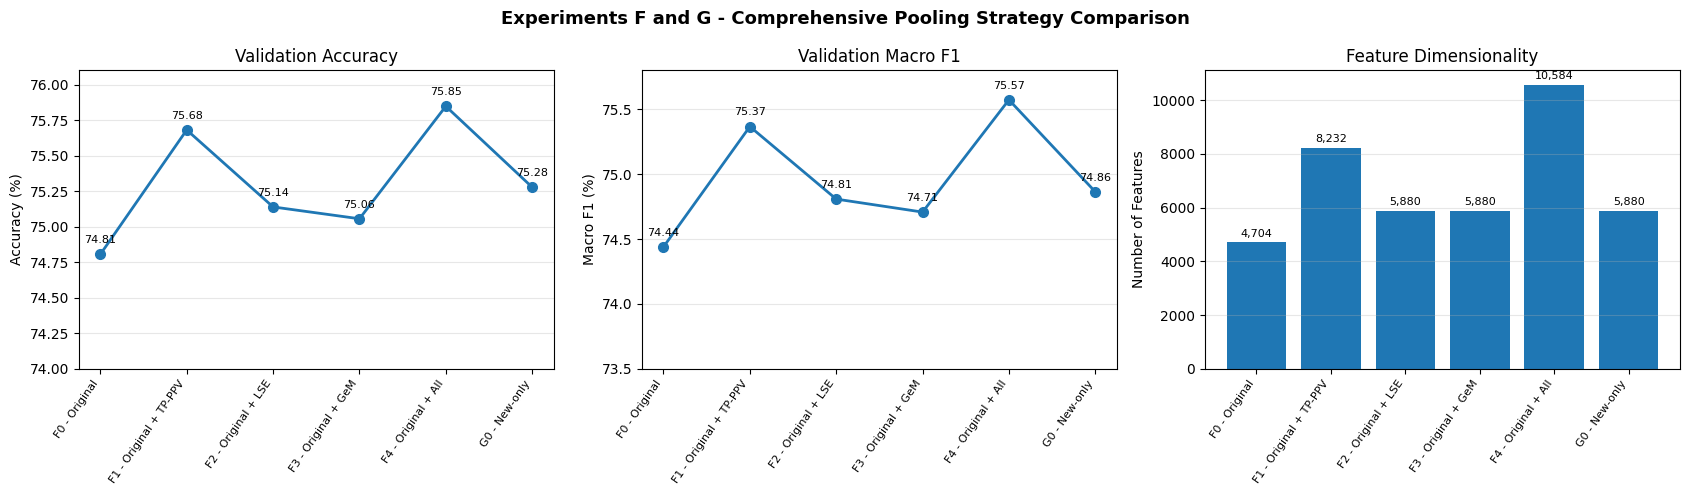

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Results from Experiments F and G
configurations = [
    "F0 - Original",
    "F1 - Original + TP-PPV",
    "F2 - Original + LSE",
    "F3 - Original + GeM",
    "F4 - Original + All",
    "G0 - New-only"
]

accuracy = [74.8056, 75.6806, 75.1389, 75.0556, 75.8472, 75.2778]
macro_f1 = [74.4394, 75.3667, 74.8078, 74.7076, 75.5728, 74.8640]
features = [4704, 8232, 5880, 5880, 10584, 5880]

x = np.arange(len(configurations))

fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# 1. Accuracy comparison
axes[0].plot(x, accuracy, marker="o", linewidth=2, markersize=7)
axes[0].set_title("Validation Accuracy")
axes[0].set_ylabel("Accuracy (%)")
axes[0].set_ylim(74.0, 76.1)
axes[0].set_xticks(x)
axes[0].set_xticklabels(configurations, rotation=55, ha="right", fontsize=8)
axes[0].grid(axis="y", alpha=0.3)

for i, value in enumerate(accuracy):
    axes[0].annotate(f"{value:.2f}", (i, value),
                     xytext=(0, 8), textcoords="offset points",
                     ha="center", fontsize=8)

# 2. Macro F1 comparison
axes[1].plot(x, macro_f1, marker="o", linewidth=2, markersize=7)
axes[1].set_title("Validation Macro F1")
axes[1].set_ylabel("Macro F1 (%)")
axes[1].set_ylim(73.5, 75.8)
axes[1].set_xticks(x)
axes[1].set_xticklabels(configurations, rotation=55, ha="right", fontsize=8)
axes[1].grid(axis="y", alpha=0.3)

for i, value in enumerate(macro_f1):
    axes[1].annotate(f"{value:.2f}", (i, value),
                     xytext=(0, 8), textcoords="offset points",
                     ha="center", fontsize=8)

# 3. Feature count comparison
axes[2].bar(x, features)
axes[2].set_title("Feature Dimensionality")
axes[2].set_ylabel("Number of Features")
axes[2].set_xticks(x)
axes[2].set_xticklabels(configurations, rotation=55, ha="right", fontsize=8)
axes[2].grid(axis="y", alpha=0.3)

for i, value in enumerate(features):
    axes[2].annotate(f"{value:,}", (i, value),
                     xytext=(0, 4), textcoords="offset points",
                     ha="center", fontsize=8)

fig.suptitle(
    "Experiments F and G - Comprehensive Pooling Strategy Comparison",
    fontsize=13,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### Results and Reflections: 

The comparison across all six configurations shows that F4 (Original + All) achieved the highest performance, with **75.85% accuracy and 75.57% macro F1**. F1 (Original + TP-PPV) was the strongest individual extension, achieving 75.68% accuracy and 75.37% macro F1.G0 (New-only) achieved 75.28% accuracy and 74.86% macro F1, outperforming the original F0 baseline (74.81% and 74.44%). It also outperformed F2 and F3, despite using the same number of features (5,880).However, G0 did not surpass F1 or F4. F4 achieved the best scores but required 10,584 features, compared with 5,880 for G0.

The results indicate that the new pooling operators can independently extract useful classification information. However, combining them with the original MultiRocket operators produces better performance.TP-PPV provides the strongest individual improvement, suggesting that preserving coarse temporal information is valuable. LSE and GeM provide additional improvements when combined with the other operators.Overall, F4 gives the best predictive performance, while G0 offers a more compact alternative. These are modest observed improvements across five random seeds on one dataset, rather than evidence of statistical significance or generalisation to all datasets.

## Overall Analysis of MultiRocket Pooling Strategies

MultiRocket generates features by applying convolution kernels to the original time series and its first-order differences. Instead of relying on a single statistic, it uses four pooling operators to capture different characteristics of the convolution responses. The original design combines these operators to produce a diverse feature representation.

In our initial pooling ablation, removing each operator reduced validation performance. Removing MIPV caused the largest observed decrease (approximately 0.72 percentage points in accuracy), followed by PPV. Removing MPV produced a smaller accuracy reduction of approximately 0.21 percentage points, while reducing feature extraction time by around 32.66%. This suggests that the original operators contribute differently, rather than being equally important.Building on this observation, Experiment F introduced three additional pooling strategies: **TP-PPV**, which preserves coarse temporal regions; **LSE**, which applies smooth maximum-like aggregation; and **GeM**, which captures response magnitudes through a power mean. Combining these with the original operators (F4) achieved the best result, with 75.85% accuracy and 75.57% macro F1.Experiment G then tested the new operators independently. The new-only configuration achieved 75.28% accuracy, outperforming the original baseline, but remained below the combined configuration.

**Overall finding:** MultiRocket benefits from diverse pooling representations. The original operators capture useful response statistics, while the new operators introduce additional temporal and magnitude-based information. Their combination achieved the strongest observed performance, suggesting that complementary pooling strategies can enrich the feature representation without changing the underlying convolution process.

*********************

## 8. Experiment D — Robustness to noisy and incomplete time series
*Implementation and experimental evaluation: Tavishi*

**Research Question:** How do noise, missing values and outliers affect the performance of MultiRocket, and can preprocessing improve its robustness? I also wanted to investigate whether the reduced-feature configurations are more sensitive to corrupted data than the original model.

**Leak-free validation protocol.** Robustness classifiers and MultiRocket kernel parameters are fitted on `X_subtrain` / `y_subtrain` only. Validation series are never used to fit classifiers, kernel parameters or feature selectors. The clean validation score is checked before corruption results are interpreted.

The validation comparison reports mean ± standard deviation across the same five seeds for:
- Clean controls: raw, Median-3, Local-MAD, interpolation and adaptive preprocessing.
- Gaussian noise at 10% and 20% of each series' standard deviation.
- Missing values at 10% and 20%, comparing per-series mean fill against interpolation and adaptive repair.
- Outliers at 2%, comparing raw, Median-3, tuned Local-MAD and adaptive repair.
- Combined Gaussian noise, missingness and outliers.
- Full MultiRocket, ANOVA-1000 and direct no-MPV feature representations.

Local-MAD window and threshold are selected on validation corruption results using a small grid. The clean-data false-positive flag rate is reported. The adaptive pipeline interpolates only when missing values occur, replaces only points flagged by Local-MAD, and otherwise leaves the input unchanged.

**Interpretation:** smoothing is not assumed to help. If filters reduce Gaussian-noise accuracy relative to raw input, report that as a negative result. The mean-fill comparison is included because zero-filling missing observations is an unfairly poor baseline.

The preprocessing strategy for each model and corruption condition was selected using validation results only. Section 8.2 then evaluates these frozen choices on the held-out test set using three fixed corruption seeds.

#### Required Setup and Feature Cache

The following cells initialise the No-MPV implementation and prepare the feature cache required for Experiment D. These dependencies are included to make the robustness experiment reproducible without rerunning the earlier feature-selection experiments.

In [ ]:
# Prepare only the feature cache required by Experiment D
selection_feature_cache = {}

for seed in SEEDS:
    print("Preparing D features for seed:", seed)

    F_sub_seed, F_val_seed, bp_seed, dp_seed, *_ = extract_features(
        X_subtrain,
        X_val,
        FULL_KERNELS,
        seed=seed
    )

    selection_feature_cache[seed] = (
        F_sub_seed,
        F_val_seed,
        bp_seed,
        dp_seed
    )

F_sub_full, F_val_full, selection_bp, selection_dp = (
    selection_feature_cache[SEEDS[0]]
)

print("Experiment D feature cache ready.")


Preparing D features for seed: 0
Preparing D features for seed: 1
Preparing D features for seed: 2
Preparing D features for seed: 3
Preparing D features for seed: 4
Experiment D feature cache ready.


In [ ]:
from multirocket.multirocket_without_mpv import (
    transform as transform_without_mpv
)

print("No-MPV implementation imported successfully!")

No-MPV implementation imported successfully!


In [23]:
# LEAK-FREE ROBUSTNESS EXPERIMENT
# All classifiers, selectors and kernel parameters are fitted on X_subtrain only.
# The same five seeds are used for model/kernel randomness and corruption draws.

ROBUSTNESS_SEEDS = list(SEEDS)

def add_gaussian_noise(X, relative_sigma=0.10, seed=42):
    rng = np.random.default_rng(seed)
    X = np.asarray(X, dtype=np.float64)
    row_std = np.std(X, axis=1, keepdims=True)
    return X + rng.normal(size=X.shape) * (relative_sigma * row_std)

def add_missing_values(X, missing_rate=0.10, seed=42):
    rng = np.random.default_rng(seed)
    Xc = np.asarray(X, dtype=np.float64).copy()
    Xc[rng.random(Xc.shape) < missing_rate] = np.nan
    return Xc


def add_outliers(X, outlier_rate=0.02, magnitude=6.0, seed=42):
    rng = np.random.default_rng(seed)
    Xc = np.asarray(X, dtype=np.float64).copy()

    mask = (rng.random(Xc.shape) < outlier_rate) & np.isfinite(Xc)

    # Calculate scale without allowing NaNs to corrupt row statistics.
    row_std = np.nanstd(Xc, axis=1, keepdims=True)
    row_std = np.where(np.isfinite(row_std), row_std, 0.0)

    signs = rng.choice([-1.0, 1.0], size=Xc.shape)
    scale = np.broadcast_to(row_std, Xc.shape)

    Xc[mask] += magnitude * scale[mask] * signs[mask]

    return Xc


def interpolate_missing_values(X):
    Xc = np.asarray(X, dtype=np.float64).copy()
    positions = np.arange(Xc.shape[1])
    for i in range(Xc.shape[0]):
        valid = np.isfinite(Xc[i])
        if not valid.any():
            raise ValueError(f"Series {i} has no observed values.")
        if valid.sum() == 1:
            Xc[i, ~valid] = Xc[i, valid][0]
        elif not valid.all():
            Xc[i, ~valid] = np.interp(positions[~valid], positions[valid], Xc[i, valid])
    return Xc

def mean_fill_missing_values(X):
    """Replace missing points with the mean of observed points in that series."""
    Xc = np.asarray(X, dtype=np.float64).copy()
    for i in range(Xc.shape[0]):
        valid = np.isfinite(Xc[i])
        if not valid.any():
            raise ValueError(f"Series {i} has no observed values.")
        Xc[i, ~valid] = np.mean(Xc[i, valid])
    return Xc

def local_mad_mask(X, window_size=5, threshold=4.5):
    Xc = np.asarray(X, dtype=np.float64)
    if not np.isfinite(Xc).all():
        raise ValueError("Local-MAD requires finite input; interpolate missing values first.")
    local_median = median_filter(Xc, size=(1, window_size), mode="nearest")
    abs_dev = np.abs(Xc - local_median)
    local_mad = median_filter(abs_dev, size=(1, window_size), mode="nearest")
    robust_scale = 1.4826 * local_mad
    row_scale = np.std(Xc, axis=1, keepdims=True)
    scale_floor = np.maximum(row_scale * 1e-6, 1e-12)
    return abs_dev > threshold * np.maximum(robust_scale, scale_floor)

def replace_local_outliers(X, window_size=5, threshold=4.5):
    Xc = np.asarray(X, dtype=np.float64).copy()
    mask = local_mad_mask(Xc, window_size, threshold)
    local_median = median_filter(Xc, size=(1, window_size), mode="nearest")
    Xc[mask] = local_median[mask]
    return Xc, mask

def adaptive_preprocess(X, window_size, threshold):
    """Repair NaNs and flagged local outliers; otherwise preserve values unchanged."""
    Xc = np.asarray(X, dtype=np.float64).copy()
    missing_mask = ~np.isfinite(Xc)
    if missing_mask.any():
        Xc = interpolate_missing_values(Xc)
    outlier_mask = local_mad_mask(Xc, window_size, threshold)
    if outlier_mask.any():
        local_median = median_filter(Xc, size=(1, window_size), mode="nearest")
        Xc[outlier_mask] = local_median[outlier_mask]
    return Xc, int(missing_mask.sum()), int(outlier_mask.sum())

def apply_preprocessing(X, strategy, window_size=5, threshold=4.5):
    Xc = np.asarray(X, dtype=np.float64).copy()
    if strategy == "Raw input":
        return Xc
    if strategy == "Mean fill":
        return mean_fill_missing_values(Xc)
    if strategy == "Interpolation":
        return interpolate_missing_values(Xc)
    if strategy == "Median-3":
        return median_filter(Xc, size=(1, 3), mode="nearest")
    if strategy == "Median-5":
        return median_filter(Xc, size=(1, 5), mode="nearest")
    if strategy == "Moving average-3":
        return uniform_filter1d(Xc, size=3, axis=1, mode="nearest")
    if strategy == "Local-MAD":
        return replace_local_outliers(Xc, window_size, threshold)[0]
    if strategy == "Interpolation + median-3":
        return median_filter(interpolate_missing_values(Xc), size=(1, 3), mode="nearest")
    if strategy == "Interpolation + Local-MAD":
        finite = interpolate_missing_values(Xc)
        return replace_local_outliers(finite, window_size, threshold)[0]
    if strategy == "Adaptive":
        return adaptive_preprocess(Xc, window_size, threshold)[0]
    raise ValueError(f"Unknown preprocessing strategy: {strategy}")

def make_corruption_cases(X, seed):
    cases = {
        "Clean": np.asarray(X).copy(),
        "Gaussian noise 10% SD": add_gaussian_noise(X, 0.10, seed + 101),
        "Gaussian noise 20% SD": add_gaussian_noise(X, 0.20, seed + 102),
        "Missing 10%": add_missing_values(X, 0.10, seed + 103),
        "Missing 20%": add_missing_values(X, 0.20, seed + 104),
        "Outliers 2%": add_outliers(X, 0.02, seed=seed + 105),
    }
    combined = add_gaussian_noise(X, 0.10, seed + 106)
    combined = add_missing_values(combined, 0.10, seed + 107)
    combined = add_outliers(combined, 0.01, seed=seed + 108)
    cases["Combined corruption"] = combined
    return cases

# Critical leakage sanity check: reuse the seed-0 sub-training-only feature set/model.
robust_model = ridge_classifier().fit(F_sub_full, y_subtrain)
robust_bp, robust_dp = selection_bp, selection_dp
_clean_val_features = transform(
    np.ascontiguousarray(X_val, dtype=np.float64),
    np.ascontiguousarray(np.diff(X_val, axis=1), dtype=np.float64),
    robust_bp, robust_dp, 4
)
_clean_val_features = np.nan_to_num(
    _clean_val_features, nan=0.0, posinf=0.0, neginf=0.0, copy=False
)
clean_val_accuracy = accuracy_score(
    y_val, robust_model.predict(_clean_val_features)
) * 100
print("Leak-free clean validation accuracy:", round(clean_val_accuracy, 4), "%")
if not 70.0 <= clean_val_accuracy <= 80.0:
    print("WARNING: clean validation accuracy is outside 70-80%. Check the split/features before trusting the robustness results.")

# Small validation-only Local-MAD grid. The chosen parameters are fixed before test.
mad_grid_rows = []
for window in [5, 7, 9, 11]:
    for threshold in [4.5, 6.0, 8.0, 10.0, 15.0]:
        clean_flag_rates = []
        condition_scores = []
        for seed in ROBUSTNESS_SEEDS:
            cases = make_corruption_cases(X_val, seed)
            clean_flag_rates.append(local_mad_mask(X_val, window, threshold).mean() * 100)
            for case_name in ["Outliers 2%", "Combined corruption"]:
                x_case = interpolate_missing_values(cases[case_name])
                x_repaired, _ = replace_local_outliers(x_case, window, threshold)
                x_repaired = np.ascontiguousarray(x_repaired, dtype=np.float64)
                d_repaired = np.ascontiguousarray(np.diff(x_repaired, axis=1))
                f = transform(x_repaired, d_repaired, selection_bp, selection_dp, 4)
                f = np.nan_to_num(f, nan=0.0, posinf=0.0, neginf=0.0)
                pred = robust_model.predict(f)
                condition_scores.append(accuracy_score(y_val, pred) * 100)
        mad_grid_rows.append({
            "Window": window, "Threshold": threshold,
            "Outlier-condition validation accuracy (%)": np.mean(condition_scores),
            "Clean false-positive flag rate (%)": np.mean(clean_flag_rates)
        })

mad_tuning_df = pd.DataFrame(mad_grid_rows).sort_values(
    ["Outlier-condition validation accuracy (%)",
     "Clean false-positive flag rate (%)", "Window"],
    ascending=[False, True, True]
).reset_index(drop=True)
display(mad_tuning_df.round(4))
MAX_CLEAN_FLAG_RATE = 2.0   # percent of CLEAN points the detector may flag
allowed = mad_tuning_df[mad_tuning_df["Clean false-positive flag rate (%)"] <= MAX_CLEAN_FLAG_RATE]
chosen_mad = allowed.iloc[0] if len(allowed) else mad_tuning_df.iloc[0]
if len(allowed) == 0:
    print("WARNING: no setting met the clean flag-rate limit; using best accuracy anyway. State this in the text.")
BEST_MAD_WINDOW = int(chosen_mad["Window"])
BEST_MAD_THRESHOLD = float(chosen_mad["Threshold"])
BEST_MAD_CLEAN_FLAG_RATE = float(chosen_mad["Clean false-positive flag rate (%)"])
print("Selected Local-MAD window/threshold:", BEST_MAD_WINDOW, BEST_MAD_THRESHOLD)
print("Clean validation false-positive flag rate (%):", round(BEST_MAD_CLEAN_FLAG_RATE, 4))
mad_tuning_df.to_csv(RESULTS_DIR / "06_local_mad_validation_grid.csv", index=False)

# Fit three model configurations per seed on sub-training data only.
robust_models = {}
for seed in ROBUSTNESS_SEEDS:
    F_sub_seed, F_val_seed, bp_seed, dp_seed = selection_feature_cache[seed]
    full_model = ridge_classifier().fit(F_sub_seed, y_subtrain)

    selector = SelectKBest(f_classif, k=min(1000, F_sub_seed.shape[1])).fit(F_sub_seed, y_subtrain)
    anova_model = ridge_classifier().fit(selector.transform(F_sub_seed), y_subtrain)

    half = F_sub_seed.shape[1] // 2
    block = half // 4
    no_mpv_cols = []
    for series_i in range(2):
        for op_i in [0, 1, 3]:
            start = series_i * half + op_i * block
            no_mpv_cols.extend(range(start, start + block))
    no_mpv_model = ridge_classifier().fit(F_sub_seed[:, no_mpv_cols], y_subtrain)

    robust_models[seed] = {
        "Full MultiRocket": full_model,
        "ANOVA-1000": (selector, anova_model),
        "No-MPV": no_mpv_model,
        "bp": bp_seed, "dp": dp_seed, "no_mpv_cols": no_mpv_cols
    }

strategies_by_corruption = {
    "Clean": ["Raw input", "Median-3", "Local-MAD", "Interpolation", "Adaptive"],
    "Gaussian noise 10% SD": ["Raw input", "Median-3", "Median-5", "Moving average-3"],
    "Gaussian noise 20% SD": ["Raw input", "Median-3", "Median-5", "Moving average-3"],
    "Missing 10%": ["Mean fill", "Interpolation", "Interpolation + median-3", "Adaptive"],
    "Missing 20%": ["Mean fill", "Interpolation", "Interpolation + median-3", "Adaptive"],
    "Outliers 2%": ["Raw input", "Median-3", "Local-MAD", "Adaptive"],
    "Combined corruption": ["Mean fill", "Interpolation + Local-MAD",
                            "Interpolation + median-3", "Adaptive"]
}

robustness_rows = []
for seed in ROBUSTNESS_SEEDS:
    print("Robustness model/corruption seed:", seed)
    model_pack = robust_models[seed]
    bp, dp = model_pack["bp"], model_pack["dp"]
    cases = make_corruption_cases(X_val, seed)

    for corruption_name, X_corrupted in cases.items():
        for strategy in strategies_by_corruption[corruption_name]:
            X_processed = apply_preprocessing(
                X_corrupted, strategy, BEST_MAD_WINDOW, BEST_MAD_THRESHOLD
            )
            # Raw missing values are not a meaningful preprocessing baseline:
            # Mean fill is explicitly compared against interpolation instead.
            if not np.isfinite(X_processed).all():
                raise ValueError(f"{strategy} left non-finite values in {corruption_name}.")
            X_processed = np.ascontiguousarray(X_processed, dtype=np.float64)
            D_processed = np.ascontiguousarray(np.diff(X_processed, axis=1))

            F_full = transform(X_processed, D_processed, bp, dp, 4)
            F_full = np.nan_to_num(F_full, nan=0.0, posinf=0.0, neginf=0.0)
            F_no_mpv = transform_without_mpv(X_processed, D_processed, bp, dp, 3)
            F_no_mpv = np.nan_to_num(F_no_mpv, nan=0.0, posinf=0.0, neginf=0.0)

            predictions = {
                "Full MultiRocket": model_pack["Full MultiRocket"].predict(F_full),
                "ANOVA-1000": model_pack["ANOVA-1000"][1].predict(
                    model_pack["ANOVA-1000"][0].transform(F_full)
                ),
                "No-MPV": model_pack["No-MPV"].predict(F_no_mpv)
            }
            for model_name, pred in predictions.items():
                robustness_rows.append({
                    "Seed": seed, "Model": model_name,
                    "Corruption": corruption_name, "Preprocessing": strategy,
                    "Accuracy (%)": accuracy_score(y_val, pred) * 100,
                    "Macro F1 (%)": f1_score(y_val, pred, average="macro", zero_division=0) * 100
                })
            del F_full, F_no_mpv
        gc.collect()

robustness_seed_df = pd.DataFrame(robustness_rows)
robustness_summary_df = (
    robustness_seed_df.groupby(["Model", "Corruption", "Preprocessing"], as_index=False)
    .agg(
        **{
            "Accuracy mean (%)": ("Accuracy (%)", "mean"),
            "Accuracy std (%)": ("Accuracy (%)", "std"),
            "Macro F1 mean (%)": ("Macro F1 (%)", "mean"),
            "Macro F1 std (%)": ("Macro F1 (%)", "std"),
        }
    )
)
display(robustness_summary_df.round(4))
robustness_seed_df.to_csv(RESULTS_DIR / "06_crop_robustness_validation_by_seed.csv", index=False)
robustness_summary_df.to_csv(RESULTS_DIR / "06_crop_robustness_validation_summary.csv", index=False)

# Clean-control flag rate and adaptive no-op check.
_adaptive_clean, _missing_count, _outlier_count = adaptive_preprocess(
    X_val, BEST_MAD_WINDOW, BEST_MAD_THRESHOLD
)
print("Adaptive pipeline changed clean validation values:",
      int(np.count_nonzero(~np.isclose(_adaptive_clean, X_val))))
print("Clean Local-MAD flag rate (%):", round(BEST_MAD_CLEAN_FLAG_RATE, 4))


Leak-free clean validation accuracy: 74.8611 %


,Window,Threshold,Outlier-condition validation accuracy (%),Clean false-positive flag rate (%)
0,7,6.0,70.7778,10.9828
1,7,4.5,70.7153,11.9761
2,9,6.0,70.6111,10.2008
3,9,4.5,70.5833,11.3964
4,5,4.5,70.3819,13.3998
5,5,6.0,70.2708,12.6027
6,11,6.0,70.2014,9.9804
7,7,8.0,70.0764,10.2551
8,9,8.0,70.0556,9.4384
9,5,8.0,69.9167,12.0154


Selected Local-MAD window/threshold: 7 6.0
Clean validation false-positive flag rate (%): 10.9828
Robustness model/corruption seed: 0
Robustness model/corruption seed: 1
Robustness model/corruption seed: 2
Robustness model/corruption seed: 3
Robustness model/corruption seed: 4


,Model,Corruption,Preprocessing,Accuracy mean (%),Accuracy std (%),Macro F1 mean (%),Macro F1 std (%)
0,ANOVA-1000,Clean,Adaptive,70.9583,0.8382,70.3959,0.8658
1,ANOVA-1000,Clean,Interpolation,72.5417,0.5437,71.8904,0.6039
2,ANOVA-1000,Clean,Local-MAD,70.9583,0.8382,70.3959,0.8658
3,ANOVA-1000,Clean,Median-3,67.4861,0.7106,66.2075,0.8527
4,ANOVA-1000,Clean,Raw input,72.5417,0.5437,71.8904,0.6039
...,...,...,...,...,...,...,...
82,No-MPV,Missing 20%,Mean fill,50.0139,1.0774,50.0083,1.2431
83,No-MPV,Outliers 2%,Adaptive,71.4861,0.5503,71.2068,0.5715
84,No-MPV,Outliers 2%,Local-MAD,71.4861,0.5503,71.2068,0.5715
85,No-MPV,Outliers 2%,Median-3,67.9028,0.1658,67.1897,0.1988


Adaptive pipeline changed clean validation values: 7275
Clean Local-MAD flag rate (%): 10.9828


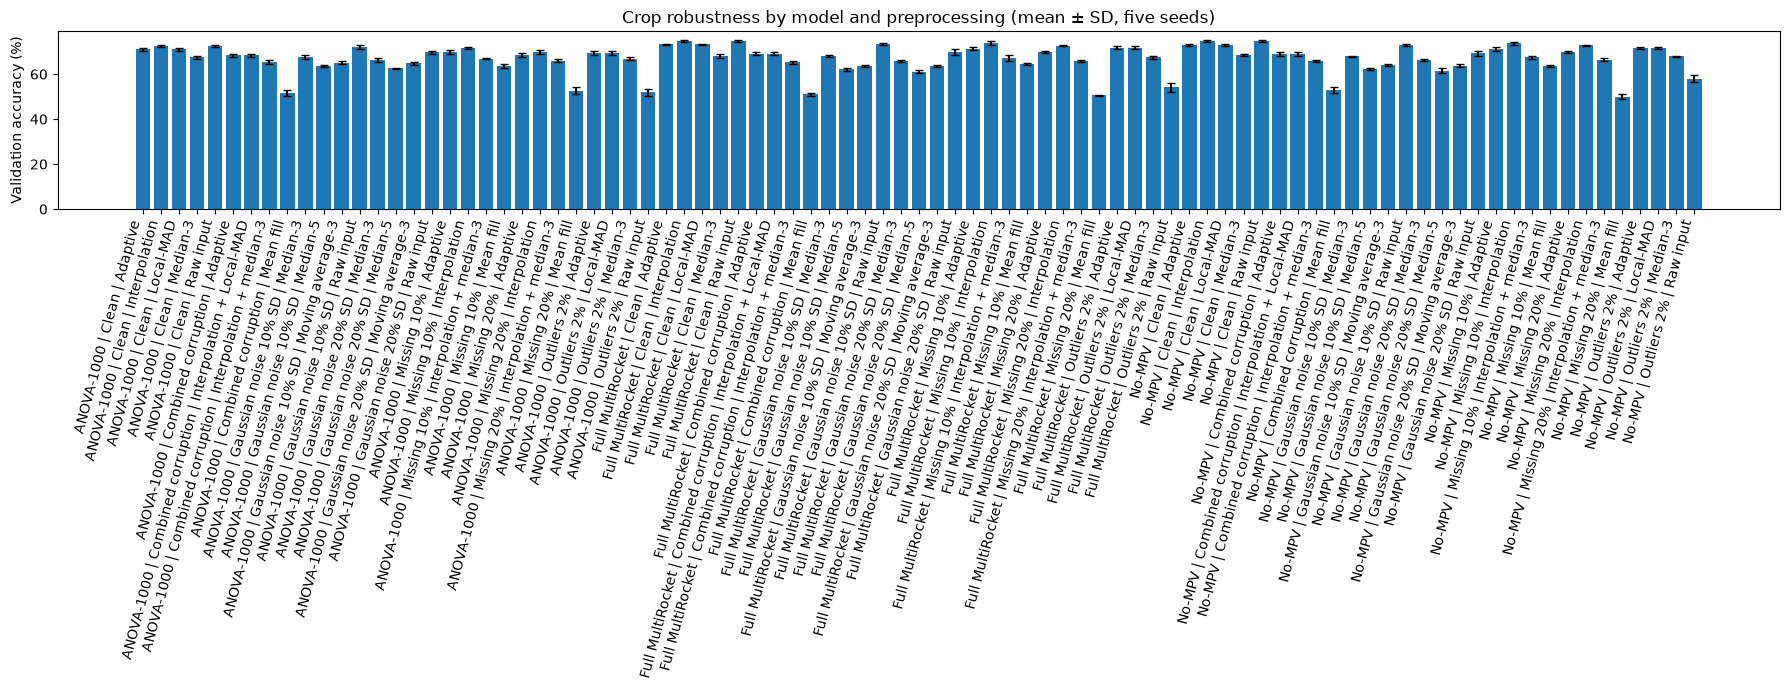

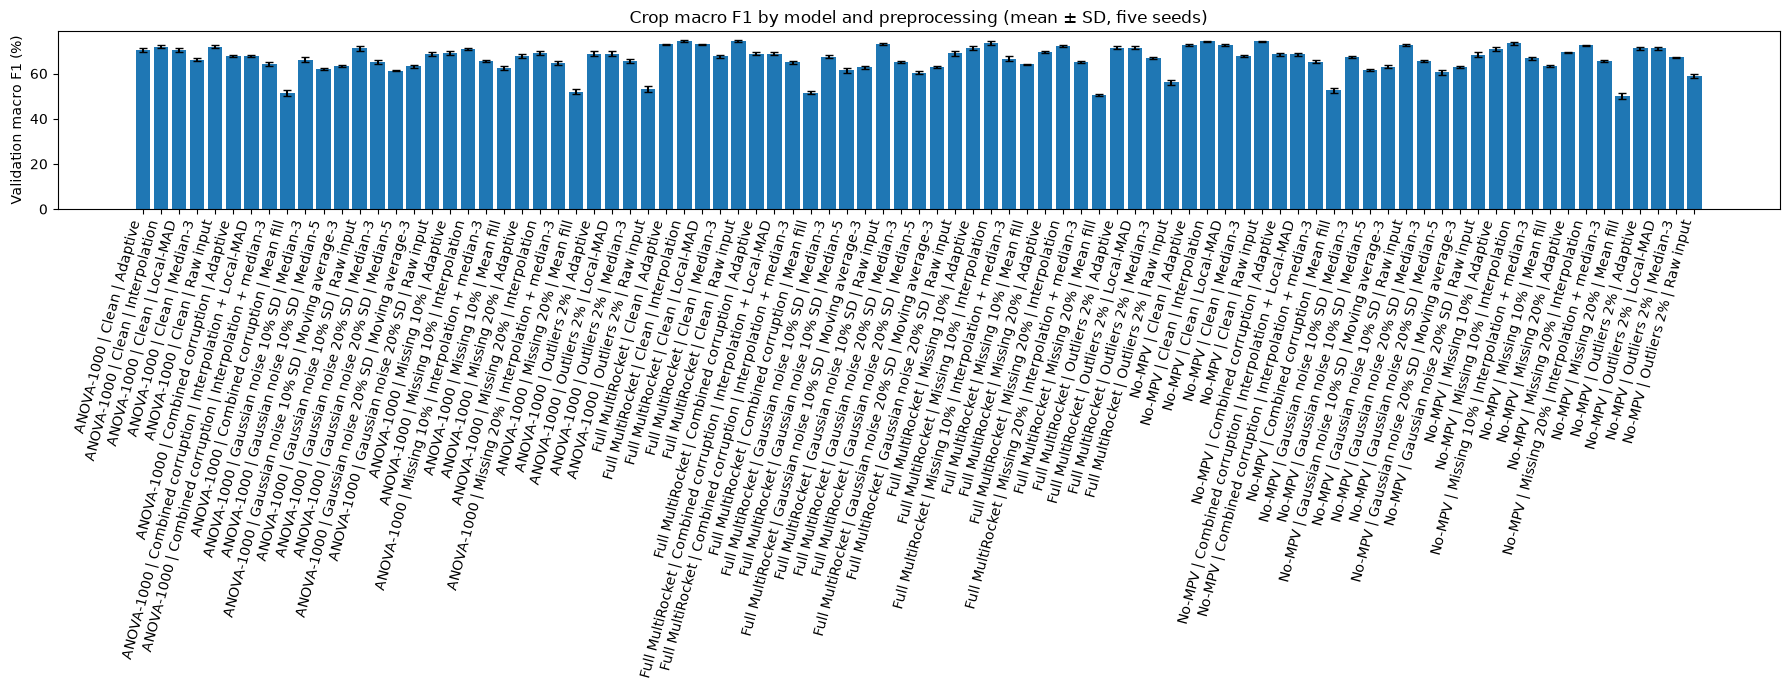

In [24]:
backup_dir = Path("Experiment_D_Results")
backup_dir.mkdir(parents=True, exist_ok=True)

plot_df = robustness_summary_df.copy()
plot_df["Condition"] = (
    plot_df["Model"] + " | " + plot_df["Corruption"] + " | " + plot_df["Preprocessing"]
)

plt.figure(figsize=(18, 7))
plt.bar(plot_df["Condition"], plot_df["Accuracy mean (%)"],
        yerr=plot_df["Accuracy std (%)"], capsize=3)
plt.ylabel("Validation accuracy (%)")
plt.title("Crop robustness by model and preprocessing (mean ± SD, five seeds)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.savefig(backup_dir / "Experiment_D_Accuracy.png", dpi=300, bbox_inches="tight")  # save BEFORE show
plt.show()

plt.figure(figsize=(18, 7))
plt.bar(plot_df["Condition"], plot_df["Macro F1 mean (%)"],
        yerr=plot_df["Macro F1 std (%)"], capsize=3)
plt.ylabel("Validation macro F1 (%)")
plt.title("Crop macro F1 by model and preprocessing (mean ± SD, five seeds)")
plt.xticks(rotation=75, ha="right")
plt.tight_layout()
plt.savefig(backup_dir / "Experiment_D_Macro_F1.png", dpi=300, bbox_inches="tight")  # save BEFORE show
plt.show()

### 8.1 — Results and Discussion

The robustness experiments showed that the effect of preprocessing depended on the type of corruption and the model configuration.

One noticeable result was the effect of outliers on the no-MPV model. With 2% outliers, the model achieved 57.93% accuracy using the raw corrupted data. Applying Local-MAD or adaptive preprocessing increased accuracy to 71.49%, an improvement of approximately 13.56 percentage points.

This suggests that identifying and correcting extreme values can help recover classification performance under this particular corruption condition.

However, preprocessing was not always beneficial. For example, applying a median filter to clean data reduced ANOVA-1000 accuracy to 67.49%, compared with 72.54% using interpolation. This suggests that some preprocessing methods may remove useful information rather than simply correcting corrupted values.

Another finding was that the adaptive pipeline modified 7,275 values in the clean validation data, while Local-MAD flagged approximately 10.98% of clean observations. This raised a concern about whether the preprocessing was unnecessarily altering genuine patterns in the time series.

These results suggest that preprocessing should not be applied automatically without considering the type of corruption. A method that works well for outliers may not be suitable for clean data or other corruption conditions.

## 8.2 Final held-out test evaluation — selected robustness strategies

Preprocessing strategies are selected using validation mean accuracy only, separately for each corruption condition and model configuration. The choices are frozen before the test set is corrupted or scored. A single deterministic corruption realization is then generated for the held-out test set. The full-training models are evaluated on these test inputs; test results are not used to retune Local-MAD or change any selected strategy.

The test set is evaluated once per model and corruption condition. Report these results as the final held-out robustness estimates, not as another tuning round.


In [25]:
# Freeze validation-selected strategy for each model/corruption pair.
chosen_strategy_rows = []
for (model_name, corruption_name), group in robustness_summary_df.groupby(["Model", "Corruption"]):
    best = group.sort_values(
        ["Accuracy mean (%)", "Preprocessing"],
        ascending=[False, True]
    ).iloc[0]
    chosen_strategy_rows.append({
        "Model": model_name, "Corruption": corruption_name,
        "Selected preprocessing": best["Preprocessing"],
        "Validation accuracy mean (%)": best["Accuracy mean (%)"],
        "Validation accuracy std (%)": best["Accuracy std (%)"]
    })
chosen_strategies_df = pd.DataFrame(chosen_strategy_rows)
display(chosen_strategies_df.round(4))
chosen_strategies_df.to_csv(RESULTS_DIR / "06b_validation_selected_strategies.csv", index=False)

# Fit full-training ANOVA-1000 and no-MPV models using all training labels.
full_anova_selector = SelectKBest(
    f_classif, k=min(1000, X_train_full_features.shape[1])
).fit(X_train_full_features, y_train)
full_anova_model = ridge_classifier().fit(
    full_anova_selector.transform(X_train_full_features), y_train
)

X_train_contig = np.ascontiguousarray(X_train, dtype=np.float64)
D_train_contig = np.ascontiguousarray(np.diff(X_train_contig, axis=1))
F_train_no_mpv = transform_without_mpv(
    X_train_contig, D_train_contig,
    baseline_base_params, baseline_diff_params, 3
)
F_train_no_mpv = np.nan_to_num(F_train_no_mpv, nan=0.0, posinf=0.0, neginf=0.0)
full_no_mpv_model = ridge_classifier().fit(F_train_no_mpv, y_train)

# Final held-out test: 3 corruption seeds + a "no repair" baseline for every condition.
# Strategies are the ones frozen on validation (chosen_strategies_df). Nothing is re-tuned here.
TEST_CORRUPTION_SEEDS = [2026, 2027, 2028]
MODEL_NAMES = ["Full MultiRocket", "ANOVA-1000", "No-MPV"]
BASELINE_STRATEGY = {
    "Clean": "Raw input",
    "Gaussian noise 10% SD": "Raw input",
    "Gaussian noise 20% SD": "Raw input",
    "Missing 10%": "Mean fill",
    "Missing 20%": "Mean fill",
    "Outliers 2%": "Raw input",
    "Combined corruption": "Mean fill",
}

def predict_test(model_name, F_full, F_no_mpv):
    if model_name == "Full MultiRocket":
        return baseline_model.predict(F_full)
    if model_name == "ANOVA-1000":
        return full_anova_model.predict(full_anova_selector.transform(F_full))
    return full_no_mpv_model.predict(F_no_mpv)

test_rows = []
for corruption_seed in TEST_CORRUPTION_SEEDS:
    cases = make_corruption_cases(X_test, corruption_seed)
    for corruption_name, X_corrupted in cases.items():
        needed = {}   # strategy -> list of (model, role)
        for model_name in MODEL_NAMES:
            chosen = chosen_strategies_df[
                (chosen_strategies_df["Model"] == model_name)
                & (chosen_strategies_df["Corruption"] == corruption_name)
            ].iloc[0]["Selected preprocessing"]
            needed.setdefault(chosen, []).append((model_name, "Selected"))
            needed.setdefault(BASELINE_STRATEGY[corruption_name], []).append((model_name, "Baseline"))

        for strategy, users in needed.items():
            Xp = apply_preprocessing(X_corrupted, strategy, BEST_MAD_WINDOW, BEST_MAD_THRESHOLD)
            if not np.isfinite(Xp).all():
                raise ValueError(f"{strategy} left non-finite values in {corruption_name}.")
            Xp = np.ascontiguousarray(Xp, dtype=np.float64)
            Dp = np.ascontiguousarray(np.diff(Xp, axis=1))
            F_full = np.nan_to_num(transform(Xp, Dp, baseline_base_params, baseline_diff_params, 4),
                                   nan=0.0, posinf=0.0, neginf=0.0)
            F_no = np.nan_to_num(transform_without_mpv(Xp, Dp, baseline_base_params, baseline_diff_params, 3),
                                 nan=0.0, posinf=0.0, neginf=0.0)
            for model_name, role in users:
                pred = predict_test(model_name, F_full, F_no)
                test_rows.append({
                    "Corruption seed": corruption_seed, "Model": model_name,
                    "Corruption": corruption_name, "Role": role, "Strategy": strategy,
                    "Accuracy (%)": accuracy_score(y_test, pred) * 100,
                    "Macro F1 (%)": f1_score(y_test, pred, average="macro", zero_division=0) * 100,
                })
            del F_full, F_no
            gc.collect()
    print("finished test corruption seed", corruption_seed)

final_test_by_seed_df = pd.DataFrame(test_rows)
keys = ["Model", "Corruption"]
sel = final_test_by_seed_df[final_test_by_seed_df["Role"] == "Selected"]
base = final_test_by_seed_df[final_test_by_seed_df["Role"] == "Baseline"]
sel_summary = sel.groupby(keys).agg(**{
    "Selected preprocessing": ("Strategy", "first"),
    "Test accuracy mean (%)": ("Accuracy (%)", "mean"),
    "Test accuracy SD (%)": ("Accuracy (%)", "std"),
    "Test macro F1 mean (%)": ("Macro F1 (%)", "mean"),
}).reset_index()
base_summary = base.groupby(keys).agg(**{
    "Baseline preprocessing": ("Strategy", "first"),
    "Baseline accuracy mean (%)": ("Accuracy (%)", "mean"),
}).reset_index()
final_robustness_test_df = sel_summary.merge(base_summary, on=keys)
final_robustness_test_df["Gain from selected preprocessing (pp)"] = (
    final_robustness_test_df["Test accuracy mean (%)"] - final_robustness_test_df["Baseline accuracy mean (%)"]
)
final_robustness_test_df["Test samples"] = len(y_test)
display(final_robustness_test_df.round(4))
final_test_by_seed_df.to_csv(RESULTS_DIR / "06c_crop_robustness_final_test_by_seed.csv", index=False)
final_robustness_test_df.to_csv(RESULTS_DIR / "06c_crop_robustness_final_test_once.csv", index=False)
print("Final robustness test saved. No test result was used for selection.")

,Model,Corruption,Selected preprocessing,Validation accuracy mean (%),Validation accuracy std (%)
0,ANOVA-1000,Clean,Interpolation,72.5417,0.5437
1,ANOVA-1000,Combined corruption,Adaptive,68.3194,0.4993
2,ANOVA-1000,Gaussian noise 10% SD,Raw input,71.9722,0.9605
3,ANOVA-1000,Gaussian noise 20% SD,Raw input,69.6250,0.8356
4,ANOVA-1000,Missing 10%,Interpolation,71.6250,0.4241
5,ANOVA-1000,Missing 20%,Interpolation,69.7917,0.8477
6,ANOVA-1000,Outliers 2%,Adaptive,69.4583,0.8454
7,Full MultiRocket,Clean,Interpolation,74.8194,0.4270
8,Full MultiRocket,Combined corruption,Adaptive,69.0972,0.7133
9,Full MultiRocket,Gaussian noise 10% SD,Raw input,73.4306,0.4751


finished test corruption seed 2026
finished test corruption seed 2027
finished test corruption seed 2028


,Model,Corruption,Selected preprocessing,Test accuracy mean (%),Test accuracy SD (%),Test macro F1 mean (%),Baseline preprocessing,Baseline accuracy mean (%),Gain from selected preprocessing (pp),Test samples
0,ANOVA-1000,Clean,Interpolation,72.1845,0.0000,71.4283,Raw input,72.1845,0.0000,16800
1,ANOVA-1000,Combined corruption,Adaptive,67.7401,0.1585,67.0849,Mean fill,50.6111,17.1290,16800
2,ANOVA-1000,Gaussian noise 10% SD,Raw input,71.2718,0.1611,70.5002,Raw input,71.2718,0.0000,16800
3,ANOVA-1000,Gaussian noise 20% SD,Raw input,68.6171,0.1790,67.6580,Raw input,68.6171,0.0000,16800
4,ANOVA-1000,Missing 10%,Interpolation,71.4464,0.1267,70.6816,Mean fill,63.3234,8.1230,16800
5,ANOVA-1000,Missing 20%,Interpolation,69.8571,0.1935,69.0679,Mean fill,51.9365,17.9206,16800
6,ANOVA-1000,Outliers 2%,Adaptive,68.9425,0.1829,68.2904,Raw input,49.2063,19.7361,16800
7,Full MultiRocket,Clean,Interpolation,75.8810,0.0000,75.4741,Raw input,75.8810,0.0000,16800
8,Full MultiRocket,Combined corruption,Adaptive,69.0972,0.1283,68.8564,Mean fill,50.4722,18.6250,16800
9,Full MultiRocket,Gaussian noise 10% SD,Raw input,73.8175,0.2240,73.4174,Raw input,73.8175,0.0000,16800


Final robustness test saved. No test result was used for selection.


In [26]:
#saving results for experiment D
from pathlib import Path
import shutil

# Create a separate backup folder for Experiment D
backup_dir = Path("Experiment_D_Results")
backup_dir.mkdir(parents=True, exist_ok=True)

files = [
    "06_local_mad_validation_grid.csv",
    "06_crop_robustness_validation_by_seed.csv",
    "06_crop_robustness_validation_summary.csv",
    "06b_validation_selected_strategies.csv",
    "06c_crop_robustness_final_test_once.csv"
]

for filename in files:
    source = RESULTS_DIR / filename

    if source.exists():
        shutil.copy2(source, backup_dir / filename)
        print(f"Saved: {filename}")
    else:
        print(f"Not found: {filename}")

print("\nBackup folder:", backup_dir.resolve())

# Create a ZIP file that you can download or share
# zip_path = shutil.make_archive(
#     "Experiment_D_Results_Backup",
#     "zip",
#     backup_dir
# )

# print("ZIP backup:", zip_path)


Saved: 06_local_mad_validation_grid.csv
Saved: 06_crop_robustness_validation_by_seed.csv
Saved: 06_crop_robustness_validation_summary.csv
Saved: 06b_validation_selected_strategies.csv
Saved: 06c_crop_robustness_final_test_once.csv

Backup folder: C:\Users\Tavishi\Downloads\MultiRocket\Experiment_D_Results


### Final test — reporting rule

The test table reports the validation-selected preprocessing strategy and its held-out test accuracy/macro F1. Do not reselect strategies after viewing these test values. The test corruption seed is fixed in the code for reproducibility.


### 8.2 — Final Test Results and Reflection

**Results**

After selecting the preprocessing methods using validation data, I tested the three MultiRocket configurations on the held-out test set.

Full MultiRocket performed best on clean data, achieving 75.88% accuracy, followed by No-MPV at 75.28% and ANOVA-1000 at 72.18%.

Accuracy decreased when corruption was introduced. For Full MultiRocket, combined corruption produced the lowest mean held-out test accuracy of 69.10%, while 20% Gaussian noise produced 69.27%. Missing values had a smaller effect, with the model achieving 72.30% accuracy when 20% of the values were missing and interpolation was applied.

No-MPV performed similarly to the full model across most tested corruption conditions. Under combined corruption, Full MultiRocket achieved a mean held-out test accuracy of 69.10%, while No-MPV achieved 69.03%. These values were averaged across three fixed corruption seeds, and the small difference does not establish equivalent robustness.

ANOVA-1000 had lower accuracy than the other two configurations across all the tested conditions.

**Comparison and Reflection**

One thing that I found interesting was that the two approaches to reducing features behaved differently.

Removing MPV reduced the feature count by 25%, but the model still performed close to Full MultiRocket, even when the data was corrupted. ANOVA-1000, on the other hand, showed consistently lower accuracy.

This made me realise that how features are reduced matters, not just how many features are removed.

Another thing I noticed was that preprocessing did not always help. The validation results selected raw input for Gaussian noise, interpolation for missing values, and adaptive preprocessing for outliers and combined corruption.

I initially expected preprocessing to improve performance under most corruption conditions, but the results suggested that applying it unnecessarily could also affect useful patterns in the data.

One limitation I noticed was that the adaptive preprocessing method changed some values even in the clean validation data. This suggests that it may sometimes treat genuine variations as outliers.

**Conclusion**

The results suggest that No-MPV can retain similar classification performance to Full MultiRocket under the corruption conditions tested, although this does not mean it will behave the same way on every dataset.

Stronger Gaussian noise had the greatest effect on accuracy, while missing values caused a smaller decrease when interpolation was used.

The main thing I learned from this experiment was that reducing features does not necessarily make a model less robust. However, the method used to reduce them and the preprocessing applied both matter.

Further testing with different datasets and corruption levels would help determine whether these findings hold more generally.

## 9. Cross-dataset sanity checks: Coffee and ECG200
*Implementation and experimental evaluation: Tavishi*

Run if these datasets are available. These are external-dataset sanity checks, not substitutes for the main Crop validation/test protocol. The notebook reports the exact train/test sample counts and Wilson 95% confidence intervals for accuracy.

**Coffee limitation:** its small test set (the supplied dataset version has 28 test series) makes accuracy estimates coarse: a single additional correct or incorrect prediction changes accuracy by about 3.6 percentage points. The test sample count cannot be increased by code without obtaining additional independent observations. Treat Coffee results as descriptive only and avoid strong generalisation claims.

**Research Question:** Does removing MPV have a similar effect on classification accuracy when MultiRocket is tested on datasets other than Crop?

In [27]:
# Required setup for Coffee and ECG200 experiments

FULL_KERNELS = kernels_for_budget(REQUESTED_FULL_BUDGET)

from multirocket.multirocket_without_mpv import (
    transform as transform_without_mpv
)

print("Cross-dataset setup ready!")
print("FULL_KERNELS:", FULL_KERNELS)
print("RUN_CROSS_DATASETS:", RUN_CROSS_DATASETS)


Cross-dataset setup ready!
FULL_KERNELS: 625
RUN_CROSS_DATASETS: True


In [28]:
def wilson_interval(successes, n, z=1.96):
    """95% Wilson score interval for a binomial accuracy estimate."""
    if n <= 0:
        return (np.nan, np.nan)
    p = successes / n
    denom = 1 + z**2 / n
    centre = (p + z**2 / (2 * n)) / denom
    half_width = z * np.sqrt((p * (1 - p) / n) + z**2 / (4 * n**2)) / denom
    return max(0.0, centre - half_width), min(1.0, centre + half_width)

cross_dataset_rows = []
if RUN_CROSS_DATASETS:
    for dataset_name in ["Coffee", "ECG200"]:
        try:
            Xtr_ds, ytr_ds, Xte_ds, yte_ds = load_ucr_dataset(dataset_name)
        except FileNotFoundError as e:
            print("Skipping", dataset_name, e)
            continue

        Dtr_ds = np.ascontiguousarray(np.diff(Xtr_ds, axis=1))
        Dte_ds = np.ascontiguousarray(np.diff(Xte_ds, axis=1))
        set_numba_seed(RANDOM_STATE)
        bp_ds = fit(np.ascontiguousarray(Xtr_ds), num_features=FULL_KERNELS)
        dp_ds = fit(Dtr_ds, num_features=FULL_KERNELS)

        Ftr_all = transform(Xtr_ds, Dtr_ds, bp_ds, dp_ds, 4)
        Fte_all = transform(Xte_ds, Dte_ds, bp_ds, dp_ds, 4)
        Ftr_no = transform_without_mpv(Xtr_ds, Dtr_ds, bp_ds, dp_ds, 3)
        Fte_no = transform_without_mpv(Xte_ds, Dte_ds, bp_ds, dp_ds, 3)

        for model_name, A, B in [
            ("Original MultiRocket", Ftr_all, Fte_all),
            ("Direct no-MPV", Ftr_no, Fte_no)
        ]:
            ev = score_classifier(ridge_classifier(), A, ytr_ds, B, yte_ds)
            correct = int(np.sum(ev["predictions"] == yte_ds))
            ci_low, ci_high = wilson_interval(correct, len(yte_ds))
            cross_dataset_rows.append({
                "Dataset": dataset_name, "Model": model_name,
                "Train samples": len(ytr_ds), "Test samples": len(yte_ds),
                "Features": A.shape[1], "Correct predictions": correct,
                "Accuracy (%)": ev["accuracy_pct"],
                "Accuracy 95% CI lower (%)": ci_low * 100,
                "Accuracy 95% CI upper (%)": ci_high * 100,
                "Macro F1 (%)": ev["macro_f1_pct"],
                "Classifier fit (s)": ev["classifier_fit_s"],
                "Prediction (s)": ev["prediction_s"]
            })

        if dataset_name == "Coffee":
            print(
                f"Coffee test set contains {len(yte_ds)} cases. "
                "Accuracy estimates are coarse and confidence intervals are wide; "
                "treat this as a small-sample sanity check, not strong evidence."
            )
        del Ftr_all, Fte_all, Ftr_no, Fte_no
        gc.collect()

cross_dataset_df = pd.DataFrame(cross_dataset_rows)
display(cross_dataset_df.round(4))
cross_dataset_df.to_csv(RESULTS_DIR / "07_cross_dataset_sanity_checks_with_ci.csv", index=False)


Coffee test set contains 28 cases. Accuracy estimates are coarse and confidence intervals are wide; treat this as a small-sample sanity check, not strong evidence.


,Dataset,Model,Train samples,Test samples,Features,Correct predictions,Accuracy (%),Accuracy 95% CI lower (%),Accuracy 95% CI upper (%),Macro F1 (%),Classifier fit (s),Prediction (s)
0,Coffee,Original MultiRocket,28,28,4704,28,100.0,87.9353,100.0000,100.0000,0.0197,0.0022
1,Coffee,Direct no-MPV,28,28,3528,28,100.0,87.9353,100.0000,100.0000,0.0107,0.0012
2,ECG200,Original MultiRocket,100,100,4704,90,90.0,82.5633,94.4771,89.1493,0.0293,0.0074
3,ECG200,Direct no-MPV,100,100,3528,91,91.0,83.7736,95.1928,90.1736,0.0192,0.0050


### 9.1 — Cross-dataset Results and Reflection

**Results**

To see whether the results I obtained on Crop would also hold for other datasets, I tested the original MultiRocket and No-MPV implementations on Coffee and ECG200.

On Coffee, both models achieved 100% accuracy, correctly classifying all 28 test samples. The original MultiRocket used 4,704 features, while No-MPV used 3,528 features.

On ECG200, the original model achieved 90% accuracy, while No-MPV achieved 91%. Although the difference was small, No-MPV correctly classified one additional sample while using 25% fewer features.

**Comparison and Reflection**

I wanted to check whether removing MPV would affect classification accuracy differently on other datasets.

What stood out to me was that No-MPV performed just as well as the original model on Coffee and slightly better on ECG200. This was encouraging because, in my earlier Crop experiment, removing MPV had caused a small decrease in accuracy.

However, the Coffee dataset has only 28 test samples, so the 100% accuracy needs to be interpreted carefully. Even one incorrect prediction would change the accuracy by around 3.57 percentage points.

Similarly, the 1% improvement on ECG200 represents just one additional correct prediction. While this is a positive result, it is too small to say that removing MPV actually improves classification accuracy.

These results suggest that MPV may not always be necessary to maintain classification performance, but more testing would be needed to confirm this.

**Conclusion**

Overall, these experiments gave me more confidence that removing MPV can reduce the feature count without necessarily causing a noticeable drop in accuracy.

On both Coffee and ECG200, No-MPV achieved comparable results to the original MultiRocket despite generating 25% fewer features.

However, both test sets are relatively small, so I would not assume the same results would hold for larger or more complex datasets.

I think the next step would be to test the modified implementation on more datasets with different time-series characteristics and larger test sets. This would help establish whether the accuracy results are consistent beyond the three datasets examined.

## 10. Overall Experimental Results and Comparisons
*Implementation and experimental evaluation: Tavishi*

This section brings together the main results from the baseline and improvement experiments. The tables and plots make it easier to compare classification accuracy, feature count and computational cost across the different approaches.


In [29]:

# Section 10 — Load saved experiment results
# Does NOT rerun any models or experiments.

from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

results_dir = Path(
    RESULTS_DIR if "RESULTS_DIR" in globals()
    else "results/improvements_new"
)

tables = {
    "baseline_df": "01_crop_baseline.csv",
    "budget_seed_df": "02_feature_budget_validation_by_seed.csv",
    "budget_validation_df": "02_feature_budget_validation_summary.csv",
    "feature_budget_final_df": "03_feature_budget_final_test.csv",

    "selection_comparison_df": "04_selection_method_validation_summary.csv",
    "selection_seed_df": "04_selection_method_by_seed.csv",
    "selection_pairwise_df": "04_selection_pairwise_mcnemar_by_seed.csv",

    "pooling_ablation_df": "04b_pooling_operator_validation_summary.csv",
    "mpv_df": "05_direct_mpv_validation_5seeds.csv",
    "mpv_summary_df": "05_direct_mpv_validation_summary.csv",

    "mad_tuning_df": "06_local_mad_validation_grid.csv",
    "robustness_summary_df": "06_crop_robustness_validation_summary.csv",
    "chosen_strategies_df": "06b_validation_selected_strategies.csv",
    "final_robustness_test_df": "06c_crop_robustness_final_test_once.csv",

    "cross_dataset_df": "07_cross_dataset_sanity_checks_with_ci.csv"
}

missing = []

for variable, filename in tables.items():

    # Preserve data already calculated in this session.
    if variable in globals() and isinstance(
        globals()[variable], pd.DataFrame
    ):
        print(f"Already available: {variable}")
        continue

    path = results_dir / filename

    if not path.exists():
        missing.append(str(path))
        continue

    if variable == "mpv_summary_df":
        globals()[variable] = pd.read_csv(
            path, index_col=0
        )
    else:
        globals()[variable] = pd.read_csv(path)

    print(f"Loaded: {variable}")

if missing:
    print("\nMissing result files:")
    for path in missing:
        print(" -", path)

    raise FileNotFoundError(
        "Some saved results are unavailable. "
        "Do not rerun all experiments; locate the missing CSVs."
    )

# Restore parameters used by Section 11 if needed.
if "BEST_MAD_WINDOW" not in globals():
    BEST_MAD_WINDOW = int(mad_tuning_df.iloc[0]["Window"])

if "BEST_MAD_THRESHOLD" not in globals():
    BEST_MAD_THRESHOLD = float(
        mad_tuning_df.iloc[0]["Threshold"]
    )

if "BEST_MAD_CLEAN_FLAG_RATE" not in globals():
    BEST_MAD_CLEAN_FLAG_RATE = float(
        mad_tuning_df.iloc[0][
            "Clean false-positive flag rate (%)"
        ]
    )

print("\nAll Section 10 result tables are ready!")


Already available: baseline_df
Already available: budget_seed_df
Already available: budget_validation_df
Already available: feature_budget_final_df
Already available: selection_comparison_df
Already available: selection_seed_df
Already available: selection_pairwise_df
Already available: pooling_ablation_df
Already available: mpv_df
Already available: mpv_summary_df
Already available: mad_tuning_df
Already available: robustness_summary_df
Already available: chosen_strategies_df
Already available: final_robustness_test_df
Already available: cross_dataset_df

All Section 10 result tables are ready!


CROP BASELINE — HELD-OUT TEST


,Dataset,Model,Requested features,Actual features,Accuracy (%),Macro F1 (%),Parameter fit (s),Train transform (s),Test transform (s),Classifier fit (s),Prediction (s),Total measured (s)
0,Crop,Original MultiRocket,5000,4704,75.881,75.4741,0.007,0.2698,0.7622,89.8362,2.1907,93.066


DIRECT FEATURE BUDGET — VALIDATION BY SEED


,Seed,Budget label,Requested features,Kernels per transform,Actual features,Validation accuracy (%),Validation macro F1 (%),Parameter fit (s),Train transform (s),Validation transform (s),Classifier fit (s),Prediction (s),Total measured (s)
0,0,Direct-1000,1000,125,672,67.7778,66.8222,0.0054,0.0605,0.0130,3.5045,0.0167,3.6001
1,0,Direct-1250,1250,156,672,67.7778,66.8222,0.0023,0.1976,0.0483,4.3080,0.0135,4.5697
2,0,Direct-2500,2500,312,2016,73.4722,72.8001,0.0035,0.1063,0.0432,11.4050,0.0434,11.6014
3,0,Direct-5000,5000,625,4704,74.8611,74.5521,0.0086,0.3047,0.0836,65.0255,0.1094,65.5317
4,0,Direct-50000,50000,6250,49728,76.1111,75.9299,0.0701,2.8877,1.1094,93.2675,1.8154,99.1502
5,1,Direct-1000,1000,125,672,69.0972,68.2552,0.0036,0.0534,0.0171,1.6044,0.0149,1.6934
6,1,Direct-1250,1250,156,672,69.0972,68.2552,0.0029,0.0410,0.0089,1.6581,0.0191,1.7300
7,1,Direct-2500,2500,312,2016,73.8889,73.1431,0.0068,0.0937,0.0308,9.2801,0.0324,9.4438
8,1,Direct-5000,5000,625,4704,74.0972,73.6700,0.0145,0.2316,0.0689,71.6539,0.1062,72.0751
9,1,Direct-50000,50000,6250,49728,77.0833,76.8848,0.0483,2.8524,0.8720,80.5169,1.2439,85.5335


DIRECT FEATURE BUDGET — FIVE-SEED SUMMARY


,Budget label,Requested features,Kernels per transform,Actual features mean,Actual features std,Validation accuracy mean (%),Validation accuracy std (%),Validation macro F1 mean (%),Validation macro F1 std (%),Total measured mean (s),Total measured std (s)
0,Direct-1000,1000,125,672.0,0.0,68.3611,0.6635,67.4580,0.7356,2.9318,0.9911
1,Direct-1250,1250,156,672.0,0.0,68.3611,0.6635,67.4580,0.7356,2.6116,1.2667
2,Direct-2500,2500,312,2016.0,0.0,73.7778,0.3205,73.1726,0.4051,11.7276,2.5889
3,Direct-5000,5000,625,4704.0,0.0,74.8194,0.4270,74.4538,0.4818,70.0993,5.4965
4,Direct-50000,50000,6250,49728.0,0.0,76.5694,0.5590,76.4129,0.5453,96.1587,7.2280


... (17 outputs left out)

,Model,Corruption,Selected preprocessing,Validation accuracy mean (%),Validation accuracy std (%)
0,ANOVA-1000,Clean,Interpolation,72.5417,0.5437
1,ANOVA-1000,Combined corruption,Adaptive,68.3194,0.4993
2,ANOVA-1000,Gaussian noise 10% SD,Raw input,71.9722,0.9605
3,ANOVA-1000,Gaussian noise 20% SD,Raw input,69.6250,0.8356
4,ANOVA-1000,Missing 10%,Interpolation,71.6250,0.4241
5,ANOVA-1000,Missing 20%,Interpolation,69.7917,0.8477
6,ANOVA-1000,Outliers 2%,Adaptive,69.4583,0.8454
7,Full MultiRocket,Clean,Interpolation,74.8194,0.4270
8,Full MultiRocket,Combined corruption,Adaptive,69.0972,0.7133
9,Full MultiRocket,Gaussian noise 10% SD,Raw input,73.4306,0.4751


,Model,Corruption,Selected preprocessing,Test accuracy mean (%),Test accuracy SD (%),Test macro F1 mean (%),Baseline preprocessing,Baseline accuracy mean (%),Gain from selected preprocessing (pp),Test samples
0,ANOVA-1000,Clean,Interpolation,72.1845,0.0000,71.4283,Raw input,72.1845,0.0000,16800
1,ANOVA-1000,Combined corruption,Adaptive,67.7401,0.1585,67.0849,Mean fill,50.6111,17.1290,16800
2,ANOVA-1000,Gaussian noise 10% SD,Raw input,71.2718,0.1611,70.5002,Raw input,71.2718,0.0000,16800
3,ANOVA-1000,Gaussian noise 20% SD,Raw input,68.6171,0.1790,67.6580,Raw input,68.6171,0.0000,16800
4,ANOVA-1000,Missing 10%,Interpolation,71.4464,0.1267,70.6816,Mean fill,63.3234,8.1230,16800
5,ANOVA-1000,Missing 20%,Interpolation,69.8571,0.1935,69.0679,Mean fill,51.9365,17.9206,16800
6,ANOVA-1000,Outliers 2%,Adaptive,68.9425,0.1829,68.2904,Raw input,49.2063,19.7361,16800
7,Full MultiRocket,Clean,Interpolation,75.8810,0.0000,75.4741,Raw input,75.8810,0.0000,16800
8,Full MultiRocket,Combined corruption,Adaptive,69.0972,0.1283,68.8564,Mean fill,50.4722,18.6250,16800
9,Full MultiRocket,Gaussian noise 10% SD,Raw input,73.8175,0.2240,73.4174,Raw input,73.8175,0.0000,16800


CROSS-DATASET SANITY CHECKS WITH 95% ACCURACY INTERVALS


,Dataset,Model,Train samples,Test samples,Features,Correct predictions,Accuracy (%),Accuracy 95% CI lower (%),Accuracy 95% CI upper (%),Macro F1 (%),Classifier fit (s),Prediction (s)
0,Coffee,Original MultiRocket,28,28,4704,28,100.0,87.9353,100.0000,100.0000,0.0197,0.0022
1,Coffee,Direct no-MPV,28,28,3528,28,100.0,87.9353,100.0000,100.0000,0.0107,0.0012
2,ECG200,Original MultiRocket,100,100,4704,90,90.0,82.5633,94.4771,89.1493,0.0293,0.0074
3,ECG200,Direct no-MPV,100,100,3528,91,91.0,83.7736,95.1928,90.1736,0.0192,0.0050


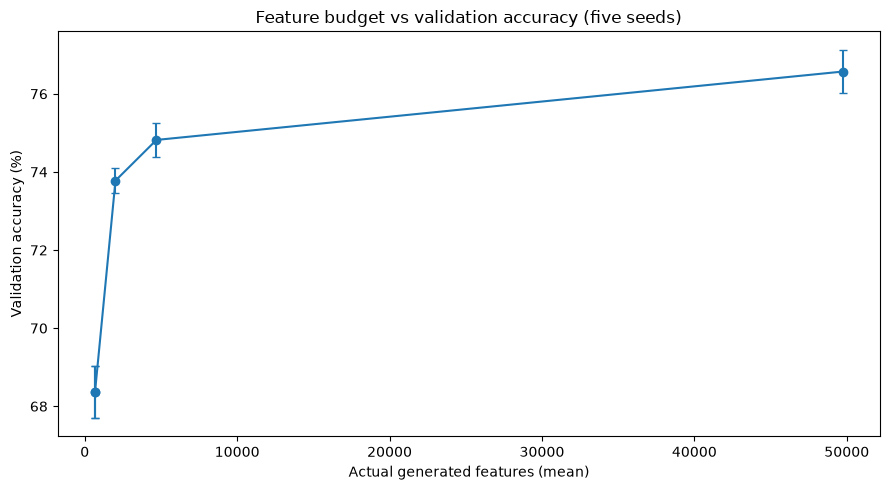

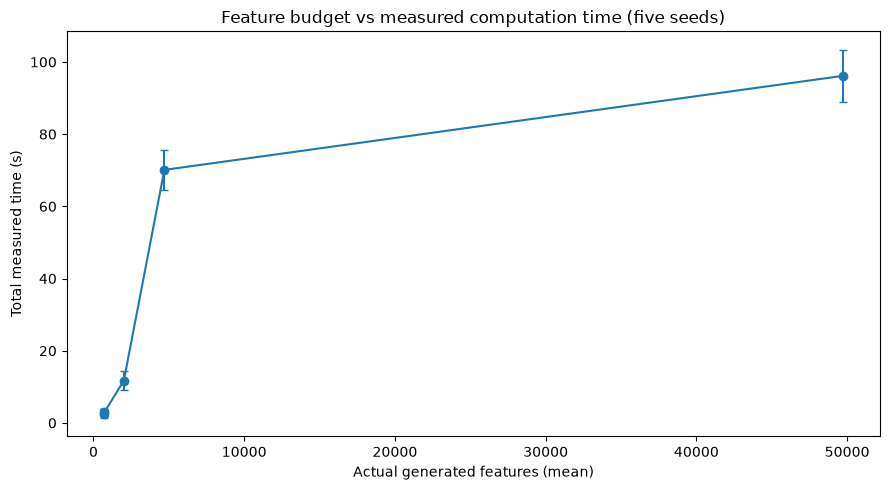

CSV outputs saved to: C:\Users\Tavishi\Downloads\MultiRocket\results\improvements_new


In [30]:
print("CROP BASELINE — HELD-OUT TEST")
display(baseline_df.round(4))

print("DIRECT FEATURE BUDGET — VALIDATION BY SEED")
display(budget_seed_df.round(4))
print("DIRECT FEATURE BUDGET — FIVE-SEED SUMMARY")
display(budget_validation_df.round(4))

print("SELECTED DIRECT FEATURE BUDGET — HELD-OUT TEST")
display(feature_budget_final_df.round(4))

print("FEATURE SELECTION — FIVE-SEED SUMMARY")
display(selection_comparison_df.round(4))
print("FEATURE SELECTION — PER-SEED RESULTS")
display(selection_seed_df.round(4))
display(selection_pairwise_df.round(4))

print("POOLING OPERATOR ABLATION — FIVE-SEED SUMMARY")
display(pooling_ablation_df.round(4))

print("DIRECT MPV REMOVAL — FIVE-SEED VALIDATION")
display(mpv_df.drop(columns=["Original timing repeats (s)", "No-MPV timing repeats (s)"]).round(4))
display(mpv_summary_df.round(4))

print("LOCAL-MAD VALIDATION GRID")
display(mad_tuning_df.round(4))

print("ROBUSTNESS — FIVE-SEED VALIDATION SUMMARY")
display(robustness_summary_df.round(4))

print("VALIDATION-SELECTED STRATEGIES AND FINAL TEST")
display(chosen_strategies_df.round(4))
display(final_robustness_test_df.round(4))

print("CROSS-DATASET SANITY CHECKS WITH 95% ACCURACY INTERVALS")
display(cross_dataset_df.round(4))

plt.figure(figsize=(9, 5))
plt.errorbar(
    budget_validation_df["Actual features mean"],
    budget_validation_df["Validation accuracy mean (%)"],
    yerr=budget_validation_df["Validation accuracy std (%)"],
    marker="o", capsize=3
)
plt.xlabel("Actual generated features (mean)")
plt.ylabel("Validation accuracy (%)")
plt.title("Feature budget vs validation accuracy (five seeds)")
plt.tight_layout()
plt.show()

plt.figure(figsize=(9, 5))
plt.errorbar(
    budget_validation_df["Actual features mean"],
    budget_validation_df["Total measured mean (s)"],
    yerr=budget_validation_df["Total measured std (s)"],
    marker="o", capsize=3
)
plt.xlabel("Actual generated features (mean)")
plt.ylabel("Total measured time (s)")
plt.title("Feature budget vs measured computation time (five seeds)")
plt.tight_layout()
plt.show()

print("CSV outputs saved to:", RESULTS_DIR.resolve())


## 11. Consolidated Experimental Findings
*Implementation and experimental evaluation: Tavishi*

This section brings together the main numerical findings from the experiments. The values are taken directly from the executed results, making it easier to check the comparisons discussed in the individual experiment sections.

The aim is to summarise the main accuracy and efficiency trade-offs rather than repeat the detailed reflections already provided for each experiment.

In [31]:

import pandas as pd

# Check whether cross-dataset results are still available
print("cross_dataset_df:", "cross_dataset_df" in globals())
print("cross_dataset_rows:", "cross_dataset_rows" in globals())

# Restore DataFrame from existing results if possible
if "cross_dataset_df" not in globals():
    if "cross_dataset_rows" in globals() and cross_dataset_rows:
        cross_dataset_df = pd.DataFrame(cross_dataset_rows)
        print("Cross-dataset results restored successfully.")

if "cross_dataset_df" in globals():
    display(cross_dataset_df)
else:
    print("Results are not currently in memory.")
    print("Check the saved cross-dataset CSV.")


cross_dataset_df: True
cross_dataset_rows: True


,Dataset,Model,Train samples,Test samples,Features,Correct predictions,Accuracy (%),Accuracy 95% CI lower (%),Accuracy 95% CI upper (%),Macro F1 (%),Classifier fit (s),Prediction (s)
0,Coffee,Original MultiRocket,28,28,4704,28,100.0,87.935280,100.000000,100.000000,0.019668,0.002193
1,Coffee,Direct no-MPV,28,28,3528,28,100.0,87.935280,100.000000,100.000000,0.010685,0.001228
2,ECG200,Original MultiRocket,100,100,4704,90,90.0,82.563270,94.477146,89.149306,0.029345,0.007356
3,ECG200,Direct no-MPV,100,100,3528,91,91.0,83.773625,95.192800,90.173600,0.019217,0.005042


In [32]:

from pathlib import Path
import pandas as pd

csv_path = RESULTS_DIR / "07_cross_dataset_sanity_checks_with_ci.csv"

if csv_path.exists():
    cross_dataset_df = pd.read_csv(csv_path)
    display(cross_dataset_df)
else:
    print("CSV not found:", csv_path)


,Dataset,Model,Train samples,Test samples,Features,Correct predictions,Accuracy (%),Accuracy 95% CI lower (%),Accuracy 95% CI upper (%),Macro F1 (%),Classifier fit (s),Prediction (s)
0,Coffee,Original MultiRocket,28,28,4704,28,100.0,87.935280,100.000000,100.000000,0.019668,0.002193
1,Coffee,Direct no-MPV,28,28,3528,28,100.0,87.935280,100.000000,100.000000,0.010685,0.001228
2,ECG200,Original MultiRocket,100,100,4704,90,90.0,82.563270,94.477146,89.149306,0.029345,0.007356
3,ECG200,Direct no-MPV,100,100,3528,91,91.0,83.773625,95.192800,90.173600,0.019217,0.005042


In [34]:

import numpy as np
import pandas as pd

print("=" * 88)
print("CONSOLIDATED EXPERIMENTAL FINDINGS — COMPUTED FROM EXECUTED RESULTS")
print("=" * 88)

# Helper: report missing results without hiding the reason.
def report_unavailable(section, exc):
    print(f"{section} unavailable: {type(exc).__name__}: {exc}")


# ============================================================
# EXPERIMENT A — DIRECT FEATURE-BUDGET REDUCTION
# ============================================================
print("\nEXPERIMENT A — DIRECT FEATURE-BUDGET REDUCTION")

try:
    row_1000 = budget_validation_df.loc[
        budget_validation_df["Requested features"] == 1000
    ].iloc[0]

    row_50k = budget_validation_df.loc[
        budget_validation_df["Requested features"] == 50000
    ].iloc[0]

    acc_1000 = float(row_1000["Validation accuracy mean (%)"])
    acc_50k = float(row_50k["Validation accuracy mean (%)"])

    time_1000 = float(row_1000["Total measured mean (s)"])
    time_50k = float(row_50k["Total measured mean (s)"])

    print(
        f"Requested 1,000: {acc_1000:.2f}% accuracy "
        f"(SD {row_1000['Validation accuracy std (%)']:.2f}), "
        f"{time_1000:.2f}s measured time."
    )

    print(
        f"Requested 50,000: {acc_50k:.2f}% accuracy "
        f"(SD {row_50k['Validation accuracy std (%)']:.2f}), "
        f"{time_50k:.2f}s measured time."
    )

    print(
        f"Accuracy difference (1,000 minus 50,000): "
        f"{acc_1000 - acc_50k:+.2f} percentage points."
    )

    if time_50k > 0:
        print(
            f"Measured time change: "
            f"{(time_1000 / time_50k - 1) * 100:+.2f}%."
        )

    print(
        "Note: Requested budgets may produce different actual "
        "feature counts. See Experiment A for realised dimensions."
    )

except (KeyError, IndexError, TypeError, ValueError, NameError) as exc:
    report_unavailable("Experiment A", exc)


# ============================================================
# EXPERIMENT B — FEATURE SELECTION
# ============================================================
print("\nEXPERIMENT B — FEATURE SELECTION")

try:
    df = selection_comparison_df.copy()

    # Display all methods, including any full-feature reference.
    display(
        df.sort_values(
            "Validation accuracy mean (%)",
            ascending=False
        ).round(4)
    )

    # The overall accuracy leader may be the full representation.
    overall_best = df.sort_values(
        "Validation accuracy mean (%)",
        ascending=False
    ).iloc[0]

    print(
        f"Highest accuracy overall: {overall_best['Method']} — "
        f"{overall_best['Validation accuracy mean (%)']:.2f}%."
    )

    # Identify the three actual feature-selection methods.
    # Match their names rather than assuming a particular row order.
    method_names = df["Method"].astype(str).str.lower()

    selection_mask = method_names.str.contains(
        r"anova|mutual information|mutual_info|random",
        regex=True
    )

    selected_methods = df.loc[selection_mask]

    if not selected_methods.empty:
        best_selected = selected_methods.sort_values(
            "Validation accuracy mean (%)",
            ascending=False
        ).iloc[0]

        print(
            f"Best feature-selection method: "
            f"{best_selected['Method']} — "
            f"{best_selected['Validation accuracy mean (%)']:.2f}% "
            f"(SD {best_selected['Validation accuracy std (%)']:.2f})."
        )

        print(
            f"Mean selection time: "
            f"{best_selected['Feature selection time mean (s)']:.4f}s."
        )
    else:
        print(
            "Could not identify the feature-selection methods "
            "from their labels. Check the Method column."
        )

    print(
        "Note: Post-extraction selection does not avoid "
        "generating the original MultiRocket feature pool."
    )

except (KeyError, IndexError, TypeError, ValueError, NameError) as exc:
    report_unavailable("Experiment B", exc)


# ============================================================
# EXPERIMENT C — DIRECT MPV REMOVAL
# ============================================================
print("\nEXPERIMENT C — DIRECT MPV REMOVAL")

try:
    changes = c2_benchmark_summary["Time change (%)"].astype(float)

    mean_change = changes.mean()
    std_change = changes.std(ddof=1)

    print(
        f"Original vs No-MPV extraction-time change: "
        f"{mean_change:+.2f}% ± {std_change:.2f}% SD "
        f"across {len(changes)} seeds."
    )

    if mean_change > 0:
        print("No-MPV was slower on average in this comparison.")
    elif mean_change < 0:
        print("No-MPV was faster on average in this comparison.")
    else:
        print("No average extraction-time difference was observed.")

    if "Accuracy difference (pp)" in mpv_df.columns:
        accuracy_diff = mpv_df[
            "Accuracy difference (pp)"
        ].astype(float)

        print(
            f"Mean validation accuracy difference: "
            f"{accuracy_diff.mean():+.2f} percentage points "
            f"(SD {accuracy_diff.std(ddof=1):.2f})."
        )

    print(
        "Note: These timings come from the enhanced C2 benchmark. "
        "Use the enhanced benchmark separately when discussing "
        "the final runtime findings."
    )

except (KeyError, TypeError, ValueError, NameError) as exc:
    report_unavailable("Experiment C", exc)


# ============================================================
# EXPERIMENT D — ROBUSTNESS AND PREPROCESSING
# ============================================================
print("\nEXPERIMENT D — ROBUSTNESS AND PREPROCESSING")

try:
    for model_name in robustness_summary_df["Model"].unique():

        for corruption_name in [
            "Gaussian noise 10% SD",
            "Gaussian noise 20% SD"
        ]:

            subset = robustness_summary_df[
                (robustness_summary_df["Model"] == model_name) &
                (robustness_summary_df["Corruption"] == corruption_name)
            ]

            raw = subset[
                subset["Preprocessing"] == "Raw input"
            ]

            filtered = subset[
                subset["Preprocessing"] != "Raw input"
            ]

            if raw.empty or filtered.empty:
                print(
                    f"{model_name}, {corruption_name}: "
                    "comparison unavailable."
                )
                continue

            raw_acc = float(
                raw.iloc[0]["Accuracy mean (%)"]
            )

            best_filtered_row = filtered.sort_values(
                "Accuracy mean (%)",
                ascending=False
            ).iloc[0]

            best_filtered_acc = float(
                best_filtered_row["Accuracy mean (%)"]
            )

            best_method = best_filtered_row["Preprocessing"]

            difference = best_filtered_acc - raw_acc

            print(
                f"{model_name} | {corruption_name}\n"
                f"  Raw input: {raw_acc:.2f}%\n"
                f"  Best tested preprocessing: {best_method} "
                f"({best_filtered_acc:.2f}%)\n"
                f"  Difference: {difference:+.2f} percentage points"
            )

            if difference < 0:
                print("  Finding: preprocessing reduced accuracy.")
            elif difference > 0:
                print("  Finding: preprocessing improved accuracy.")
            else:
                print("  Finding: no accuracy difference.")

except (KeyError, TypeError, ValueError, NameError) as exc:
    report_unavailable("Experiment D", exc)


# ============================================================
# LOCAL-MAD AND ADAPTIVE PREPROCESSING
# ============================================================
print("\nLOCAL-MAD AND ADAPTIVE PREPROCESSING")

try:
    print(
        f"Selected Local-MAD parameters: "
        f"window={BEST_MAD_WINDOW}, "
        f"threshold={BEST_MAD_THRESHOLD}."
    )

    print(
        f"Clean validation flag rate: "
        f"{BEST_MAD_CLEAN_FLAG_RATE:.3f}%."
    )

    changed = int(
        np.count_nonzero(
            ~np.isclose(_adaptive_clean, X_val)
        )
    )

    print(
        f"Adaptive preprocessing changed {changed} "
        f"of {X_val.size} clean validation values."
    )

    print(
        "Note: Changes to clean values may indicate that "
        "genuine signal variations are being modified."
    )

except (NameError, TypeError, ValueError) as exc:
    report_unavailable("Local-MAD/adaptive preprocessing", exc)


# ============================================================
# CROSS-DATASET CHECKS — COFFEE AND ECG200
# ============================================================
print("\nCROSS-DATASET CHECKS — COFFEE AND ECG200")

try:
    display(cross_dataset_df.round(4))

    coffee = cross_dataset_df[
        cross_dataset_df["Dataset"] == "Coffee"
    ]

    if not coffee.empty:
        n_coffee = int(coffee.iloc[0]["Test samples"])

        print(
            f"Coffee test set: {n_coffee} samples. "
            f"One prediction changes accuracy by "
            f"{100 / n_coffee:.2f} percentage points."
        )

    print(
        "These are small external-dataset checks, "
        "not evidence of universal generalisation."
    )

except (KeyError, TypeError, ValueError, NameError) as exc:
    report_unavailable("Cross-dataset checks", exc)


# ============================================================
# FINAL INTERPRETATION NOTES
# ============================================================
print("\n" + "=" * 88)
print("INTERPRETATION NOTES")
print("=" * 88)

print(
    "1. Compare accuracy changes with feature-count and "
    "runtime changes, rather than assuming fewer features "
    "always means better efficiency."
)

print(
    "2. Distinguish post-extraction feature selection "
    "from direct changes to feature generation."
)

print(
    "3. Report the enhanced MPV runtime benchmark alongside "
    "the original C2 timing results."
)

print(
    "4. Interpret small accuracy differences alongside "
    "seed-to-seed variation and test-set size."
)

print(
    "5. Discuss preprocessing benefits and failures "
    "separately for each corruption condition."
)

print(
    "6. Use validation results for method selection and "
    "the held-out test results for final evaluation."
)

print("\nConsolidated findings completed.")


CONSOLIDATED EXPERIMENTAL FINDINGS — COMPUTED FROM EXECUTED RESULTS

EXPERIMENT A — DIRECT FEATURE-BUDGET REDUCTION
Requested 1,000: 68.36% accuracy (SD 0.66), 2.93s measured time.
Requested 50,000: 76.57% accuracy (SD 0.56), 96.16s measured time.
Accuracy difference (1,000 minus 50,000): -8.21 percentage points.
Measured time change: -96.95%.
Note: Requested budgets may produce different actual feature counts. See Experiment A for realised dimensions.

EXPERIMENT B — FEATURE SELECTION


,Method,Features,Validation accuracy mean (%),Validation accuracy std (%),Validation macro F1 mean (%),Validation macro F1 std (%),Feature selection time mean (s),Feature selection time std (s),Classifier fit time mean (s),Prediction time mean (s),Parameter fit time mean (s),Train feature transform time mean (s),Validation feature transform time mean (s)
1,All features,4704,74.8194,0.4270,74.4538,0.4818,0.0000,0.0000,65.8073,0.1053,0.0124,0.311,0.0865
2,Mutual Information,1000,72.8611,0.2426,72.2801,0.2797,209.3590,3.3352,2.7998,0.0257,0.0124,0.311,0.0865
0,ANOVA,1000,72.5417,0.5437,71.8904,0.6039,0.2466,0.0174,2.8606,0.0234,0.0124,0.311,0.0865
3,Random,1000,71.1111,0.4196,70.3351,0.4157,0.1327,0.0146,3.1372,0.0255,0.0124,0.311,0.0865


Highest accuracy overall: All features — 74.82%.
Best feature-selection method: Mutual Information — 72.86% (SD 0.24).
Mean selection time: 209.3590s.
Note: Post-extraction selection does not avoid generating the original MultiRocket feature pool.

EXPERIMENT C — DIRECT MPV REMOVAL
Original vs No-MPV extraction-time change: +24.25% ± 3.33% SD across 5 seeds.
No-MPV was slower on average in this comparison.
Mean validation accuracy difference: -0.21 percentage points (SD 0.49).
Note: These timings come from the enhanced C2 benchmark. Use the enhanced benchmark separately when discussing the final runtime findings.

EXPERIMENT D — ROBUSTNESS AND PREPROCESSING
ANOVA-1000 | Gaussian noise 10% SD
  Raw input: 71.97%
  Best tested preprocessing: Median-3 (67.44%)
  Difference: -4.53 percentage points
  Finding: preprocessing reduced accuracy.
ANOVA-1000 | Gaussian noise 20% SD
  Raw input: 69.62%
  Best tested preprocessing: Median-3 (66.28%)
  Difference: -3.35 percentage points
  Finding: 

,Dataset,Model,Train samples,Test samples,Features,Correct predictions,Accuracy (%),Accuracy 95% CI lower (%),Accuracy 95% CI upper (%),Macro F1 (%),Classifier fit (s),Prediction (s)
0,Coffee,Original MultiRocket,28,28,4704,28,100.0,87.9353,100.0000,100.0000,0.0197,0.0022
1,Coffee,Direct no-MPV,28,28,3528,28,100.0,87.9353,100.0000,100.0000,0.0107,0.0012
2,ECG200,Original MultiRocket,100,100,4704,90,90.0,82.5633,94.4771,89.1493,0.0293,0.0074
3,ECG200,Direct no-MPV,100,100,3528,91,91.0,83.7736,95.1928,90.1736,0.0192,0.0050


Coffee test set: 28 samples. One prediction changes accuracy by 3.57 percentage points.
These are small external-dataset checks, not evidence of universal generalisation.

INTERPRETATION NOTES
1. Compare accuracy changes with feature-count and runtime changes, rather than assuming fewer features always means better efficiency.
2. Distinguish post-extraction feature selection from direct changes to feature generation.
3. Report the enhanced MPV runtime benchmark alongside the original C2 timing results.
4. Interpret small accuracy differences alongside seed-to-seed variation and test-set size.
5. Discuss preprocessing benefits and failures separately for each corruption condition.
6. Use validation results for method selection and the held-out test results for final evaluation.

Consolidated findings completed.


### Overall Takeaway

From these experiments, I learned that reducing the number of features in MultiRocket does not always lead to better efficiency, and there is often some loss in accuracy.

The feature-budget and feature-selection experiments showed that there are different ways to reduce the number of features, each with its own advantages and limitations. In the pooling experiments, I found that removing MPV reduced the feature count by 25% while causing only a small drop in classification accuracy.

One result I did not expect was that directly removing MPV made the implementation slower rather than faster. Even though fewer features were being generated, the additional timing experiments showed that this did not translate into faster execution. This made me realise that the way the code is implemented matters just as much as the number of features it generates.

I also wanted to check whether these changes would still work when the data was corrupted or when different datasets were used. The robustness and cross-dataset experiments helped me understand where the reduced-feature approaches performed well and where they had limitations.

Overall, the experiments showed me that improving MultiRocket is not just about reducing features or maintaining accuracy. It is also important to consider runtime, robustness and whether the results remain consistent across different datasets.

## **12. FINAL ENHANCED MODEL EVALUATION**

*Implementation and experimental evaluation: Olena Shvoriak*

### Research Question

How does the enhanced pipeline (TP-PPV features with Extra Trees) perform compared with the original MultiRocket pipeline using Ridge and Logistic Regression, when all models use a comparable number of features?

### Purpose

A controlled check of the enhanced pipeline against the original one. The number of features is kept close (4,704 vs 5,040) so that any difference in accuracy and time comes from the pooling operators and the classifier, not from the feature count.

### Setup and Configuration

The final model is evaluated on the **validation** split of Crop only. The test set is not used.

**Evaluation Design**

* **Two feature sets**, with column counts kept close:

  > **Original**: PPV, LSPV, MPV, MIPV with K=7 filters per kernel, giving 4,704 columns.
  
  > **Final-features**: PPV, LSPV, MIPV and TP-PPV (early, middle, late) with K=5, giving 5,040 columns. MPV is dropped (as leasts effective) in order to keep total number of features of similar size.
  
* **Three classifiers**: Ridge, Logistic Regression, and Extra Trees.

* **Five fixed seeds**. Results are reported as the mean over the five seeds.

### Selection rule

* A combination is eligible if its mean accuracy is not more than 0.5 pp below Original + Ridge.
* Among eligible combinations, the fastest is chosen - times within 10% of the fastest counts.
  
* **RUN_LOGISTIC** switches the authors' Logistic on or off.

### Outputs are saved to the folder 

**results/final_model_selection/** (**STAGE_A_DIR**):
- results for each seed,
- a summary table comparing all models,
- the selected final model configuration, saved so that Stage B uses it unchanged.

### Step 1: Setup and Configuration

The final model is evaluated on the **validation** split of Crop only. The test set is not used.

**Evaluation Design**

* **Two feature sets**, with column counts kept close:

  > **Original**: PPV, LSPV, MPV, MIPV with K=7 filters per kernel, giving 4,704 columns.
  
  > **Final-features**: PPV, LSPV, MIPV and TP-PPV (early, middle, late) with K=5, giving 5,040 columns. MPV is dropped (as leasts effective) in order to keep total number of features of similar size.
  
* **Three classifiers**: Ridge, Logistic Regression, and Extra Trees.

* **Five fixed seeds**. Results are reported as the mean over the five seeds.

**Selection rule**

* A combination is eligible if its mean accuracy is not more than 0.5 pp below Original + Ridge.
* Among eligible combinations, the fastest is chosen - times within 10% of the fastest counts.
  
* **RUN_LOGISTIC** switches the authors' Logistic on or off.

**Outputs** are saved to the folder **results/final_model_selection/** (**STAGE_A_DIR**):
- results for each seed,
- a summary table comparing all models,
- the selected final model configuration, saved so that Stage B uses it unchanged.

### Step 1: setup, paths, selection-rule parameters, feature sets and classifiers

In [ ]:
import io, json, contextlib
from sklearn.preprocessing import LabelEncoder
from sklearn.ensemble import ExtraTreesClassifier
from multirocket.multirocket_extratrees import transform_final
from multirocket.logistic_regression import LogisticRegression as AuthorsLogistic

STAGE_A_DIR = PROJECT_ROOT / "results" / "final_model_selection"
STAGE_A_DIR.mkdir(parents=True, exist_ok=True)

DATASET = "Crop"
NONINFERIORITY_MARGIN_PP = 0.5   
TIME_TIE_PCT = 10                
RUN_LOGISTIC = True

FEATURE_SETS = {
    "Original":       dict(K=7, n_blocks=4, transform=transform),
    "Final-features": dict(K=5, n_blocks=6, transform=transform_final),
}
CLASSIFIERS = ["Ridge", "Logistic", "ExtraTrees"] if RUN_LOGISTIC else ["Ridge", "ExtraTrees"]
print("Seeds:", SEEDS, "| classifiers:", CLASSIFIERS)

Seeds: [0, 1, 2, 3, 4] | classifiers: ['Ridge', 'Logistic', 'ExtraTrees']


### Step 2. Helpers

Four helpers shared by every Stage A run. Their names end in **_a** so they do not overwrite the helpers from Section 1.

* **extract_features_a** generates MultiRocket features for a chosen feature set. The size is set through **K** (filters per kernel), so the column count is **84 × K × 2 × n_blocks**: 4,704 for the original features (K=7, 4 blocks) and 5,040 for the new features (K=5, 6 blocks). MultiRocket parameters are fitted on the fitting split only, so the validation series do not influence them. It also returns the parameter-fit and transform times.
* **LogisticWrapper** runs the authors' PyTorch logistic head unchanged. NumPy and PyTorch seeds are set before each fit because the authors' code uses both (including its internal validation split). Its console output is silenced.
* **make_classifier** returns one of the three classifiers: Ridge (**StandardScaler** + **RidgeClassifierCV**, as in earlier experiments), the authors' Logistic, or Extra Trees (300 trees, random_state set to the seed).
* **score_a** fits a classifier, predicts, and returns accuracy, macro F1, classifier-fit time and prediction time.

In [ ]:
def extract_features_a(X_fit, X_eval, K, n_blocks, transform_fn, seed):
    """Параметри MultiRocket підбираємо лише на X_fit. K = фільтрів на ядро; колонок = 84*K*2*n_blocks."""
    X_fit = np.ascontiguousarray(X_fit, dtype=np.float64)
    X_eval = np.ascontiguousarray(X_eval, dtype=np.float64)
    D_fit = np.ascontiguousarray(np.diff(X_fit, axis=1))
    D_eval = np.ascontiguousarray(np.diff(X_eval, axis=1))

    set_numba_seed(int(seed))
    t0 = time.perf_counter()
    bp = fit(X_fit, num_features=84 * K)
    dp = fit(D_fit, num_features=84 * K)
    t_param = time.perf_counter() - t0

    t0 = time.perf_counter()
    F_fit = transform_fn(X_fit, D_fit, bp, dp, n_blocks)
    t_fit_tr = time.perf_counter() - t0
    t0 = time.perf_counter()
    F_eval = transform_fn(X_eval, D_eval, bp, dp, n_blocks)
    t_eval_tr = time.perf_counter() - t0

    F_fit = np.nan_to_num(F_fit, nan=0.0, posinf=0.0, neginf=0.0)
    F_eval = np.nan_to_num(F_eval, nan=0.0, posinf=0.0, neginf=0.0)
    return F_fit, F_eval, t_param, t_fit_tr, t_eval_tr


class LogisticWrapper:
    """Авторський PyTorch Logistic без змін (max_epochs=200, як у MultiRocket.fit)."""
    def __init__(self, seed):
        self.seed = seed

    def fit(self, X, y):
        np.random.seed(self.seed)          
        import torch
        torch.set_num_threads(1)           
        torch.manual_seed(self.seed)
        self.model = AuthorsLogistic(num_features=X.shape[1], max_epochs=200)
        with contextlib.redirect_stdout(io.StringIO()), contextlib.redirect_stderr(io.StringIO()):
            self.model.fit(X, y)
        return self

    def predict(self, X):
        return np.asarray(self.model.predict(X)).ravel().astype(int)


def make_classifier(name, seed):
    if name == "Ridge":
        return make_pipeline(StandardScaler(), RidgeClassifierCV(alphas=np.logspace(-3, 3, 10)))
    if name == "ExtraTrees":
        return ExtraTreesClassifier(n_estimators=300, max_features="sqrt", min_samples_leaf=1,
                                    n_jobs=-1, random_state=seed)
    if name == "Logistic":
        return LogisticWrapper(seed)
    raise ValueError(name)


def score_a(model, F_fit, y_fit, F_eval, y_eval):
    t0 = time.perf_counter(); model.fit(F_fit, y_fit); fit_s = time.perf_counter() - t0
    t0 = time.perf_counter(); pred = model.predict(F_eval); pred_s = time.perf_counter() - t0
    return dict(acc=accuracy_score(y_eval, pred) * 100,
                f1=f1_score(y_eval, pred, average="macro", zero_division=0) * 100,
                fit_s=fit_s, pred_s=pred_s)

print("Stage A helpers ready.")

Stage A helpers ready.


### Step 3. Implementation check (run once)

Before comparing models, the new feature function **transform_final** must be verified:

* **Same columns as the original.** On a small sample, the PPV, LSPV and MIPV blocks from **transform_final** must equal the corresponding blocks from the original **transform** exactly (maximum difference 0.0). MPV is dropped and TP-PPV is added, so only these three blocks can be compared.
* **Correct size.** With K=5 and 6 blocks per series, the matrix must have 84 × 5 × 2 × 6 = 5,040 columns.
* **Reproducible.** The same seed must give identical features twice.
* **TP-PPV (optional).** If **multirocket_enhanced** from Experiment F exists, the TP-PPV blocks are compared with it too; otherwise this check is skipped.

In [ ]:
Xc = np.ascontiguousarray(X_train[:60])
Dc = np.ascontiguousarray(np.diff(Xc, axis=1))
Kc = FEATURE_SETS["Final-features"]["K"]
nf = 84 * Kc

set_numba_seed(3)
bp = fit(Xc, num_features=nf); dp = fit(Dc, num_features=nf)
F_orig = transform(Xc, Dc, bp, dp, 4)          # PPV, LSPV, MPV, MIPV
F_fin = transform_final(Xc, Dc, bp, dp, 6)     # PPV, LSPV, MIPV, TP-PPV early/middle/late

half_o, half_f = F_orig.shape[1] // 2, F_fin.shape[1] // 2
blk = lambda F, off, b: F[:, off + b * nf: off + (b + 1) * nf]

# blocks: final 0,1,2 = PPV, LSPV, MIPV; original 0,1,3 = PPV, LSPV, MIPV; both series (original + difference)
max_diff = max(np.abs(blk(F_fin, s * half_f, fb) - blk(F_orig, s * half_o, ob)).max()
               for s in (0, 1) for fb, ob in ((0, 0), (1, 1), (2, 3)))
print("Columns (final):", F_fin.shape[1], "| max |final - original| on PPV/LSPV/MIPV:", max_diff)
assert F_fin.shape[1] == 84 * Kc * 2 * 6 and max_diff == 0.0

set_numba_seed(3)
bp2 = fit(Xc, num_features=nf); dp2 = fit(Dc, num_features=nf)
assert np.array_equal(F_fin, transform_final(Xc, Dc, bp2, dp2, 6)), "not reproducible for a fixed seed"
print("Seed reproducibility: OK")

try:
    from multirocket.multirocket_enhanced import transform_enhanced
    F_enh = transform_enhanced(Xc, Dc, bp, dp, 9)
    half_e = F_enh.shape[1] // 2
    d_tp = max(np.abs(blk(F_fin, s * half_f, fb) - blk(F_enh, s * half_e, eb)).max()
               for s in (0, 1) for fb, eb in ((3, 4), (4, 5), (5, 6)))
    print("max |final - enhanced| on TP-PPV:", d_tp); assert d_tp < 1e-6
except ImportError:
    print("multirocket_enhanced not found: TP-PPV check against Experiment F skipped.")

Columns (final): 5040 | max |final - original| on PPV/LSPV/MIPV: 0.0
Seed reproducibility: OK
multirocket_enhanced not found: TP-PPV check against Experiment F skipped.


### Step 4. Defining Labels

The split itself is unchanged: the same **X_subtrain / X_val** from Section 2 (random_state=42, stratified, 80/20), so outputs are comparable with all earlier validation results. Only the labels are re-coded as 0…C-1 with **LabelEncoder**, because the authors' PyTorch Logistic head requires labels in this form. Ridge and Extra Trees are unaffected by the re-coding. The re-coded labels are stored in new variables (**ya_subtrain, ya_val**), so the original **y_subtrain** and **y_val** stay untouched. The test set is not used at this stage.

In [ ]:
assert X_subtrain.shape[0] + X_val.shape[0] == X_train.shape[0], "run the Crop split cell first"

le = LabelEncoder().fit(y_train)
ya_subtrain, ya_val = le.transform(y_subtrain), le.transform(y_val)

print("sub-train:", X_subtrain.shape, "| validation:", X_val.shape, "| classes:", len(le.classes_))
print("label range:", ya_subtrain.min(), "to", ya_subtrain.max())

sub-train: (5760, 46) | validation: (1440, 46) | classes: 24
label range: 0 to 23


### Step 5. Numba warm-up

Numba compiles each function the first time it is called, and that compilation takes seconds. To keep it out of the timings, both feature sets (Original and Final) are run once on four series. The result is discarded. After this cell, all measured transform times reflect the actual computation.



In [ ]:
_w = np.ascontiguousarray(X_subtrain[:4])
_wd = np.ascontiguousarray(np.diff(_w, axis=1))

for cfg in FEATURE_SETS.values():
    set_numba_seed(0)
    _bp = fit(_w, num_features=84 * cfg["K"])
    _dp = fit(_wd, num_features=84 * cfg["K"])
    _ = cfg["transform"](_w, _wd, _bp, _dp, cfg["n_blocks"])

print("Warm-up done.")

Warm-up done.


### Step 6. Evaluation Design: 2 feature sets × 3 classifiers × 5 seeds

For each seed (0–4), both feature sets are generated once from the sub-training split and the validation split. Each of the three classifiers (Ridge, authors' Logistic, Extra Trees) is then trained on the sub-training features and evaluated on the validation features. The same features are reused across classifiers within a seed, so the classifiers are compared on identical inputs.

Recorded per run: actual number of columns, validation accuracy, macro F1, and the time of each stage (parameter fit, train transform, validation transform, classifier fit, prediction, total). Results are saved to **A_by_seed.csv`**. The test set is not used.

This is the longest cell of Stage A. A progress line is printed after every run.

In [ ]:
a_rows = []
for seed in SEEDS:
    for fs_name, cfg in FEATURE_SETS.items():
        F_fit, F_val, t_param, t_tr, t_val = extract_features_a(
            X_subtrain, X_val, cfg["K"], cfg["n_blocks"], cfg["transform"], seed)
        for clf_name in CLASSIFIERS:
            ev = score_a(make_classifier(clf_name, seed), F_fit, ya_subtrain, F_val, ya_val)
            a_rows.append({
                "Seed": seed, "Features": fs_name, "Classifier": clf_name,
                "Columns": F_fit.shape[1],
                "Validation accuracy (%)": ev["acc"], "Validation macro F1 (%)": ev["f1"],
                "Parameter fit (s)": t_param, "Train transform (s)": t_tr, "Validation transform (s)": t_val,
                "Classifier fit (s)": ev["fit_s"], "Prediction (s)": ev["pred_s"],
                "Total measured (s)": t_param + t_tr + t_val + ev["fit_s"] + ev["pred_s"],
            })
            print(f"seed {seed} | {fs_name:14s} | {clf_name:10s} | cols={F_fit.shape[1]} | "
                  f"acc={ev['acc']:.2f}% | total={a_rows[-1]['Total measured (s)']:.1f}s")
        del F_fit, F_val; gc.collect()

a_by_seed = pd.DataFrame(a_rows)
a_by_seed.to_csv(STAGE_A_DIR / "A_by_seed.csv", index=False)
print("\nSaved:", STAGE_A_DIR / "A_by_seed.csv")

seed 0 | Original       | Ridge      | cols=4704 | acc=74.86% | total=22.3s
seed 0 | Original       | Logistic   | cols=4704 | acc=73.61% | total=4.4s
seed 0 | Original       | ExtraTrees | cols=4704 | acc=75.62% | total=2.2s
seed 0 | Final-features | Ridge      | cols=5040 | acc=75.07% | total=28.1s
seed 0 | Final-features | Logistic   | cols=5040 | acc=73.54% | total=3.0s
seed 0 | Final-features | ExtraTrees | cols=5040 | acc=75.56% | total=2.3s
seed 1 | Original       | Ridge      | cols=4704 | acc=74.10% | total=27.5s
seed 1 | Original       | Logistic   | cols=4704 | acc=73.96% | total=2.8s
seed 1 | Original       | ExtraTrees | cols=4704 | acc=74.86% | total=2.1s
seed 1 | Final-features | Ridge      | cols=5040 | acc=75.56% | total=30.9s
seed 1 | Final-features | Logistic   | cols=5040 | acc=74.38% | total=4.6s
seed 1 | Final-features | ExtraTrees | cols=5040 | acc=75.42% | total=2.2s
seed 2 | Original       | Ridge      | cols=4704 | acc=74.86% | total=25.5s
seed 2 | Original   

### Step 8. Results Table (five-seed summary)

Validation results on Crop, mean and standard deviation over five seeds (0–4). The test set was not used.

**Feature sets and pooling operators tested**

* **Original**: PPV, LSPV, MPV, MIPV (the four original MultiRocket operators), K=7, 4,704 columns.
* **Final-features**: PPV, LSPV, MIPV and TP-PPV (early, middle and late thirds of the series), K=5, 5,040 columns. MPV is removed and TP-PPV is added.

Each feature set is combined with three classifiers: Ridge, the authors' Logistic head and Extra Trees. The last columns give the paired accuracy difference against Original + Ridge on the same seeds, and the total time relative to it.

The feature sets differ slightly in size (5,040 vs 4,704 columns, +7%), because with six blocks per series the column count grows in steps of 1,008.

In [ ]:
POOLING = {
    "Original": "PPV, LSPV, MPV, MIPV",
    "Final-features": "PPV, LSPV, MIPV, TP-PPV (early/middle/late)",
}
K_BY_SET = {name: cfg["K"] for name, cfg in FEATURE_SETS.items()}

a_summary = (a_by_seed.groupby(["Features", "Classifier"], as_index=False)
             .agg(**{"Columns": ("Columns", "first"),
                     "Accuracy mean (%)": ("Validation accuracy (%)", "mean"),
                     "Accuracy std (%)": ("Validation accuracy (%)", "std"),
                     "Macro F1 mean (%)": ("Validation macro F1 (%)", "mean"),
                     "Macro F1 std (%)": ("Validation macro F1 (%)", "std"),
                     "Transform mean (s)": ("Train transform (s)", "mean"),
                     "Classifier fit mean (s)": ("Classifier fit (s)", "mean"),
                     "Prediction mean (s)": ("Prediction (s)", "mean"),
                     "Total mean (s)": ("Total measured (s)", "mean"),
                     "Total std (s)": ("Total measured (s)", "std")}))

a_ref = a_by_seed[(a_by_seed.Features == "Original") & (a_by_seed.Classifier == "Ridge")].set_index("Seed")

a_paired = []
for (fs, clf), g in a_by_seed.groupby(["Features", "Classifier"]):
    g = g.set_index("Seed")
    d = g["Validation accuracy (%)"] - a_ref["Validation accuracy (%)"]
    a_paired.append({"Features": fs, "Classifier": clf,
                     "Acc diff vs Original+Ridge mean (pp)": d.mean(),
                     "Acc diff vs Original+Ridge std (pp)": d.std(),
                     "Time ratio vs Original+Ridge": g["Total measured (s)"].mean() / a_ref["Total measured (s)"].mean()})

a_summary = a_summary.merge(pd.DataFrame(a_paired), on=["Features", "Classifier"])
a_summary.insert(1, "Pooling operators", a_summary["Features"].map(POOLING))
a_summary.insert(2, "K", a_summary["Features"].map(K_BY_SET))

# fixed order: by feature set, then classifier (no ranking)
a_summary["Features"] = pd.Categorical(a_summary["Features"], ["Original", "Final-features"], ordered=True)
a_summary["Classifier"] = pd.Categorical(a_summary["Classifier"], ["Ridge", "Logistic", "ExtraTrees"], ordered=True)
a_summary = a_summary.sort_values(["Features", "Classifier"]).reset_index(drop=True)
a_summary["Features"] = a_summary["Features"].astype(str)
a_summary["Classifier"] = a_summary["Classifier"].astype(str)

a_summary.to_csv(STAGE_A_DIR / "A_summary.csv", index=False)
display(a_summary.round(3))

,Features,Pooling operators,K,Classifier,Columns,Accuracy mean (%),Accuracy std (%),Macro F1 mean (%),Macro F1 std (%),Transform mean (s),Classifier fit mean (s),Prediction mean (s),Total mean (s),Total std (s),Acc diff vs Original+Ridge mean (pp),Acc diff vs Original+Ridge std (pp),Time ratio vs Original+Ridge
0,Original,"PPV, LSPV, MPV, MIPV",7,Ridge,4704,74.806,0.421,74.439,0.468,0.090,25.444,0.011,25.573,2.140,0.000,0.000,1.000
1,Original,"PPV, LSPV, MPV, MIPV",7,Logistic,4704,73.917,0.433,73.689,0.423,0.090,3.804,0.008,3.930,0.788,-0.889,0.559,0.154
2,Original,"PPV, LSPV, MPV, MIPV",7,ExtraTrees,4704,75.097,0.305,74.889,0.316,0.090,2.003,0.042,2.163,0.091,0.292,0.456,0.085
3,Final-features,"PPV, LSPV, MIPV, TP-PPV (early/middle/late)",5,Ridge,5040,75.014,0.492,74.588,0.561,0.081,30.820,0.012,30.940,2.068,0.208,0.835,1.210
4,Final-features,"PPV, LSPV, MIPV, TP-PPV (early/middle/late)",5,Logistic,5040,73.319,1.383,73.110,1.450,0.081,3.913,0.007,4.028,0.893,-1.486,1.522,0.158
5,Final-features,"PPV, LSPV, MIPV, TP-PPV (early/middle/late)",5,ExtraTrees,5040,75.528,0.473,75.297,0.494,0.081,2.066,0.039,2.213,0.075,0.722,0.599,0.087


### **RESULTS**: Comparative Analysis of the Enhanced Pipeline

A compared the original pipeline (PPV, LSPV, MPV, MIPV; 4,704 columns) with the enhanced one (TP-PPV instead of MPV; 5,040 columns) using three classifiers on the Crop validation split (mean of five seeds).

##### 1. Effect of the classifier

- Extra Trees was the fastest classifier on both feature sets: 2.2 s in total against 25.6 s (Original) and 30.9 s (Final-features) for Ridge, roughly eleven times faster. 

- Its accuracy was also higher than Ridge on both feature sets (Original: 75.10% vs 74.81%; Final-features: 75.53% vs 75.01%). The authors' Logistic head was fast (about 4 s) but less accurate than Ridge by 0.9 pp (Original) and 1.5 pp (Final-features), with a higher variance on Final-features (std 1.38%).

##### 2. Effect of replacing MPV with TP-PPV

Replacing MPV with TP-PPV improved accuracy for Ridge (+0.21 pp) and Extra Trees (+0.43 pp), but reduced it for Logistic (-0.60 pp). The feature change alone does not speed up the model: with Extra Trees the total time is the same (2.16 s vs 2.21 s). The speed-up therefore comes from the classifier, not from the features.

##### 3. Selection by the pre-defined rule

- **Accuracy filter:** a combination is kept only if its accuracy is not more than 0.5 pp below Original + Ridge. Logistic was removed on both feature sets (-0.89 pp on Original, -1.49 pp on Final-features). Ridge and Extra Trees passed on both feature sets.
  
- **Speed filter:** the fastest combination is Original + Extra Trees (2.16 s). Final-features + Extra Trees (2.21 s) is within 10% of it, so the two count as equal in speed.

- 
- **Tie-break rule:** between these two, the more accurate one is chosen: Final-features + Extra Trees (75.53% vs 75.10%).

##### 4. Conclusion

On a comparable number of features (4,704 vs 5,040), the selected model (TP-PPV features with Extra Trees) is about eleven times faster than Original + Ridge (2.2 s vs 25.6 s) and 0.72 pp more accurate (75.53% vs 74.81%).

##### 5. Limitations

- The accuracy gain (0.72 pp) is of the same order as the seed-to-seed standard deviation (about 0.5 pp), so it should be read as "not worse and probably slightly better", not as a clear improvement.
- Selection used the validation split of Crop only; Stage B tests the frozen model on the test sets.

## Final Enhanced Model: **MultiRocket-eXtraTrees**
*Implementation and experimental evaluation: Olena Shvoriak*


The model selected in Stage A is **MultiRocket-eXtraTrees**: MultiRocket features with the pooling operators PPV, LSPV, MIPV and TP-PPV (MPV removed, TP-PPV added) and an Extra Trees classifier. Its configuration is saved to `A_final_model.json`.

From this point the configuration is fixed: Stage B evaluates exactly this model on the test splits, and no parameter is changed after seeing test results.

In [ ]:
a_row = a_summary[(a_summary.Features == "Final-features") & (a_summary.Classifier == "ExtraTrees")].iloc[0]

a_frozen = {
    "selected_on": f"{DATASET} validation split, seeds {SEEDS}",
    "features": "Final-features",
    "pooling_operators": "PPV, LSPV, MIPV, TP-PPV (early/middle/late)",
    "filters_per_kernel_K": FEATURE_SETS["Final-features"]["K"],
    "pooling_blocks_per_series": FEATURE_SETS["Final-features"]["n_blocks"],
    "columns": int(a_row["Columns"]),
    "classifier": "ExtraTrees (300 trees, max_features='sqrt', random_state=seed)",
    "validation_accuracy_mean_pct": float(a_row["Accuracy mean (%)"]),
    "validation_accuracy_std_pct": float(a_row["Accuracy std (%)"]),
    "reference": "Original (PPV, LSPV, MPV, MIPV; K=7; 4704 columns) + Ridge",
    "frozen_at": time.strftime("%Y-%m-%d %H:%M:%S"),
}
(STAGE_A_DIR / "A_frozen_model.json").write_text(json.dumps(a_frozen, indent=2, ensure_ascii=False), encoding="utf-8")
print(json.dumps(a_frozen, indent=2, ensure_ascii=False))